In [1]:
# ============================================================
# MovieMind AI — Phase 1: Dataset Acquisition and Validation
# ============================================================

from pathlib import Path
from urllib.request import urlretrieve
import zipfile

import numpy as np
import pandas as pd

# 1. Configuration
RANDOM_STATE = 42

DATA_DIR = Path("/content/moviemind_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATASET_URL = (
    "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
)

ZIP_PATH = DATA_DIR / "ml-100k.zip"
EXTRACT_DIR = DATA_DIR / "ml-100k"

# 2. Download the dataset if it is not already available
if not (EXTRACT_DIR / "u.data").exists():

    if not ZIP_PATH.exists():
        print("Downloading MovieLens 100K dataset...")

        urlretrieve(DATASET_URL, ZIP_PATH)

    print("Extracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

print("Dataset files are ready.")

# 3. Load movie ratings
ratings_path = EXTRACT_DIR / "u.data"
movies_path = EXTRACT_DIR / "u.item"

ratings = pd.read_csv(
    ratings_path,
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"],
    encoding="utf-8"
)

# 4. Load movie metadata
movie_columns = [
    "movie_id",
    "title",
    "release_date",
    "video_release_date",
    "imdb_url",
    "unknown",
    "Action",
    "Adventure",
    "Animation",
    "Children",
    "Comedy",
    "Crime",
    "Documentary",
    "Drama",
    "Fantasy",
    "Film-Noir",
    "Horror",
    "Musical",
    "Mystery",
    "Romance",
    "Sci-Fi",
    "Thriller",
    "War",
    "Western",
]

movies = pd.read_csv(
    movies_path,
    sep="|",
    names=movie_columns,
    encoding="latin-1"
)

# 5. Basic dataset validation
print("\n" + "=" * 60)
print("MOVIEMIND AI — DATASET VALIDATION")
print("=" * 60)

print("\n[1] Dataset Dimensions")
print(f"Ratings shape: {ratings.shape}")
print(f"Movies shape:  {movies.shape}")

print("\n[2] Ratings Preview")
display(ratings.head())

print("\n[3] Movies Preview")
display(movies[["movie_id", "title", "release_date"]].head())

print("\n[4] Column Data Types")
print("\nRatings:")
print(ratings.dtypes)

print("\nMovies:")
print(movies.dtypes)

print("\n[5] Missing Values")
print("\nRatings:")
print(ratings.isnull().sum())

print("\nMovies:")
print(movies.isnull().sum())

print("\n[6] Duplicate Records")
print(
    "Duplicate user-movie pairs:",
    ratings.duplicated(
        subset=["user_id", "movie_id"]
    ).sum()
)

print(
    "Duplicate movie IDs:",
    movies["movie_id"].duplicated().sum()
)

print("\n[7] Unique Entities")
print(f"Unique users:  {ratings['user_id'].nunique():,}")
print(f"Unique movies rated: {ratings['movie_id'].nunique():,}")
print(f"Movies in metadata:  {movies['movie_id'].nunique():,}")

print("\n[8] Rating Statistics")
print(ratings["rating"].describe())

print("\n[9] Rating Range Validation")
print(
    "Ratings within the expected 1–5 range:",
    ratings["rating"].between(1, 5).all()
)

print("\n[10] Referential Integrity")
print(
    "Ratings referencing unknown movie IDs:",
    (~ratings["movie_id"].isin(movies["movie_id"])).sum()
)

print("\nDataset validation completed.")

Extracting dataset...
Dataset files are ready.

MOVIEMIND AI — DATASET VALIDATION

[1] Dataset Dimensions
Ratings shape: (100000, 4)
Movies shape:  (1682, 24)

[2] Ratings Preview


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596



[3] Movies Preview


,movie_id,title,release_date
0,1,Toy Story (1995),01-Jan-1995
1,2,GoldenEye (1995),01-Jan-1995
2,3,Four Rooms (1995),01-Jan-1995
3,4,Get Shorty (1995),01-Jan-1995
4,5,Copycat (1995),01-Jan-1995



[4] Column Data Types

Ratings:
user_id      int64
movie_id     int64
rating       int64
timestamp    int64
dtype: object

Movies:
movie_id                int64
title                  object
release_date           object
video_release_date    float64
imdb_url               object
unknown                 int64
Action                  int64
Adventure               int64
Animation               int64
Children                int64
Comedy                  int64
Crime                   int64
Documentary             int64
Drama                   int64
Fantasy                 int64
Film-Noir               int64
Horror                  int64
Musical                 int64
Mystery                 int64
Romance                 int64
Sci-Fi                  int64
Thriller                int64
War                     int64
Western                 int64
dtype: object

[5] Missing Values

Ratings:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

Movies:
movie_id              

MOVIEMIND AI — EXPLORATORY DATA ANALYSIS

[1] Dataset Overview
Number of users:             943
Number of movies:            1,682
Number of ratings:           100,000
Possible user-movie pairs:   1,586,126
User-item matrix sparsity:   93.70%

[2] Ratings Per User
count    943.00
mean     106.04
std      100.93
min       20.00
25%       33.00
50%       65.00
75%      148.00
max      737.00
Name: rating, dtype: float64

[3] Ratings Per Movie
count    1682.00
mean       59.45
std        80.38
min         1.00
25%         6.00
50%        27.00
75%        80.00
max       583.00
Name: rating, dtype: float64

[4] Most Rated Movies


,rating_count,average_rating,title
movie_id,,,
50,583,4.358491,Star Wars (1977)
258,509,3.803536,Contact (1997)
100,508,4.155512,Fargo (1996)
181,507,4.007890,Return of the Jedi (1983)
294,485,3.156701,Liar Liar (1997)
286,481,3.656965,"English Patient, The (1996)"
288,478,3.441423,Scream (1996)
1,452,3.878319,Toy Story (1995)
300,431,3.631090,Air Force One (1997)



[5] Highest-Rated Movies
Minimum threshold: 50 ratings


,rating_count,average_rating,title
movie_id,,,
408,112,4.49,"Close Shave, A (1995)"
318,298,4.47,Schindler's List (1993)
169,118,4.47,"Wrong Trousers, The (1993)"
483,243,4.46,Casablanca (1942)
114,67,4.45,Wallace & Gromit: The Best of Aardman Animatio...
64,283,4.45,"Shawshank Redemption, The (1994)"
603,209,4.39,Rear Window (1954)
12,267,4.39,"Usual Suspects, The (1995)"
50,583,4.36,Star Wars (1977)



[6] Most Active Users


,number_of_ratings
user_id,
405,737
655,685
13,636
450,540
276,518
416,493
537,490
303,484
234,480


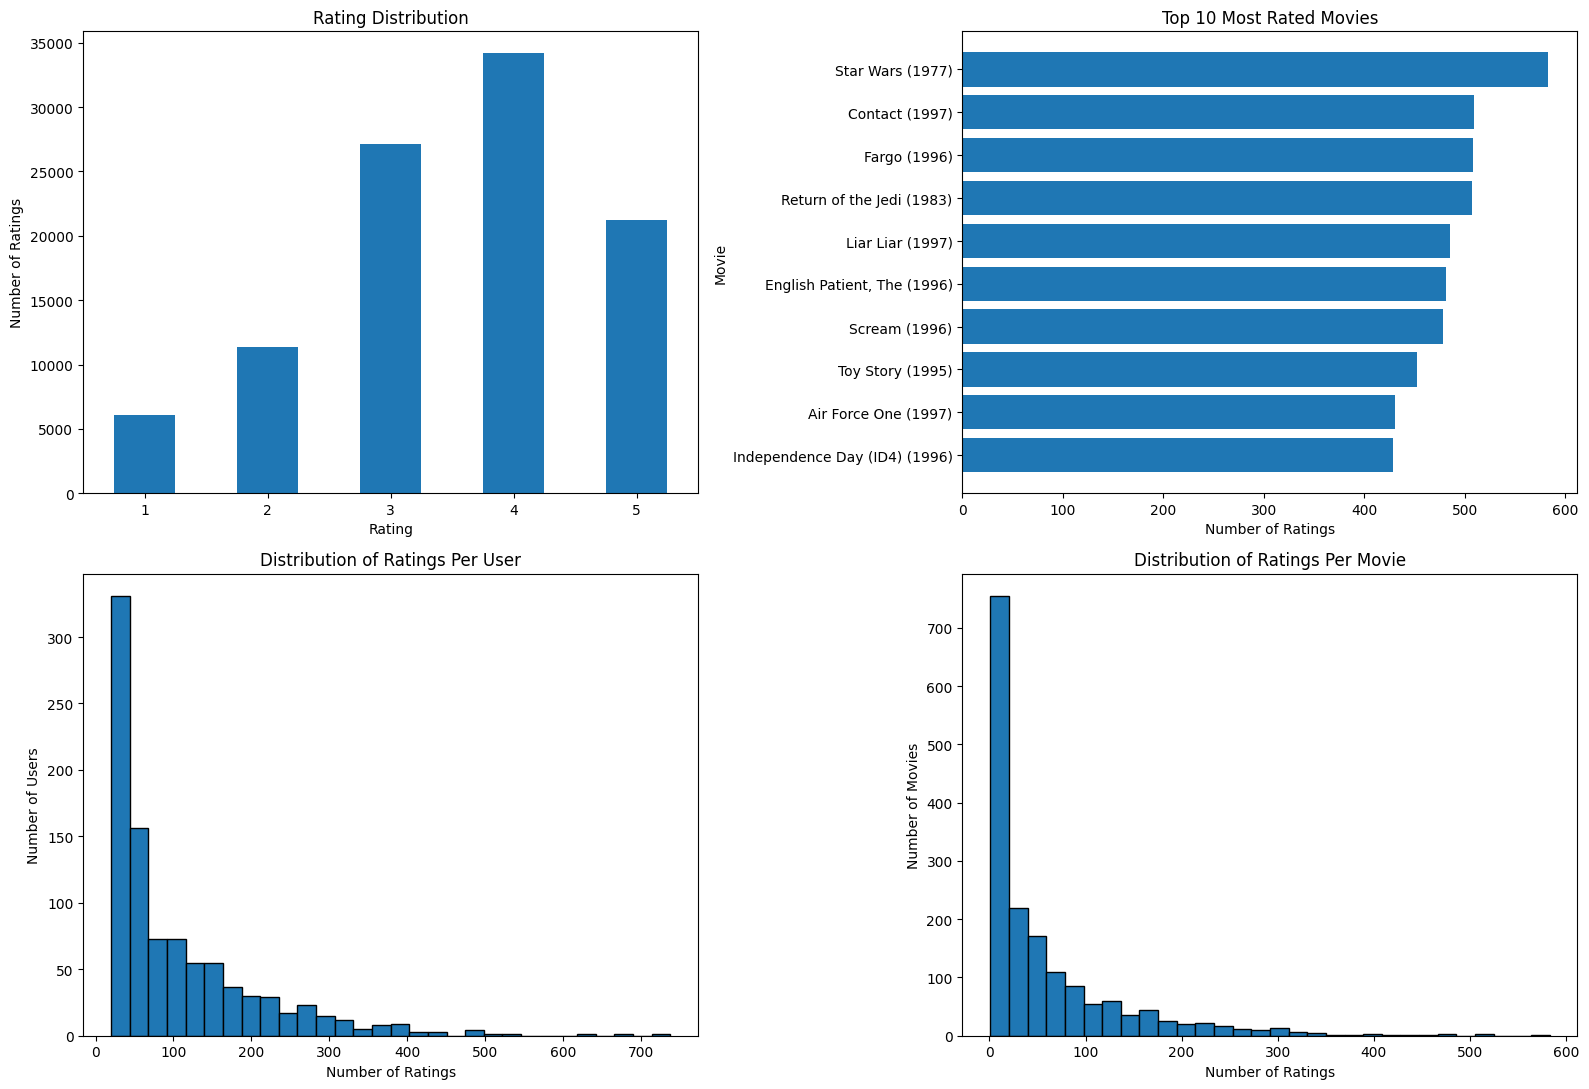


[7] Rating Distribution Percentages


,percentage
rating,
1,6.11
2,11.37
3,27.15
4,34.17
5,21.20



[8] User-Item Matrix Characteristics
Matrix dimensions: 943 users × 1682 movies
Observed interactions: 100,000
Missing interactions: 1,486,126
Sparsity: 93.70%

EDA completed successfully.


In [2]:
# ============================================================
# MovieMind AI — Phase 2: Exploratory Data Analysis
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Prepare analysis tables
ratings_analysis = ratings.merge(
    movies[["movie_id", "title"]],
    on="movie_id",
    how="left",
    validate="many_to_one"
)

ratings_per_user = ratings.groupby("user_id")["rating"].count()

ratings_per_movie = ratings.groupby("movie_id")["rating"].count()

average_rating_per_movie = ratings.groupby("movie_id")["rating"].mean()

movie_statistics = (
    ratings.groupby("movie_id")
    .agg(
        rating_count=("rating", "count"),
        average_rating=("rating", "mean")
    )
    .join(movies.set_index("movie_id")[["title"]])
)

# 2. Dataset overview
n_users = ratings["user_id"].nunique()
n_movies = movies["movie_id"].nunique()
n_ratings = len(ratings)

possible_interactions = n_users * n_movies

sparsity = (
    1 - n_ratings / possible_interactions
) * 100

print("=" * 65)
print("MOVIEMIND AI — EXPLORATORY DATA ANALYSIS")
print("=" * 65)

print("\n[1] Dataset Overview")
print(f"Number of users:             {n_users:,}")
print(f"Number of movies:            {n_movies:,}")
print(f"Number of ratings:           {n_ratings:,}")
print(f"Possible user-movie pairs:   {possible_interactions:,}")
print(f"User-item matrix sparsity:   {sparsity:.2f}%")

print("\n[2] Ratings Per User")
print(ratings_per_user.describe().round(2))

print("\n[3] Ratings Per Movie")
print(ratings_per_movie.describe().round(2))

print("\n[4] Most Rated Movies")
most_rated = (
    movie_statistics
    .sort_values("rating_count", ascending=False)
    .head(10)
)

display(most_rated)

print("\n[5] Highest-Rated Movies")
print("Minimum threshold: 50 ratings")

highest_rated = (
    movie_statistics[movie_statistics["rating_count"] >= 50]
    .sort_values(
        ["average_rating", "rating_count"],
        ascending=[False, False]
    )
    .head(10)
    .copy()
)

highest_rated["average_rating"] = (
    highest_rated["average_rating"].round(2)
)

display(highest_rated)

print("\n[6] Most Active Users")
most_active_users = ratings_per_user.sort_values(
    ascending=False
).head(10)

display(
    most_active_users.rename("number_of_ratings").to_frame()
)

# 3. Rating distribution
rating_distribution = (
    ratings["rating"]
    .value_counts()
    .sort_index()
)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

rating_distribution.plot(
    kind="bar",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Rating Distribution")
axes[0, 0].set_xlabel("Rating")
axes[0, 0].set_ylabel("Number of Ratings")
axes[0, 0].tick_params(axis="x", rotation=0)

# 4. Most rated movies
most_rated_plot = most_rated.sort_values("rating_count")

axes[0, 1].barh(
    most_rated_plot["title"],
    most_rated_plot["rating_count"]
)

axes[0, 1].set_title("Top 10 Most Rated Movies")
axes[0, 1].set_xlabel("Number of Ratings")
axes[0, 1].set_ylabel("Movie")

# 5. Ratings per user
axes[1, 0].hist(
    ratings_per_user,
    bins=30,
    edgecolor="black"
)

axes[1, 0].set_title("Distribution of Ratings Per User")
axes[1, 0].set_xlabel("Number of Ratings")
axes[1, 0].set_ylabel("Number of Users")

# 6. Ratings per movie
axes[1, 1].hist(
    ratings_per_movie,
    bins=30,
    edgecolor="black"
)

axes[1, 1].set_title("Distribution of Ratings Per Movie")
axes[1, 1].set_xlabel("Number of Ratings")
axes[1, 1].set_ylabel("Number of Movies")

plt.tight_layout()
plt.show()

# 7. Additional rating and sparsity statistics
print("\n[7] Rating Distribution Percentages")

rating_percentages = (
    ratings["rating"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(
    rating_percentages.rename("percentage").to_frame()
)

print("\n[8] User-Item Matrix Characteristics")
print(f"Matrix dimensions: {n_users} users × {n_movies} movies")
print(f"Observed interactions: {n_ratings:,}")
print(f"Missing interactions: {possible_interactions - n_ratings:,}")
print(f"Sparsity: {sparsity:.2f}%")

print("\nEDA completed successfully.")

In [4]:
# ============================================================
# MovieMind AI — Phase 3: Data Preparation and Validation
# ============================================================

import numpy as np
import pandas as pd

# 1. Configuration
RANDOM_STATE = 42
TEST_RATIO = 0.20
RELEVANCE_THRESHOLD = 4

# 2. Sort interactions chronologically within each user
ratings_sorted = ratings.sort_values(
    ["user_id", "timestamp", "movie_id"]
).reset_index(drop=True)

# 3. Create a reproducible per-user train-test split
rng = np.random.default_rng(RANDOM_STATE)

train_indices = []
test_indices = []

for user_id, user_data in ratings_sorted.groupby("user_id"):
    user_indices = user_data.index.to_numpy()
    n_interactions = len(user_indices)

    if n_interactions < 2:
        train_indices.extend(user_indices.tolist())
        continue

    n_test = max(1, int(np.floor(n_interactions * TEST_RATIO)))
    n_test = min(n_test, n_interactions - 1)

    selected_test = rng.choice(
        user_indices,
        size=n_test,
        replace=False
    )

    selected_test_set = set(selected_test.tolist())

    for idx in user_indices:
        if idx in selected_test_set:
            test_indices.append(idx)
        else:
            train_indices.append(idx)

# 4. Build training and test sets
train_ratings = ratings_sorted.loc[train_indices].copy()
test_ratings = ratings_sorted.loc[test_indices].copy()

train_ratings.reset_index(drop=True, inplace=True)
test_ratings.reset_index(drop=True, inplace=True)

# 5. Validate train-test separation
train_pairs = set(
    zip(train_ratings["user_id"], train_ratings["movie_id"])
)

test_pairs = set(
    zip(test_ratings["user_id"], test_ratings["movie_id"])
)

overlapping_pairs = train_pairs.intersection(test_pairs)

train_user_counts = train_ratings.groupby("user_id").size()
test_user_counts = test_ratings.groupby("user_id").size()

# 6. Create the user-item matrix using training data only
user_item_matrix = train_ratings.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
)

# 7. Identify relevant held-out ratings
test_relevant = test_ratings[
    test_ratings["rating"] >= RELEVANCE_THRESHOLD
].copy()

# 8. Calculate matrix statistics
observed_ratings = int(user_item_matrix.notna().sum().sum())

total_matrix_cells = (
    user_item_matrix.shape[0] * user_item_matrix.shape[1]
)

missing_entries = total_matrix_cells - observed_ratings

matrix_sparsity = (
    missing_entries / total_matrix_cells * 100
)

# 9. Display results
print("=" * 65)
print("MOVIEMIND AI — TRAIN-TEST SPLIT VALIDATION")
print("=" * 65)

print("\n[1] Dataset Split")
print(f"Total interactions: {len(ratings):,}")
print(f"Training interactions: {len(train_ratings):,}")
print(f"Test interactions: {len(test_ratings):,}")
print(f"Training percentage: {len(train_ratings) / len(ratings) * 100:.2f}%")
print(f"Test percentage: {len(test_ratings) / len(ratings) * 100:.2f}%")

print("\n[2] User Coverage")
print(f"Original users: {ratings['user_id'].nunique():,}")
print(f"Training users: {train_ratings['user_id'].nunique():,}")
print(f"Test users: {test_ratings['user_id'].nunique():,}")

print("\n[3] Training History")
print(f"Minimum ratings per user: {train_user_counts.min()}")
print(f"Average ratings per user: {train_user_counts.mean():.2f}")
print(f"Maximum ratings per user: {train_user_counts.max()}")

print("\n[4] Relevant Test Interactions")
print(f"Relevance threshold: {RELEVANCE_THRESHOLD}")
print(f"Relevant test ratings: {len(test_relevant):,}")
print(f"Users with relevant test movies: {test_relevant['user_id'].nunique():,}")

print("\n[5] User-Item Matrix")
print(f"Matrix shape: {user_item_matrix.shape}")
print(f"Observed training ratings: {observed_ratings:,}")
print(f"Missing entries: {missing_entries:,}")
print(f"Matrix sparsity: {matrix_sparsity:.2f}%")

print("\n[6] Integrity Checks")
print(f"Overlapping train-test pairs: {len(overlapping_pairs)}")
print(f"All users have training history: {bool((train_user_counts >= 1).all())}")
print(f"All training ratings valid: {bool(train_ratings['rating'].between(1, 5).all())}")
print(f"All test ratings valid: {bool(test_ratings['rating'].between(1, 5).all())}")

assert len(overlapping_pairs) == 0
assert train_ratings["user_id"].nunique() == ratings["user_id"].nunique()
assert (train_user_counts >= 1).all()

print("\nTrain-test split completed successfully.")


MOVIEMIND AI — TRAIN-TEST SPLIT VALIDATION

[1] Dataset Split
Total interactions: 100,000
Training interactions: 80,367
Test interactions: 19,633
Training percentage: 80.37%
Test percentage: 19.63%

[2] User Coverage
Original users: 943
Training users: 943
Test users: 943

[3] Training History
Minimum ratings per user: 16
Average ratings per user: 85.22
Maximum ratings per user: 590

[4] Relevant Test Interactions
Relevance threshold: 4
Relevant test ratings: 10,886
Users with relevant test movies: 928

[5] User-Item Matrix
Matrix shape: (943, 1650)
Observed training ratings: 80,367
Missing entries: 1,475,583
Matrix sparsity: 94.83%

[6] Integrity Checks
Overlapping train-test pairs: 0
All users have training history: True
All training ratings valid: True
All test ratings valid: True

Train-test split completed successfully.


In [5]:

# ============================================================
# MovieMind AI — Popularity-Based Recommendation Baseline
# ============================================================

import numpy as np
import pandas as pd

MIN_RATINGS = 50
TOP_N = 10

# Calculate movie-level statistics using training data only
movie_stats = (
    train_ratings
    .groupby("movie_id")
    .agg(
        rating_count=("rating", "count"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

# Bayesian average to reduce the impact of movies
# with very few ratings
global_mean = train_ratings["rating"].mean()

C = MIN_RATINGS

movie_stats["weighted_rating"] = (
    (movie_stats["rating_count"] /
     (movie_stats["rating_count"] + C))
    * movie_stats["average_rating"]
    +
    (C /
     (movie_stats["rating_count"] + C))
    * global_mean
)

# Sort movies by weighted rating
popular_movies = movie_stats.sort_values(
    by=["weighted_rating", "rating_count"],
    ascending=False
).reset_index(drop=True)

# Attach movie titles
movie_recommendations = popular_movies.merge(
    movies[["movie_id", "title"]],
    on="movie_id",
    how="left"
)

print("=" * 65)
print("MOVIEMIND AI — POPULARITY-BASED BASELINE")
print("=" * 65)

print(f"\nTraining interactions: {len(train_ratings):,}")
print(f"Global average rating: {global_mean:.4f}")
print(f"Minimum ratings threshold: {MIN_RATINGS}")

print("\n[TOP 10 POPULAR MOVIES]")
print(
    movie_recommendations[
        ["title", "rating_count", "average_rating", "weighted_rating"]
    ].head(TOP_N).to_string(index=False)
)

print("\n[MODEL VALIDATION]")
print("Movies included:", len(popular_movies))
print(
    "Movies meeting minimum rating threshold:",
    int((movie_stats["rating_count"] >= MIN_RATINGS).sum())
)
print(
    "Missing movie titles:",
    int(movie_recommendations["title"].isna().sum())
)

assert not movie_recommendations["title"].isna().any()
assert movie_recommendations["weighted_rating"].notna().all()

print("\nPopularity baseline created successfully.")


MOVIEMIND AI — POPULARITY-BASED BASELINE

Training interactions: 80,367
Global average rating: 3.5290
Minimum ratings threshold: 50

[TOP 10 POPULAR MOVIES]
                           title  rating_count  average_rating  weighted_rating
Shawshank Redemption, The (1994)           226        4.477876         4.305978
         Schindler's List (1993)           238        4.449580         4.289757
               Casablanca (1942)           195        4.466667         4.275306
                Star Wars (1977)           456        4.348684         4.267688
      Usual Suspects, The (1995)           207        4.410628         4.239105
Silence of the Lambs, The (1991)           307        4.325733         4.214145
           Godfather, The (1972)           325        4.295385         4.193200
              Rear Window (1954)           165        4.393939         4.192790
           Close Shave, A (1995)            94        4.478723         4.148958
                  Titanic (1997)           

In [6]:

# ============================================================
# MovieMind AI — Popularity Baseline Evaluation
# Precision@K and Recall@K
# ============================================================

import numpy as np
import pandas as pd

K_VALUES = [5, 10]
RELEVANCE_THRESHOLD = 4

# Relevant movies for each user in the test set
relevant_items = (
    test_ratings[test_ratings["rating"] >= RELEVANCE_THRESHOLD]
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# Movies already rated by each user in training
seen_items = (
    train_ratings.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# Popularity ranking: only movies with at least MIN_RATINGS
# training interactions
popular_ranking = popular_movies.loc[
    popular_movies["rating_count"] >= MIN_RATINGS,
    "movie_id"
].tolist()

evaluation_users = list(relevant_items.keys())

results = []

for user_id in evaluation_users:

    user_seen = seen_items.get(user_id, set())
    user_relevant = relevant_items[user_id]

    # Recommend only movies unseen by this user
    recommendations = [
        movie_id
        for movie_id in popular_ranking
        if movie_id not in user_seen
    ]

    for k in K_VALUES:

        top_k = recommendations[:k]

        hits = len(set(top_k) & user_relevant)

        precision = hits / k
        recall = hits / len(user_relevant)

        results.append({
            "user_id": user_id,
            "K": k,
            "hits": hits,
            "precision": precision,
            "recall": recall
        })

results_df = pd.DataFrame(results)

evaluation_summary = (
    results_df.groupby("K")
    .agg(
        precision_at_k=("precision", "mean"),
        recall_at_k=("recall", "mean"),
        average_hits=("hits", "mean")
    )
    .reset_index()
)

print("=" * 65)
print("MOVIEMIND AI — POPULARITY BASELINE EVALUATION")
print("=" * 65)

print("\n[Evaluation Configuration]")
print("Relevant rating threshold:", RELEVANCE_THRESHOLD)
print("Minimum movie ratings:", MIN_RATINGS)
print("Eligible users:", len(evaluation_users))
print("K values:", K_VALUES)

print("\n[Evaluation Results]")
print(evaluation_summary.to_string(index=False))

print("\n[Validation]")
print("Total evaluation records:", len(results_df))
print("Missing metric values:", results_df.isna().sum().sum())
print("All precision values valid:",
      results_df["precision"].between(0, 1).all())
print("All recall values valid:",
      results_df["recall"].between(0, 1).all())

assert len(results_df) == len(evaluation_users) * len(K_VALUES)
assert results_df["precision"].between(0, 1).all()
assert results_df["recall"].between(0, 1).all()

print("\nPopularity baseline evaluation completed successfully.")


MOVIEMIND AI — POPULARITY BASELINE EVALUATION

[Evaluation Configuration]
Relevant rating threshold: 4
Minimum movie ratings: 50
Eligible users: 928
K values: [5, 10]

[Evaluation Results]
 K  precision_at_k  recall_at_k  average_hits
 5        0.113362     0.043067      0.566810
10        0.096767     0.078873      0.967672

[Validation]
Total evaluation records: 1856
Missing metric values: 0
All precision values valid: True
All recall values valid: True

Popularity baseline evaluation completed successfully.


In [7]:

# ============================================================
# MovieMind AI — User-Based Collaborative Filtering
# Step 1: User Similarity Matrix
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Fill missing ratings with zero for similarity calculation
user_item_filled = user_item_matrix.fillna(0)

# Calculate cosine similarity between users
user_similarity = cosine_similarity(user_item_filled)

# Convert to DataFrame for easier inspection
user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

print("=" * 65)
print("MOVIEMIND AI — USER SIMILARITY ANALYSIS")
print("=" * 65)

print("\n[Similarity Matrix]")
print("Matrix shape:", user_similarity_df.shape)

print("\n[Similarity Statistics]")

similarity_values = user_similarity[
    np.triu_indices_from(user_similarity, k=1)
]

print(f"Minimum similarity: {similarity_values.min():.4f}")
print(f"Maximum similarity: {similarity_values.max():.4f}")
print(f"Average similarity: {similarity_values.mean():.4f}")
print(f"Median similarity: {np.median(similarity_values):.4f}")

# Inspect nearest users for one sample user
sample_user_id = user_item_matrix.index[0]

nearest_users = (
    user_similarity_df.loc[sample_user_id]
    .drop(sample_user_id)
    .sort_values(ascending=False)
    .head(5)
)

print(f"\n[Top 5 Similar Users to User {sample_user_id}]")
print(nearest_users.to_string())

print("\n[Validation]")
print("All similarity values finite:",
      np.isfinite(user_similarity).all())
print("Similarity matrix symmetric:",
      np.allclose(user_similarity, user_similarity.T))
print("Diagonal values equal 1:",
      np.allclose(np.diag(user_similarity), 1.0))

assert user_similarity.shape == (
    user_item_matrix.shape[0],
    user_item_matrix.shape[0]
)
assert np.isfinite(user_similarity).all()
assert np.allclose(user_similarity, user_similarity.T)

print("\nUser similarity calculation completed successfully.")


MOVIEMIND AI — USER SIMILARITY ANALYSIS

[Similarity Matrix]
Matrix shape: (943, 943)

[Similarity Statistics]
Minimum similarity: 0.0000
Maximum similarity: 0.6713
Average similarity: 0.1389
Median similarity: 0.1224

[Top 5 Similar Users to User 1]
user_id
916    0.497242
303    0.478181
868    0.469252
435    0.453390
521    0.451634

[Validation]
All similarity values finite: True
Similarity matrix symmetric: True
Diagonal values equal 1: True

User similarity calculation completed successfully.


In [11]:

# ============================================================
# MovieMind AI — Prediction Range Diagnostic
# ============================================================

predictions = sample_recommendations["predicted_rating"]

print("=" * 65)
print("MOVIEMIND AI — PREDICTION DIAGNOSTICS")
print("=" * 65)

print("\n[Prediction Statistics]")
print("Minimum:", predictions.min())
print("Maximum:", predictions.max())
print("Average:", predictions.mean())

print("\n[Values Outside Valid Rating Range]")
invalid_predictions = sample_recommendations[
    ~sample_recommendations["predicted_rating"].between(1, 5)
]

print("Invalid predictions:", len(invalid_predictions))

if not invalid_predictions.empty:
    print(invalid_predictions.to_string(index=False))

print("\n[Neighbor Similarity Diagnostics]")

sample_neighbors = (
    user_similarity_df.loc[SAMPLE_USER_ID]
    .drop(SAMPLE_USER_ID)
    .nlargest(N_NEIGHBORS)
)

print("Minimum selected similarity:", sample_neighbors.min())
print("Maximum selected similarity:", sample_neighbors.max())
print("All selected similarities positive:",
      (sample_neighbors > 0).all())

print("\n[Weighted Rating Diagnostics]")

print("Training rating minimum:", train_ratings["rating"].min())
print("Training rating maximum:", train_ratings["rating"].max())

print("\n[Data Types]")
print(sample_recommendations.dtypes)


MOVIEMIND AI — PREDICTION DIAGNOSTICS

[Prediction Statistics]
Minimum: 4.597058923465278
Maximum: 5.000000000000001
Average: 4.807355115264469

[Values Outside Valid Rating Range]
Invalid predictions: 1
 movie_id                  title  predicted_rating  neighbor_count
      512 Wings of Desire (1987)               5.0               3

[Neighbor Similarity Diagnostics]
Minimum selected similarity: 0.4219623766987082
Maximum selected similarity: 0.49724208585934426
All selected similarities positive: True

[Weighted Rating Diagnostics]
Training rating minimum: 1
Training rating maximum: 5

[Data Types]
movie_id              int64
title                object
predicted_rating    float64
neighbor_count        int64
dtype: object


In [12]:

# ============================================================
# MovieMind AI — User-Based Collaborative Filtering
# Step 2: Improved Recommendation Engine
# ============================================================

import numpy as np
import pandas as pd

# Configuration
N_NEIGHBORS = 20
TOP_N = 10
MIN_NEIGHBOR_SUPPORT = 2
SAMPLE_USER_ID = 1


# ------------------------------------------------------------
# Recommendation Function
# ------------------------------------------------------------

def recommend_user_based(
    user_id,
    n_neighbors=20,
    top_n=10,
    min_neighbor_support=2
):

    if user_id not in user_similarity_df.index:
        raise ValueError(f"User {user_id} does not exist.")

    # Find the most similar users
    similarities = user_similarity_df.loc[user_id].drop(user_id)

    # Select top similar users
    neighbors = similarities.nlargest(n_neighbors)

    # Keep only positive similarity weights
    neighbors = neighbors[neighbors > 0]

    if neighbors.empty:
        return pd.DataFrame(
            columns=[
                "movie_id",
                "title",
                "predicted_rating",
                "neighbor_count"
            ]
        )

    # Get movies already rated by the target user
    user_seen = set(
        train_ratings.loc[
            train_ratings["user_id"] == user_id,
            "movie_id"
        ]
    )

    # Collect ratings from similar users
    neighbor_ratings = train_ratings[
        train_ratings["user_id"].isin(neighbors.index)
    ].copy()

    # Exclude movies already rated by target user
    candidate_ratings = neighbor_ratings[
        ~neighbor_ratings["movie_id"].isin(user_seen)
    ].copy()

    # Attach similarity weights
    candidate_ratings["similarity"] = (
        candidate_ratings["user_id"].map(neighbors)
    )

    # Calculate weighted ratings
    candidate_ratings["weighted_rating"] = (
        candidate_ratings["rating"] *
        candidate_ratings["similarity"]
    )

    # Aggregate predictions per movie
    recommendations = (
        candidate_ratings
        .groupby("movie_id")
        .agg(
            weighted_sum=("weighted_rating", "sum"),
            similarity_sum=("similarity", "sum"),
            neighbor_count=("user_id", "nunique")
        )
        .reset_index()
    )

    # Require minimum neighbor support
    recommendations = recommendations[
        recommendations["neighbor_count"] >= min_neighbor_support
    ].copy()

    if recommendations.empty:
        return pd.DataFrame(
            columns=[
                "movie_id",
                "title",
                "predicted_rating",
                "neighbor_count"
            ]
        )

    # Calculate weighted predicted rating
    recommendations["predicted_rating"] = (
        recommendations["weighted_sum"] /
        recommendations["similarity_sum"]
    ).clip(1.0, 5.0)

    # Attach movie titles
    recommendations = recommendations.merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )

    # Sort recommendations
    recommendations = recommendations.sort_values(
        ["predicted_rating", "neighbor_count"],
        ascending=False
    ).head(top_n)

    return recommendations[
        [
            "movie_id",
            "title",
            "predicted_rating",
            "neighbor_count"
        ]
    ].reset_index(drop=True)


# ------------------------------------------------------------
# Generate Recommendations for Sample User
# ------------------------------------------------------------

sample_recommendations = recommend_user_based(
    user_id=SAMPLE_USER_ID,
    n_neighbors=N_NEIGHBORS,
    top_n=TOP_N,
    min_neighbor_support=MIN_NEIGHBOR_SUPPORT
)


# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=" * 65)
print("MOVIEMIND AI — IMPROVED USER-BASED RECOMMENDATIONS")
print("=" * 65)

print(f"\nTarget User: {SAMPLE_USER_ID}")
print(f"Number of Neighbors: {N_NEIGHBORS}")
print(f"Minimum Neighbor Support: {MIN_NEIGHBOR_SUPPORT}")
print(f"Requested Recommendations: {TOP_N}")

print("\n[TOP RECOMMENDED MOVIES]")

if not sample_recommendations.empty:
    print(sample_recommendations.to_string(index=False))
else:
    print("No recommendations available.")


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\n[VALIDATION]")

sample_seen = set(
    train_ratings.loc[
        train_ratings["user_id"] == SAMPLE_USER_ID,
        "movie_id"
    ]
)

recommended_ids = set(sample_recommendations["movie_id"])

duplicate_count = sample_recommendations["movie_id"].duplicated().sum()

previously_seen_count = len(
    sample_seen.intersection(recommended_ids)
)

valid_rating_range = (
    sample_recommendations["predicted_rating"]
    .between(1.0, 5.0)
    .all()
)

valid_neighbor_support = (
    sample_recommendations["neighbor_count"]
    .ge(MIN_NEIGHBOR_SUPPORT)
    .all()
)

valid_titles = sample_recommendations["title"].notna().all()

print("Recommendations generated:", len(sample_recommendations))
print("Duplicate movie IDs:", duplicate_count)
print("Previously rated movies included:", previously_seen_count)
print("Predicted ratings within [1, 5]:", valid_rating_range)
print("Minimum neighbor support satisfied:", valid_neighbor_support)
print("All movie titles available:", valid_titles)


# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert sample_recommendations["movie_id"].is_unique
assert previously_seen_count == 0
assert valid_rating_range
assert valid_neighbor_support
assert valid_titles

print("\nUser-based recommendation engine completed successfully.")


MOVIEMIND AI — IMPROVED USER-BASED RECOMMENDATIONS

Target User: 1
Number of Neighbors: 20
Minimum Neighbor Support: 2
Requested Recommendations: 10

[TOP RECOMMENDED MOVIES]
 movie_id                       title  predicted_rating  neighbor_count
      340        Boogie Nights (1997)          5.000000               3
      512      Wings of Desire (1987)          5.000000               3
      853            Braindead (1992)          5.000000               2
      285       Secrets & Lies (1996)          5.000000               2
      313              Titanic (1997)          4.798723               5
      518    Miller's Crossing (1990)          4.749356               4
       59    Three Colors: Red (1994)          4.664521               3
      286 English Patient, The (1996)          4.638635               3
      483           Casablanca (1942)          4.625257              13
      302    L.A. Confidential (1997)          4.597059               5

[VALIDATION]
Recommendations gen

In [14]:

# ============================================================
# MovieMind AI — User-Based Collaborative Filtering
# Step 3: Full Model Evaluation
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

K_VALUES = [5, 10]
N_NEIGHBORS = 20
MIN_NEIGHBOR_SUPPORT = 2
RELEVANCE_THRESHOLD = 4

# ------------------------------------------------------------
# Prepare Evaluation Data
# ------------------------------------------------------------

relevant_items = (
    test_ratings[test_ratings["rating"] >= RELEVANCE_THRESHOLD]
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

seen_items = (
    train_ratings.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

ratings_by_user = {
    user_id: group.copy()
    for user_id, group in train_ratings.groupby("user_id")
}

evaluation_users = list(relevant_items.keys())

# ------------------------------------------------------------
# Evaluation Function
# ------------------------------------------------------------

def evaluate_user_based():

    evaluation_results = []

    for user_id in evaluation_users:

        # Find nearest neighbors
        similarities = user_similarity_df.loc[user_id].drop(user_id)

        neighbors = similarities.nlargest(N_NEIGHBORS)
        neighbors = neighbors[neighbors > 0]

        # Collect ratings from neighbors
        neighbor_frames = [
            ratings_by_user[neighbor_id].assign(
                similarity=similarity
            )
            for neighbor_id, similarity in neighbors.items()
            if neighbor_id in ratings_by_user
        ]

        if not neighbor_frames:
            recommendations = []

        else:
            neighbor_ratings = pd.concat(
                neighbor_frames,
                ignore_index=True
            )

            # Exclude previously rated movies
            user_seen = seen_items.get(user_id, set())

            candidates = neighbor_ratings[
                ~neighbor_ratings["movie_id"].isin(user_seen)
            ].copy()

            if candidates.empty:
                recommendations = []

            else:
                candidates["weighted_rating"] = (
                    candidates["rating"] *
                    candidates["similarity"]
                )

                # Aggregate movie scores
                scores = (
                    candidates
                    .groupby("movie_id")
                    .agg(
                        weighted_sum=("weighted_rating", "sum"),
                        similarity_sum=("similarity", "sum"),
                        neighbor_count=("user_id", "nunique")
                    )
                    .reset_index()
                )

                # Minimum neighbor support
                scores = scores[
                    scores["neighbor_count"] >= MIN_NEIGHBOR_SUPPORT
                ].copy()

                if scores.empty:
                    recommendations = []

                else:
                    scores["predicted_rating"] = (
                        scores["weighted_sum"] /
                        scores["similarity_sum"]
                    ).clip(1.0, 5.0)

                    scores = scores.sort_values(
                        ["predicted_rating", "neighbor_count"],
                        ascending=False
                    )

                    recommendations = scores["movie_id"].tolist()

        # Evaluate at each K
        user_relevant = relevant_items[user_id]

        for k in K_VALUES:

            top_k = recommendations[:k]

            hits = len(set(top_k) & user_relevant)

            precision = hits / k
            recall = hits / len(user_relevant)

            evaluation_results.append({
                "user_id": user_id,
                "K": k,
                "hits": hits,
                "precision": precision,
                "recall": recall,
                "recommendation_count": len(recommendations)
            })

    return pd.DataFrame(evaluation_results)


# ------------------------------------------------------------
# Run Evaluation
# ------------------------------------------------------------

user_based_results = evaluate_user_based()

# ------------------------------------------------------------
# Aggregate Metrics
# ------------------------------------------------------------

user_based_summary = (
    user_based_results
    .groupby("K")
    .agg(
        precision_at_k=("precision", "mean"),
        recall_at_k=("recall", "mean"),
        average_hits=("hits", "mean"),
        average_available_recommendations=("recommendation_count", "mean")
    )
    .reset_index()
)

print("=" * 70)
print("MOVIEMIND AI — USER-BASED MODEL EVALUATION")
print("=" * 70)

print("\n[Evaluation Configuration]")
print("Eligible users:", len(evaluation_users))
print("Relevant rating threshold:", RELEVANCE_THRESHOLD)
print("Number of neighbors:", N_NEIGHBORS)
print("Minimum neighbor support:", MIN_NEIGHBOR_SUPPORT)
print("K values:", K_VALUES)

print("\n[Evaluation Results]")
print(user_based_summary.to_string(index=False))

# ------------------------------------------------------------
# Compare Against Popularity Baseline
# ------------------------------------------------------------

baseline_metrics = pd.DataFrame({
    "K": [5, 10],
    "baseline_precision": [0.113362, 0.096767],
    "baseline_recall": [0.043067, 0.078873]
})

comparison = user_based_summary.merge(
    baseline_metrics,
    on="K"
)

comparison["precision_improvement"] = (
    comparison["precision_at_k"] -
    comparison["baseline_precision"]
)

comparison["recall_improvement"] = (
    comparison["recall_at_k"] -
    comparison["baseline_recall"]
)

print("\n[USER-BASED vs POPULARITY BASELINE]")

comparison_columns = [
    "K",
    "precision_at_k",
    "baseline_precision",
    "precision_improvement",
    "recall_at_k",
    "baseline_recall",
    "recall_improvement"
]

print(comparison[comparison_columns].to_string(index=False))

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\n[VALIDATION]")

print("Total evaluation records:", len(user_based_results))
print(
    "Expected evaluation records:",
    len(evaluation_users) * len(K_VALUES)
)
print(
    "Missing metric values:",
    user_based_results.isna().sum().sum()
)

print(
    "All precision values valid:",
    user_based_results["precision"].between(0, 1).all()
)

print(
    "All recall values valid:",
    user_based_results["recall"].between(0, 1).all()
)

assert len(user_based_results) == len(evaluation_users) * len(K_VALUES)
assert user_based_results["precision"].between(0, 1).all()
assert user_based_results["recall"].between(0, 1).all()

print("\nUser-based model evaluation completed successfully.")


MOVIEMIND AI — USER-BASED MODEL EVALUATION

[Evaluation Configuration]
Eligible users: 928
Relevant rating threshold: 4
Number of neighbors: 20
Minimum neighbor support: 2
K values: [5, 10]

[Evaluation Results]
 K  precision_at_k  recall_at_k  average_hits  average_available_recommendations
 5        0.061638     0.045297      0.308190                         335.894397
10        0.072091     0.095463      0.720905                         335.894397

[USER-BASED vs POPULARITY BASELINE]
 K  precision_at_k  baseline_precision  precision_improvement  recall_at_k  baseline_recall  recall_improvement
 5        0.061638            0.113362              -0.051724     0.045297         0.043067             0.00223
10        0.072091            0.096767              -0.024676     0.095463         0.078873             0.01659

[VALIDATION]
Total evaluation records: 1856
Expected evaluation records: 1856
Missing metric values: 0
All precision values valid: True
All recall values valid: True

User

In [15]:

# ============================================================
# MovieMind AI — Item-Based Collaborative Filtering
# Step 1: Item Similarity Matrix
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Transpose user-item matrix:
# Rows = Movies, Columns = Users
item_user_matrix = user_item_matrix.T.fillna(0)

# Calculate cosine similarity between movies
item_similarity = cosine_similarity(item_user_matrix)

# Convert to DataFrame
item_similarity_df = pd.DataFrame(
    item_similarity,
    index=item_user_matrix.index,
    columns=item_user_matrix.index
)

print("=" * 70)
print("MOVIEMIND AI — ITEM SIMILARITY ANALYSIS")
print("=" * 70)

print("\n[Similarity Matrix]")
print("Matrix shape:", item_similarity_df.shape)

# Extract upper triangle without diagonal
similarity_values = item_similarity[
    np.triu_indices_from(item_similarity, k=1)
]

print("\n[Similarity Statistics]")
print(f"Minimum similarity: {similarity_values.min():.4f}")
print(f"Maximum similarity: {similarity_values.max():.4f}")
print(f"Average similarity: {similarity_values.mean():.4f}")
print(f"Median similarity: {np.median(similarity_values):.4f}")

# Inspect similar movies for a sample movie
sample_movie_id = 50

similar_movies = (
    item_similarity_df.loc[sample_movie_id]
    .drop(sample_movie_id)
    .sort_values(ascending=False)
    .head(10)
)

# Attach movie titles
similar_movies_df = similar_movies.rename(
    "similarity"
).reset_index()

similar_movies_df = similar_movies_df.merge(
    movies[["movie_id", "title"]],
    on="movie_id",
    how="left"
)

print(f"\n[Top 10 Similar Movies to Movie ID {sample_movie_id}]")

sample_title = movies.loc[
    movies["movie_id"] == sample_movie_id,
    "title"
].iloc[0]

print("Reference movie:", sample_title)
print(
    similar_movies_df[
        ["movie_id", "title", "similarity"]
    ].to_string(index=False)
)

print("\n[Validation]")

print("All similarity values finite:",
      np.isfinite(item_similarity).all())

print("Similarity matrix symmetric:",
      np.allclose(item_similarity, item_similarity.T))

print("Diagonal values equal 1:",
      np.allclose(np.diag(item_similarity), 1.0))

assert item_similarity.shape == (
    item_user_matrix.shape[0],
    item_user_matrix.shape[0]
)

assert np.isfinite(item_similarity).all()
assert np.allclose(item_similarity, item_similarity.T)
assert np.allclose(np.diag(item_similarity), 1.0)

print("\nItem similarity calculation completed successfully.")


MOVIEMIND AI — ITEM SIMILARITY ANALYSIS

[Similarity Matrix]
Matrix shape: (1650, 1650)

[Similarity Statistics]
Minimum similarity: 0.0000
Maximum similarity: 1.0000
Average similarity: 0.0708
Median similarity: 0.0407

[Top 10 Similar Movies to Movie ID 50]
Reference movie: Star Wars (1977)
 movie_id                                     title  similarity
      181                 Return of the Jedi (1983)    0.694124
      172           Empire Strikes Back, The (1980)    0.611089
        1                          Toy Story (1995)    0.595336
      174            Raiders of the Lost Ark (1981)    0.580211
      210 Indiana Jones and the Last Crusade (1989)    0.571464
      222           Star Trek: First Contact (1996)    0.555411
      204                 Back to the Future (1985)    0.553908
      121             Independence Day (ID4) (1996)    0.548076
      127                     Godfather, The (1972)    0.544405
      173                Princess Bride, The (1987)    0.537116

[

In [16]:

import numpy as np
import pandas as pd

def recommend_item_based(user_id, top_n=10, min_support=2):

    # Validate user
    if user_id not in user_item_matrix.index:
        raise ValueError(f"User ID {user_id} does not exist.")

    # Get movies rated by this user in training data
    user_ratings = user_item_matrix.loc[user_id].dropna()

    if user_ratings.empty:
        return pd.DataFrame(
            columns=["movie_id", "title", "predicted_rating", "support"]
        )

    # Movies already rated by the user
    seen_movies = set(user_ratings.index)

    # Calculate recommendation scores
    scores = {}
    supports = {}

    for candidate_movie in item_user_matrix.index:

        # Exclude already rated movies
        if candidate_movie in seen_movies:
            continue

        # Similarities between candidate and user's rated movies
        similarities = item_similarity_df.loc[
            candidate_movie, user_ratings.index
        ]

        # Keep only positive similarities
        similarities = similarities[similarities > 0]

        # Require minimum support
        if len(similarities) < min_support:
            continue

        # Corresponding ratings
        ratings = user_ratings.loc[similarities.index]

        # Similarity-weighted rating prediction
        predicted_rating = np.dot(
            similarities.values,
            ratings.values
        ) / similarities.sum()

        # Store results
        scores[candidate_movie] = predicted_rating
        supports[candidate_movie] = len(similarities)

    # No recommendations available
    if not scores:
        return pd.DataFrame(
            columns=["movie_id", "title", "predicted_rating", "support"]
        )

    # Build recommendations DataFrame
    recommendations = pd.DataFrame({
        "movie_id": list(scores.keys()),
        "predicted_rating": list(scores.values()),
        "support": [supports[movie_id] for movie_id in scores]
    })

    # Keep predictions within valid rating range
    recommendations["predicted_rating"] = (
        recommendations["predicted_rating"].clip(1, 5)
    )

    # Add movie titles
    recommendations = recommendations.merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )

    # Sort by predicted rating and support
    recommendations = recommendations.sort_values(
        by=["predicted_rating", "support"],
        ascending=[False, False]
    )

    return recommendations[
        ["movie_id", "title", "predicted_rating", "support"]
    ].head(top_n).reset_index(drop=True)


# Test the recommendation engine
sample_user_id = 1

item_recommendations = recommend_item_based(
    user_id=sample_user_id,
    top_n=10,
    min_support=2
)

print("=" * 70)
print("MOVIEMIND AI — ITEM-BASED RECOMMENDATIONS")
print("=" * 70)

print(f"\nUser ID: {sample_user_id}")
print(f"Movies rated in training: {user_item_matrix.loc[sample_user_id].count()}")

print("\n[Top 10 Recommendations]")
print(item_recommendations.to_string(index=False))

print("\n[Validation]")

seen_movies = set(
    user_item_matrix.loc[sample_user_id].dropna().index
)

print("Recommendations count:", len(item_recommendations))
print("No previously rated movies:",
      not item_recommendations["movie_id"].isin(seen_movies).any())
print("No duplicate recommendations:",
      not item_recommendations["movie_id"].duplicated().any())
print("Predictions within [1, 5]:",
      item_recommendations["predicted_rating"].between(1, 5).all())
print("Minimum support satisfied:",
      (item_recommendations["support"] >= 2).all())
print("All titles available:",
      item_recommendations["title"].notna().all())


MOVIEMIND AI — ITEM-BASED RECOMMENDATIONS

User ID: 1
Movies rated in training: 218

[Top 10 Recommendations]
 movie_id                                                                        title  predicted_rating  support
     1354                                                         Venice/Venice (1992)          4.535824        9
     1420                                          Gilligan's Island: The Movie (1998)          4.443713       14
     1158                                       Fille seule, La (A Single Girl) (1995)          4.275233       44
     1601                                                         Office Killer (1997)          4.272027       25
     1507                                        Three Lives and Only One Death (1996)          4.261167       72
     1593                                                    Death in Brunswick (1991)          4.259380       52
     1332 My Life and Times With Antonin Artaud (En compagnie d'Antonin Artaud) (1993)      

In [17]:

# ============================================================
# MOVIEMIND AI — ITEM-BASED MODEL EVALUATION
# ============================================================

import numpy as np
import pandas as pd

K_VALUES = [5, 10]
RELEVANT_THRESHOLD = 4

# Use the same eligible users from previous evaluations
evaluation_users = sorted(
    test_ratings.loc[
        test_ratings["rating"] >= RELEVANT_THRESHOLD,
        "user_id"
    ].unique()
)

evaluation_records = []

for user_id in evaluation_users:

    # Actual relevant movies in test set
    relevant_movies = set(
        test_ratings.loc[
            (test_ratings["user_id"] == user_id) &
            (test_ratings["rating"] >= RELEVANT_THRESHOLD),
            "movie_id"
        ]
    )

    # Generate recommendations using training data only
    recommendations = recommend_item_based(
        user_id=user_id,
        top_n=max(K_VALUES),
        min_support=2
    )

    recommended_movies = recommendations["movie_id"].tolist()

    for k in K_VALUES:

        top_k = recommended_movies[:k]

        hits = len(set(top_k) & relevant_movies)

        precision = hits / k
        recall = hits / len(relevant_movies) if relevant_movies else 0

        evaluation_records.append({
            "user_id": user_id,
            "k": k,
            "hits": hits,
            "precision": precision,
            "recall": recall,
            "available_recommendations": len(recommended_movies)
        })

# Build evaluation DataFrame
item_based_evaluation = pd.DataFrame(evaluation_records)

# Aggregate metrics
item_based_metrics = (
    item_based_evaluation
    .groupby("k")
    .agg(
        precision_at_k=("precision", "mean"),
        recall_at_k=("recall", "mean"),
        average_hits=("hits", "mean"),
        average_available_recommendations=(
            "available_recommendations", "mean"
        )
    )
    .reset_index()
)

print("=" * 70)
print("MOVIEMIND AI — ITEM-BASED EVALUATION")
print("=" * 70)

print("\n[Evaluation Configuration]")
print("Evaluation users:", len(evaluation_users))
print("Relevant rating threshold:", RELEVANT_THRESHOLD)
print("K values:", K_VALUES)
print("Minimum support:", 2)
print("Test interactions:", len(test_ratings))

print("\n[Evaluation Metrics]")
print(item_based_metrics.to_string(index=False))

print("\n[Validation]")
print("Evaluation records:", len(item_based_evaluation))
print("Expected records:", len(evaluation_users) * len(K_VALUES))
print("No missing values:", not item_based_metrics.isna().any().any())
print("Precision valid:",
      item_based_metrics["precision_at_k"].between(0, 1).all())
print("Recall valid:",
      item_based_metrics["recall_at_k"].between(0, 1).all())
print("Metrics finite:",
      np.isfinite(
          item_based_metrics.select_dtypes(include=np.number).values
      ).all())

print("\nItem-based evaluation completed.")


MOVIEMIND AI — ITEM-BASED EVALUATION

[Evaluation Configuration]
Evaluation users: 928
Relevant rating threshold: 4
K values: [5, 10]
Minimum support: 2
Test interactions: 19633

[Evaluation Metrics]
 k  precision_at_k  recall_at_k  average_hits  average_available_recommendations
 5        0.000647     0.000452      0.003233                               10.0
10        0.000539     0.000709      0.005388                               10.0

[Validation]
Evaluation records: 1856
Expected records: 1856
No missing values: True
Precision valid: True
Recall valid: True
Metrics finite: True

Item-based evaluation completed.


In [19]:

# ============================================================
# MOVIEMIND AI — ITEM-BASED DIAGNOSTICS
# ============================================================

import numpy as np

similarity_array = item_similarity_df.to_numpy(dtype=np.float32)
ratings_array = user_item_matrix.to_numpy(dtype=np.float32)

print("=" * 65)
print("ITEM-BASED MODEL DIAGNOSTICS")
print("=" * 65)

print("\n[Matrix]")
print("Similarity shape:", similarity_array.shape)
print("Ratings shape:", ratings_array.shape)

print("\n[Similarity Distribution]")
positive_similarities = similarity_array[
    (similarity_array > 0) & (similarity_array < 1)
]

for percentile in [25, 50, 75, 90, 95, 99]:
    print(
        f"P{percentile}:",
        round(np.percentile(positive_similarities, percentile), 4)
    )

print("\n[User Support Analysis]")

for user_id in [1, 2, 10]:
    if user_id not in user_item_matrix.index:
        continue

    user_position = user_item_matrix.index.get_loc(user_id)
    rated_positions = np.where(
        ~np.isnan(ratings_array[user_position])
    )[0]

    candidate_count = 0

    for candidate_position in range(similarity_array.shape[0]):
        if candidate_position in rated_positions:
            continue

        support = np.sum(
            similarity_array[candidate_position, rated_positions] > 0
        )

        if support >= 2:
            candidate_count += 1

    print(
        f"User {user_id}: "
        f"Rated={len(rated_positions)}, "
        f"Eligible candidates={candidate_count}"
    )

print("\nDiagnostics completed.")


ITEM-BASED MODEL DIAGNOSTICS

[Matrix]
Similarity shape: (1650, 1650)
Ratings shape: (943, 1650)

[Similarity Distribution]
P25: 0.0477
P50: 0.0898
P75: 0.1527
P90: 0.2294
P95: 0.2839
P99: 0.404

[User Support Analysis]
User 1: Rated=218, Eligible candidates=1432
User 2: Rated=50, Eligible candidates=1600
User 10: Rated=148, Eligible candidates=1501

Diagnostics completed.


In [20]:

# ============================================================
# MOVIEMIND AI — IMPROVED ITEM-BASED RECOMMENDER
# Weighted Deviation Prediction
# ============================================================

import numpy as np
import pandas as pd

# Convert matrices to NumPy arrays
item_ids = user_item_matrix.columns.to_numpy()
user_ids = user_item_matrix.index.to_numpy()

ratings_array = user_item_matrix.to_numpy(dtype=np.float32)
similarity_array = item_similarity_df.to_numpy(dtype=np.float32)

# Precompute user means
user_means = np.nanmean(ratings_array, axis=1)

# Replace missing ratings with zero only for arithmetic
rating_deviations = ratings_array - user_means[:, np.newaxis]
rating_deviations = np.nan_to_num(rating_deviations, nan=0.0)

def recommend_item_based_improved(
    user_id,
    top_n=10,
    min_support=2
):

    if user_id not in user_item_matrix.index:
        raise ValueError(f"Unknown user ID: {user_id}")

    user_position = user_item_matrix.index.get_loc(user_id)

    user_ratings = ratings_array[user_position]
    rated_mask = ~np.isnan(user_ratings)

    # Similarity between all candidate movies and rated movies
    similarities = similarity_array[:, rated_mask]

    # Support count
    support = np.sum(similarities > 0, axis=1)

    # Weighted deviation prediction
    numerator = similarities @ rating_deviations[user_position, rated_mask]
    denominator = np.sum(similarities, axis=1)

    predictions = np.full(len(item_ids), np.nan, dtype=np.float32)

    valid = (
        (~rated_mask) &
        (support >= min_support) &
        (denominator > 0)
    )

    predictions[valid] = (
        user_means[user_position] +
        numerator[valid] / denominator[valid]
    )

    predictions = np.clip(predictions, 1, 5)

    valid_positions = np.where(valid)[0]

    if len(valid_positions) == 0:
        return pd.DataFrame(
            columns=[
                "movie_id",
                "title",
                "predicted_rating",
                "support"
            ]
        )

    # Sort by prediction, then support
    order = np.lexsort((
        -support[valid_positions],
        -predictions[valid_positions]
    ))

    selected = valid_positions[order[:top_n]]

    result = pd.DataFrame({
        "movie_id": item_ids[selected],
        "predicted_rating": predictions[selected],
        "support": support[selected]
    })

    result = result.merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )

    return result[
        ["movie_id", "title", "predicted_rating", "support"]
    ].reset_index(drop=True)


# Test improved recommender
sample_user_id = 1

improved_recommendations = recommend_item_based_improved(
    sample_user_id,
    top_n=10,
    min_support=2
)

print("=" * 70)
print("MOVIEMIND AI — IMPROVED ITEM-BASED RECOMMENDATIONS")
print("=" * 70)

print("\nUser ID:", sample_user_id)
print("\n[Top 10 Recommendations]")
print(improved_recommendations.to_string(index=False))

seen_movies = set(
    user_item_matrix.loc[sample_user_id].dropna().index
)

print("\n[Validation]")
print("Exactly 10 recommendations:",
      len(improved_recommendations) == 10)
print("No previously rated movies:",
      not improved_recommendations["movie_id"].isin(seen_movies).any())
print("No duplicates:",
      not improved_recommendations["movie_id"].duplicated().any())
print("Predictions within [1, 5]:",
      improved_recommendations["predicted_rating"].between(1, 5).all())
print("Minimum support satisfied:",
      (improved_recommendations["support"] >= 2).all())
print("All titles available:",
      improved_recommendations["title"].notna().all())


MOVIEMIND AI — IMPROVED ITEM-BASED RECOMMENDATIONS

User ID: 1

[Top 10 Recommendations]
 movie_id                                                                        title  predicted_rating  support
     1354                                                         Venice/Venice (1992)          4.535824        9
     1420                                          Gilligan's Island: The Movie (1998)          4.443713       14
     1158                                       Fille seule, La (A Single Girl) (1995)          4.275233       44
     1601                                                         Office Killer (1997)          4.272027       25
     1507                                        Three Lives and Only One Death (1996)          4.261168       72
     1593                                                    Death in Brunswick (1991)          4.259380       52
     1332 My Life and Times With Antonin Artaud (En compagnie d'Antonin Artaud) (1993)          4.247913       84

In [21]:

# ============================================================
# MOVIEMIND AI — OPTIMIZED ITEM-BASED EVALUATION
# ============================================================

import numpy as np
import pandas as pd

K_VALUES = [5, 10]
RELEVANT_THRESHOLD = 4

records = []

for user_id in evaluation_users:

    relevant_movies = set(
        test_ratings.loc[
            (test_ratings["user_id"] == user_id) &
            (test_ratings["rating"] >= RELEVANT_THRESHOLD),
            "movie_id"
        ]
    )

    # Improved recommender
    recs = recommend_item_based_improved(
        user_id=user_id,
        top_n=10,
        min_support=2
    )

    recommended_movies = recs["movie_id"].tolist()

    for k in K_VALUES:
        top_k = recommended_movies[:k]
        hits = len(set(top_k) & relevant_movies)

        records.append({
            "user_id": user_id,
            "k": k,
            "hits": hits,
            "precision": hits / k,
            "recall": hits / len(relevant_movies)
        })

improved_item_evaluation = pd.DataFrame(records)

improved_item_metrics = (
    improved_item_evaluation
    .groupby("k")
    .agg(
        precision_at_k=("precision", "mean"),
        recall_at_k=("recall", "mean"),
        average_hits=("hits", "mean")
    )
    .reset_index()
)

print("=" * 70)
print("MOVIEMIND AI — IMPROVED ITEM-BASED EVALUATION")
print("=" * 70)

print("\n[Evaluation Configuration]")
print("Evaluation users:", len(evaluation_users))
print("Relevant threshold:", RELEVANT_THRESHOLD)
print("K values:", K_VALUES)
print("Test interactions:", len(test_ratings))

print("\n[Improved Model Metrics]")
print(improved_item_metrics.to_string(index=False))

print("\n[Comparison With Original Item-Based Model]")
comparison = item_based_metrics.merge(
    improved_item_metrics,
    on="k",
    suffixes=("_original", "_improved")
)

print(comparison.to_string(index=False))

print("\n[Validation]")
print("Expected records:", len(evaluation_users) * len(K_VALUES))
print("Actual records:", len(improved_item_evaluation))
print("No missing values:",
      not improved_item_metrics.isna().any().any())

print("\nEvaluation completed.")


MOVIEMIND AI — IMPROVED ITEM-BASED EVALUATION

[Evaluation Configuration]
Evaluation users: 928
Relevant threshold: 4
K values: [5, 10]
Test interactions: 19633

[Improved Model Metrics]
 k  precision_at_k  recall_at_k  average_hits
 5        0.000647     0.000452      0.003233
10        0.000539     0.000709      0.005388

[Comparison With Original Item-Based Model]
 k  precision_at_k_original  recall_at_k_original  average_hits_original  average_available_recommendations  precision_at_k_improved  recall_at_k_improved  average_hits_improved
 5                 0.000647              0.000452               0.003233                               10.0                 0.000647              0.000452               0.003233
10                 0.000539              0.000709               0.005388                               10.0                 0.000539              0.000709               0.005388

[Validation]
Expected records: 1856
Actual records: 1856
No missing values: True

Evaluation co

In [22]:

# ============================================================
# MOVIEMIND AI — ADJUSTED COSINE SIMILARITY
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Original training matrix
ratings_array = user_item_matrix.to_numpy(dtype=np.float32)

# Mask of observed ratings
observed_mask = ~np.isnan(ratings_array)

# Calculate each user's average rating using training data only
user_means = np.nanmean(ratings_array, axis=1)

# Center ratings around each user's mean
centered_ratings = ratings_array - user_means[:, np.newaxis]

# Missing ratings must contribute zero
centered_ratings = np.nan_to_num(
    centered_ratings,
    nan=0.0
)

# Item-item adjusted cosine similarity
adjusted_similarity = cosine_similarity(
    centered_ratings.T
).astype(np.float32)

# Count co-rated users for each item pair
co_rated_counts = (
    observed_mask.astype(np.int32).T @
    observed_mask.astype(np.int32)
)

# Shrink similarities when overlap is small
SHRINKAGE = 10

shrinkage_weights = (
    co_rated_counts /
    (co_rated_counts + SHRINKAGE)
)

adjusted_similarity *= shrinkage_weights.astype(np.float32)

# Keep diagonal equal to 1
np.fill_diagonal(adjusted_similarity, 1.0)

# Create DataFrame with matching movie IDs
adjusted_item_similarity_df = pd.DataFrame(
    adjusted_similarity,
    index=user_item_matrix.columns,
    columns=user_item_matrix.columns
)

# Statistics
upper_triangle = adjusted_similarity[
    np.triu_indices_from(adjusted_similarity, k=1)
]

print("=" * 70)
print("MOVIEMIND AI — ADJUSTED COSINE ANALYSIS")
print("=" * 70)

print("\n[Similarity Matrix]")
print("Shape:", adjusted_similarity.shape)

print("\n[Similarity Statistics]")
print("Minimum:", round(float(upper_triangle.min()), 4))
print("Maximum:", round(float(upper_triangle.max()), 4))
print("Mean:", round(float(upper_triangle.mean()), 4))
print("Median:", round(float(np.median(upper_triangle)), 4))
print("Positive similarities:", int((upper_triangle > 0).sum()))
print("Negative similarities:", int((upper_triangle < 0).sum()))

print("\n[Co-rated Users]")
print("Minimum overlap:", int(co_rated_counts[
    np.triu_indices_from(co_rated_counts, k=1)
].min()))
print("Maximum overlap:", int(co_rated_counts.max()))

# Inspect similar movies to Star Wars
sample_movie_id = 50

similar_movies = (
    adjusted_item_similarity_df.loc[sample_movie_id]
    .drop(sample_movie_id)
    .sort_values(ascending=False)
    .head(10)
    .rename("similarity")
    .reset_index()
)

similar_movies.columns = ["movie_id", "similarity"]

similar_movies = similar_movies.merge(
    movies[["movie_id", "title"]],
    on="movie_id",
    how="left"
)

print("\n[Top 10 Similar Movies to Star Wars]")
print(similar_movies.to_string(index=False))

# Validation
print("\n[Validation]")
print("All values finite:", np.isfinite(adjusted_similarity).all())
print("Matrix symmetric:", np.allclose(
    adjusted_similarity,
    adjusted_similarity.T,
    atol=1e-6
))
print("Diagonal equal 1:", np.allclose(
    np.diag(adjusted_similarity),
    1.0
))
print("No missing titles:", similar_movies["title"].notna().all())

print("\nAdjusted cosine calculation completed.")


MOVIEMIND AI — ADJUSTED COSINE ANALYSIS

[Similarity Matrix]
Shape: (1650, 1650)

[Similarity Statistics]
Minimum: -0.2319
Maximum: 0.5267
Mean: 0.0004
Median: 0.0
Positive similarities: 436014
Negative similarities: 420078

[Co-rated Users]
Minimum overlap: 0
Maximum overlap: 456

[Top 10 Similar Movies to Star Wars]
 movie_id  similarity                             title
      172    0.494356   Empire Strikes Back, The (1980)
      181    0.488870         Return of the Jedi (1983)
      174    0.403925    Raiders of the Lost Ark (1981)
      173    0.317388        Princess Bride, The (1987)
      127    0.284662             Godfather, The (1972)
       98    0.272021  Silence of the Lambs, The (1991)
       12    0.264755        Usual Suspects, The (1995)
      195    0.259959            Terminator, The (1984)
       79    0.256477              Fugitive, The (1993)
       96    0.252917 Terminator 2: Judgment Day (1991)

[Validation]
All values finite: True
Matrix symmetric: True
Dia

In [23]:

# ============================================================
# MOVIEMIND AI — ADJUSTED COSINE ITEM-BASED RECOMMENDER
# ============================================================

import numpy as np
import pandas as pd

adjusted_similarity_array = adjusted_item_similarity_df.to_numpy(
    dtype=np.float32
)

ratings_array = user_item_matrix.to_numpy(dtype=np.float32)
item_ids = user_item_matrix.columns.to_numpy()

def recommend_adjusted_item_based(
    user_id,
    top_n=10,
    min_support=2
):

    if user_id not in user_item_matrix.index:
        raise ValueError(f"Unknown user ID: {user_id}")

    user_position = user_item_matrix.index.get_loc(user_id)

    user_ratings = ratings_array[user_position]
    rated_mask = ~np.isnan(user_ratings)

    # Similarity between candidate items and rated items
    similarities = adjusted_similarity_array[:, rated_mask]

    # Use positive similarities only
    positive_similarities = np.maximum(similarities, 0)

    # Support based on positive similarities
    support = np.sum(positive_similarities > 0, axis=1)

    # Weighted rating prediction
    numerator = positive_similarities @ user_ratings[rated_mask]
    denominator = positive_similarities.sum(axis=1)

    predictions = np.full(len(item_ids), np.nan, dtype=np.float32)

    valid = (
        (~rated_mask) &
        (support >= min_support) &
        (denominator > 0)
    )

    predictions[valid] = numerator[valid] / denominator[valid]

    predictions = np.clip(predictions, 1, 5)

    valid_positions = np.where(valid)[0]

    if len(valid_positions) == 0:
        return pd.DataFrame(
            columns=[
                "movie_id",
                "title",
                "predicted_rating",
                "support"
            ]
        )

    # Sort by predicted rating and support
    order = np.lexsort((
        -support[valid_positions],
        -predictions[valid_positions]
    ))

    selected = valid_positions[order[:top_n]]

    result = pd.DataFrame({
        "movie_id": item_ids[selected],
        "predicted_rating": predictions[selected],
        "support": support[selected]
    })

    result = result.merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )

    return result[
        ["movie_id", "title", "predicted_rating", "support"]
    ].reset_index(drop=True)


# Test recommender
sample_user_id = 1

adjusted_recommendations = recommend_adjusted_item_based(
    user_id=sample_user_id,
    top_n=10,
    min_support=2
)

print("=" * 70)
print("MOVIEMIND AI — ADJUSTED COSINE RECOMMENDATIONS")
print("=" * 70)

print("\nUser ID:", sample_user_id)
print("Movies rated:", int(
    user_item_matrix.loc[sample_user_id].count()
))

print("\n[Top 10 Recommendations]")
print(adjusted_recommendations.to_string(index=False))

seen_movies = set(
    user_item_matrix.loc[sample_user_id].dropna().index
)

print("\n[Validation]")
print("Exactly 10 recommendations:",
      len(adjusted_recommendations) == 10)
print("No previously rated movies:",
      not adjusted_recommendations["movie_id"].isin(seen_movies).any())
print("No duplicates:",
      not adjusted_recommendations["movie_id"].duplicated().any())
print("Predictions within [1, 5]:",
      adjusted_recommendations["predicted_rating"].between(1, 5).all())
print("Minimum support satisfied:",
      (adjusted_recommendations["support"] >= 2).all())
print("All titles available:",
      adjusted_recommendations["title"].notna().all())


MOVIEMIND AI — ADJUSTED COSINE RECOMMENDATIONS

User ID: 1
Movies rated: 218

[Top 10 Recommendations]
 movie_id                                                                        title  predicted_rating  support
     1653                            Entertaining Angels: The Dorothy Day Story (1996)          5.000000        3
     1678                                                            Mat' i syn (1997)          5.000000        2
     1680                                                         Sliding Doors (1998)          5.000000        2
     1420                                          Gilligan's Island: The Movie (1998)          4.667962        7
     1601                                                         Office Killer (1997)          4.551462        5
      311                                                Wings of the Dove, The (1997)          4.473109      103
     1646                                                         Men With Guns (1997)          4.4

In [25]:
# Check available train/test DataFrames

print("Available DataFrames:")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

Available DataFrames:
ratings: (100000, 4)
movies: (1682, 24)
ratings_analysis: (100000, 5)
movie_statistics: (1682, 3)
most_rated: (10, 3)
highest_rated: (10, 3)
most_rated_plot: (10, 3)
ratings_sorted: (100000, 4)
user_data: (168, 4)
train_ratings: (80367, 4)
test_ratings: (19633, 4)
user_item_matrix: (943, 1650)
test_relevant: (10886, 4)
movie_stats: (1650, 4)
popular_movies: (1650, 4)
movie_recommendations: (1650, 5)
recommendations: (10, 4)
results_df: (1856, 5)
evaluation_summary: (2, 4)
user_item_filled: (943, 1650)
user_similarity_df: (943, 943)
sample_recommendations: (10, 4)
invalid_predictions: (1, 4)
user_based_results: (1856, 6)
user_based_summary: (2, 5)
baseline_metrics: (2, 3)
comparison: (2, 8)
item_user_matrix: (1650, 943)
item_similarity_df: (1650, 1650)
similar_movies: (10, 3)
similar_movies_df: (10, 3)
item_recommendations: (10, 4)
item_based_evaluation: (1856, 6)
item_based_metrics: (2, 5)
improved_recommendations: (10, 4)
recs: (10, 4)
improved_item_evaluation: (

In [26]:

# ============================================================
# MOVIEMIND AI — ADJUSTED COSINE EVALUATION
# ============================================================

K_VALUES = [5, 10]
RELEVANT_THRESHOLD = 4
TOP_N = max(K_VALUES)
MIN_SUPPORT = 2

# Use the actual variable names in the notebook
relevant_test = test_ratings[
    test_ratings["rating"] >= RELEVANT_THRESHOLD
]

relevant_by_user = (
    relevant_test.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

evaluation_users = sorted(relevant_by_user.keys())

recommendations_by_user = {}

print("=" * 70)
print("MOVIEMIND AI — ADJUSTED COSINE EVALUATION")
print("=" * 70)

print("\n[Evaluation Configuration]")
print("Evaluation users:", len(evaluation_users))
print("Relevant rating threshold:", RELEVANT_THRESHOLD)
print("K values:", K_VALUES)
print("Minimum support:", MIN_SUPPORT)
print("Test interactions:", len(test_ratings))

# Generate recommendations once per user
for user_id in evaluation_users:

    user_position = user_item_matrix.index.get_loc(user_id)

    user_ratings = ratings_array[user_position]
    rated_mask = ~np.isnan(user_ratings)

    similarities = adjusted_similarity_array[:, rated_mask]
    positive_similarities = np.maximum(similarities, 0)

    support = np.sum(positive_similarities > 0, axis=1)

    numerator = positive_similarities @ user_ratings[rated_mask]
    denominator = positive_similarities.sum(axis=1)

    valid = (
        (~rated_mask) &
        (support >= MIN_SUPPORT) &
        (denominator > 0)
    )

    predictions = np.full(
        len(item_ids), np.nan, dtype=np.float32
    )

    predictions[valid] = numerator[valid] / denominator[valid]
    predictions = np.clip(predictions, 1, 5)

    candidate_positions = np.where(valid)[0]

    if len(candidate_positions) == 0:
        recommendations_by_user[user_id] = []
        continue

    order = np.lexsort((
        -support[candidate_positions],
        -predictions[candidate_positions]
    ))

    selected_positions = candidate_positions[order[:TOP_N]]

    recommendations_by_user[user_id] = [
        item_ids[position] for position in selected_positions
    ]

# Calculate metrics
evaluation_results = []

for k in K_VALUES:

    precisions = []
    recalls = []
    hits_list = []
    available_counts = []

    for user_id in evaluation_users:

        recommended = recommendations_by_user[user_id][:k]
        relevant = relevant_by_user[user_id]

        hits = len(set(recommended) & relevant)

        precision = hits / k
        recall = hits / len(relevant)

        precisions.append(precision)
        recalls.append(recall)
        hits_list.append(hits)
        available_counts.append(len(recommended))

    evaluation_results.append({
        "k": k,
        "precision_at_k": np.mean(precisions),
        "recall_at_k": np.mean(recalls),
        "average_hits": np.mean(hits_list),
        "average_available_recommendations": np.mean(available_counts)
    })

adjusted_cosine_evaluation = pd.DataFrame(evaluation_results)

print("\n[Evaluation Metrics]")
print(adjusted_cosine_evaluation.to_string(index=False))

print("\n[Evaluation Validation]")
print("Evaluation users:", len(recommendations_by_user))
print("All 928 users evaluated:", len(recommendations_by_user) == 928)
print(
    "All lists have at most 10 movies:",
    all(len(x) <= 10 for x in recommendations_by_user.values())
)
print(
    "No duplicate recommendations:",
    all(len(x) == len(set(x)) for x in recommendations_by_user.values())
)

print("\nEvaluation completed.")


MOVIEMIND AI — ADJUSTED COSINE EVALUATION

[Evaluation Configuration]
Evaluation users: 928
Relevant rating threshold: 4
K values: [5, 10]
Minimum support: 2
Test interactions: 19633

[Evaluation Metrics]
 k  precision_at_k  recall_at_k  average_hits  average_available_recommendations
 5        0.004741     0.000856      0.023707                                5.0
10        0.008405     0.003895      0.084052                               10.0

[Evaluation Validation]
Evaluation users: 928
All 928 users evaluated: True
All lists have at most 10 movies: True
No duplicate recommendations: True

Evaluation completed.


In [27]:

# ============================================================
# MOVIEMIND AI — ADJUSTED COSINE DEVIATION PREDICTOR
# ============================================================

SIMILARITY_THRESHOLD = 0.05
MIN_SUPPORT = 2
K_VALUES = [5, 10]
TOP_N = 10

recommendations_by_user = {}

for user_id in evaluation_users:

    user_position = user_item_matrix.index.get_loc(user_id)

    user_ratings = ratings_array[user_position]
    rated_mask = ~np.isnan(user_ratings)

    user_mean = user_means[user_position]

    similarities = adjusted_similarity_array[:, rated_mask]
    positive_similarities = np.where(
        similarities >= SIMILARITY_THRESHOLD,
        similarities,
        0
    )

    support = np.sum(
        positive_similarities > 0,
        axis=1
    )

    # Center ratings around the user's own mean
    rating_deviations = user_ratings[rated_mask] - user_mean

    numerator = positive_similarities @ rating_deviations
    denominator = positive_similarities.sum(axis=1)

    valid = (
        (~rated_mask) &
        (support >= MIN_SUPPORT) &
        (denominator > 0)
    )

    predictions = np.full(
        len(item_ids),
        np.nan,
        dtype=np.float32
    )

    predictions[valid] = (
        user_mean + numerator[valid] / denominator[valid]
    )

    predictions = np.clip(predictions, 1, 5)

    candidate_positions = np.where(valid)[0]

    if len(candidate_positions) == 0:
        recommendations_by_user[user_id] = []
        continue

    order = np.lexsort((
        -support[candidate_positions],
        -predictions[candidate_positions]
    ))

    selected = candidate_positions[order[:TOP_N]]

    recommendations_by_user[user_id] = [
        item_ids[position] for position in selected
    ]

# Evaluate
evaluation_results = []

for k in K_VALUES:

    precisions = []
    recalls = []
    hits_list = []
    available_counts = []

    for user_id in evaluation_users:

        recommended = recommendations_by_user[user_id][:k]
        relevant = relevant_by_user[user_id]

        hits = len(set(recommended) & relevant)

        precisions.append(hits / k)
        recalls.append(hits / len(relevant))
        hits_list.append(hits)
        available_counts.append(len(recommended))

    evaluation_results.append({
        "k": k,
        "precision_at_k": np.mean(precisions),
        "recall_at_k": np.mean(recalls),
        "average_hits": np.mean(hits_list),
        "average_available_recommendations": np.mean(available_counts)
    })

adjusted_deviation_metrics = pd.DataFrame(evaluation_results)

print("=" * 70)
print("MOVIEMIND AI — ADJUSTED COSINE DEVIATION EVALUATION")
print("=" * 70)

print("\n[Configuration]")
print("Evaluation users:", len(evaluation_users))
print("Similarity threshold:", SIMILARITY_THRESHOLD)
print("Minimum support:", MIN_SUPPORT)
print("K values:", K_VALUES)

print("\n[Evaluation Metrics]")
print(adjusted_deviation_metrics.to_string(index=False))

print("\n[Validation]")
print("All 928 users evaluated:",
      len(recommendations_by_user) == 928)
print("No duplicate recommendations:",
      all(len(x) == len(set(x))
          for x in recommendations_by_user.values()))
print("Maximum 10 recommendations:",
      all(len(x) <= 10
          for x in recommendations_by_user.values()))

print("\nEvaluation completed.")


MOVIEMIND AI — ADJUSTED COSINE DEVIATION EVALUATION

[Configuration]
Evaluation users: 928
Similarity threshold: 0.05
Minimum support: 2
K values: [5, 10]

[Evaluation Metrics]
 k  precision_at_k  recall_at_k  average_hits  average_available_recommendations
 5        0.009052     0.008509      0.045259                                5.0
10        0.009483     0.014404      0.094828                               10.0

[Validation]
All 928 users evaluated: True
No duplicate recommendations: True
Maximum 10 recommendations: True

Evaluation completed.


In [28]:

# ============================================================
# MOVIEMIND AI — HYBRID MODEL VALIDATION SPLIT
# ============================================================

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

VALIDATION_SIZE = 0.20
RANDOM_STATE = 42

hybrid_train_parts = []
hybrid_validation_parts = []

for user_id, group in train_ratings.groupby("user_id"):

    # Preserve at least one interaction for model training
    user_train, user_validation = train_test_split(
        group,
        test_size=VALIDATION_SIZE,
        random_state=RANDOM_STATE
    )

    hybrid_train_parts.append(user_train)
    hybrid_validation_parts.append(user_validation)

hybrid_train = (
    pd.concat(hybrid_train_parts)
    .sort_values(["user_id", "movie_id"])
    .reset_index(drop=True)
)

hybrid_validation = (
    pd.concat(hybrid_validation_parts)
    .sort_values(["user_id", "movie_id"])
    .reset_index(drop=True)
)

print("=" * 70)
print("MOVIEMIND AI — HYBRID VALIDATION SPLIT")
print("=" * 70)

print("\n[Dataset Sizes]")
print("Original training:", len(train_ratings))
print("Hybrid training:", len(hybrid_train))
print("Validation:", len(hybrid_validation))
print("Untouched test:", len(test_ratings))

print("\n[User Coverage]")
print("Training users:", hybrid_train["user_id"].nunique())
print("Validation users:", hybrid_validation["user_id"].nunique())
print("Test users:", test_ratings["user_id"].nunique())

print("\n[Leakage Checks]")
train_pairs = set(
    zip(hybrid_train["user_id"], hybrid_train["movie_id"])
)

validation_pairs = set(
    zip(hybrid_validation["user_id"], hybrid_validation["movie_id"])
)

test_pairs = set(
    zip(test_ratings["user_id"], test_ratings["movie_id"])
)

print("Train-validation overlap:", len(train_pairs & validation_pairs))
print("Train-test overlap:", len(train_pairs & test_pairs))
print("Validation-test overlap:", len(validation_pairs & test_pairs))

print("\n[Validation]")
print("No train-validation overlap:",
      len(train_pairs & validation_pairs) == 0)
print("No test leakage:",
      len((train_pairs | validation_pairs) & test_pairs) == 0)
print("All users retained:",
      hybrid_train["user_id"].nunique() == 943)

print("\nValidation split completed.")


MOVIEMIND AI — HYBRID VALIDATION SPLIT

[Dataset Sizes]
Original training: 80367
Hybrid training: 63921
Validation: 16446
Untouched test: 19633

[User Coverage]
Training users: 943
Validation users: 943
Test users: 943

[Leakage Checks]
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

[Validation]
No train-validation overlap: True
No test leakage: True
All users retained: True

Validation split completed.


In [29]:

# ============================================================
# MOVIEMIND AI — HYBRID BASE MODELS
# User-Based CF + Popularity
# ============================================================

from sklearn.metrics.pairwise import cosine_similarity

HYBRID_MIN_RATINGS = 20
HYBRID_TOP_NEIGHBORS = 20
HYBRID_MIN_SUPPORT = 2

# 1. Build user-item matrix using hybrid training only
hybrid_user_item = hybrid_train.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
)

hybrid_user_item_filled = hybrid_user_item.fillna(0)

# 2. Calculate user similarity
hybrid_user_similarity = cosine_similarity(
    hybrid_user_item_filled.to_numpy(dtype=np.float32)
).astype(np.float32)

hybrid_user_similarity_df = pd.DataFrame(
    hybrid_user_similarity,
    index=hybrid_user_item.index,
    columns=hybrid_user_item.index
)

# 3. Build popularity model using hybrid training only
hybrid_global_mean = hybrid_train["rating"].mean()

hybrid_movie_stats = (
    hybrid_train.groupby("movie_id")["rating"]
    .agg(["count", "mean"])
    .reset_index()
)

hybrid_movie_stats.columns = [
    "movie_id", "rating_count", "average_rating"
]

hybrid_movie_stats["weighted_rating"] = (
    hybrid_movie_stats["rating_count"] /
    (hybrid_movie_stats["rating_count"] + HYBRID_MIN_RATINGS)
) * hybrid_movie_stats["average_rating"] + (
    HYBRID_MIN_RATINGS /
    (hybrid_movie_stats["rating_count"] + HYBRID_MIN_RATINGS)
) * hybrid_global_mean

hybrid_popularity = (
    hybrid_movie_stats[
        hybrid_movie_stats["rating_count"] >= HYBRID_MIN_RATINGS
    ]
    .merge(movies[["movie_id", "title"]], on="movie_id", how="left")
    .sort_values(
        ["weighted_rating", "rating_count"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

# 4. Validation
print("=" * 70)
print("MOVIEMIND AI — HYBRID BASE MODELS")
print("=" * 70)

print("\n[User-Based Model]")
print("Matrix shape:", hybrid_user_item.shape)
print("Similarity matrix:", hybrid_user_similarity_df.shape)
print("Similarity finite:",
      np.isfinite(hybrid_user_similarity).all())
print("Similarity symmetric:",
      np.allclose(
          hybrid_user_similarity,
          hybrid_user_similarity.T,
          atol=1e-6
      ))

print("\n[Popularity Model]")
print("Global mean:", round(hybrid_global_mean, 4))
print("Movies in training:", len(hybrid_movie_stats))
print("Movies meeting minimum ratings:",
      len(hybrid_popularity))
print("Missing titles:", hybrid_popularity["title"].isna().sum())

print("\n[Top 10 Popular Movies]")
print(
    hybrid_popularity[
        ["movie_id", "title", "rating_count",
         "average_rating", "weighted_rating"]
    ].head(10).to_string(index=False)
)

print("\n[Validation]")
print("All 943 users in matrix:",
      hybrid_user_item.shape[0] == 943)
print("No missing popularity titles:",
      hybrid_popularity["title"].notna().all())

print("\nHybrid base models completed.")


MOVIEMIND AI — HYBRID BASE MODELS

[User-Based Model]
Matrix shape: (943, 1606)
Similarity matrix: (943, 943)
Similarity finite: True
Similarity symmetric: True

[Popularity Model]
Global mean: 3.527
Movies in training: 1606
Movies meeting minimum ratings: 797
Missing titles: 0

[Top 10 Popular Movies]
 movie_id                            title  rating_count  average_rating  weighted_rating
       64 Shawshank Redemption, The (1994)           173        4.479769         4.381041
      483                Casablanca (1942)           158        4.455696         4.351353
      318          Schindler's List (1993)           196        4.428571         4.345096
      408            Close Shave, A (1995)            76        4.526316         4.318134
       50                 Star Wars (1977)           357        4.347339         4.303822
       12       Usual Suspects, The (1995)           157        4.401274         4.302491
      603               Rear Window (1954)           139        4.

In [30]:

# ============================================================
# MOVIEMIND AI — HYBRID RECOMMENDATION ENGINE
# ============================================================

HYBRID_TOP_NEIGHBORS = 20
HYBRID_MIN_SUPPORT = 2
HYBRID_MIN_RATINGS = 20

# Popularity ranking
hybrid_popularity_rank = {
    movie_id: rank
    for rank, movie_id in enumerate(
        hybrid_popularity["movie_id"].tolist(),
        start=1
    )
}

def get_hybrid_user_recommendations(user_id, top_n=100):

    if user_id not in hybrid_user_item.index:
        return pd.DataFrame(
            columns=["movie_id", "user_score", "support"]
        )

    user_position = hybrid_user_item.index.get_loc(user_id)

    similarities = hybrid_user_similarity[user_position].copy()

    # Exclude the user from their own neighbors
    similarities[user_position] = 0

    neighbor_positions = np.argsort(similarities)[::-1][
        :HYBRID_TOP_NEIGHBORS
    ]

    neighbor_weights = similarities[neighbor_positions]

    positive_mask = neighbor_weights > 0
    neighbor_positions = neighbor_positions[positive_mask]
    neighbor_weights = neighbor_weights[positive_mask]

    if len(neighbor_positions) == 0:
        return pd.DataFrame(
            columns=["movie_id", "user_score", "support"]
        )

    neighbor_ratings = hybrid_user_item_filled.iloc[
        neighbor_positions
    ].to_numpy(dtype=np.float32)

    weighted_ratings = neighbor_ratings * neighbor_weights[:, None]

    rated_by_neighbors = neighbor_ratings > 0
    support = rated_by_neighbors.sum(axis=0)

    denominator = (
        rated_by_neighbors * neighbor_weights[:, None]
    ).sum(axis=0)

    numerator = weighted_ratings.sum(axis=0)

    scores = np.full(
        hybrid_user_item.shape[1],
        np.nan,
        dtype=np.float32
    )

    valid = (
        (support >= HYBRID_MIN_SUPPORT) &
        (denominator > 0)
    )

    scores[valid] = numerator[valid] / denominator[valid]

    # Exclude movies already rated by this user
    user_rated = (
        hybrid_user_item.loc[user_id].notna().to_numpy()
    )

    valid &= ~user_rated

    positions = np.where(valid)[0]

    if len(positions) == 0:
        return pd.DataFrame(
            columns=["movie_id", "user_score", "support"]
        )

    order = np.lexsort((
        -support[positions],
        -scores[positions]
    ))

    selected = positions[order[:top_n]]

    return pd.DataFrame({
        "movie_id": hybrid_user_item.columns.to_numpy()[selected],
        "user_score": scores[selected],
        "support": support[selected]
    })


def get_hybrid_popularity_recommendations(user_id, top_n=100):

    if user_id not in hybrid_user_item.index:
        return hybrid_popularity.head(top_n).copy()

    seen_movies = set(
        hybrid_user_item.loc[user_id].dropna().index
    )

    return (
        hybrid_popularity[
            ~hybrid_popularity["movie_id"].isin(seen_movies)
        ]
        .head(top_n)
        .copy()
    )


def recommend_hybrid(
    user_id,
    user_weight=0.7,
    popularity_weight=0.3,
    top_n=10,
    rrf_constant=60
):

    if not np.isclose(user_weight + popularity_weight, 1.0):
        raise ValueError("Weights must sum to 1.")

    user_recs = get_hybrid_user_recommendations(
        user_id,
        top_n=200
    )

    popularity_recs = get_hybrid_popularity_recommendations(
        user_id,
        top_n=200
    )

    hybrid_scores = {}

    for rank, row in enumerate(
        user_recs.itertuples(index=False),
        start=1
    ):
        movie_id = row.movie_id

        hybrid_scores[movie_id] = (
            hybrid_scores.get(movie_id, 0)
            + user_weight / (rrf_constant + rank)
        )

    for rank, row in enumerate(
        popularity_recs.itertuples(index=False),
        start=1
    ):
        movie_id = row.movie_id

        hybrid_scores[movie_id] = (
            hybrid_scores.get(movie_id, 0)
            + popularity_weight / (rrf_constant + rank)
        )

    if not hybrid_scores:
        return pd.DataFrame(
            columns=["movie_id", "title", "hybrid_score"]
        )

    result = pd.DataFrame(
        list(hybrid_scores.items()),
        columns=["movie_id", "hybrid_score"]
    )

    result = result.merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )

    result = result.sort_values(
        "hybrid_score",
        ascending=False
    ).head(top_n).reset_index(drop=True)

    return result[
        ["movie_id", "title", "hybrid_score"]
    ]


# Test the hybrid recommender
sample_user_id = 1

hybrid_user_sample = get_hybrid_user_recommendations(
    sample_user_id,
    top_n=10
)

hybrid_sample = recommend_hybrid(
    user_id=sample_user_id,
    user_weight=0.7,
    popularity_weight=0.3,
    top_n=10
)

print("=" * 70)
print("MOVIEMIND AI — HYBRID RECOMMENDATIONS")
print("=" * 70)

print("\n[User-Based Recommendations]")
print(hybrid_user_sample.head(10).to_string(index=False))

print("\n[Hybrid Top 10 — User Weight 0.7 / Popularity Weight 0.3]")
print(hybrid_sample.to_string(index=False))

seen_movies = set(
    hybrid_user_item.loc[sample_user_id].dropna().index
)

print("\n[Validation]")
print("Exactly 10 recommendations:", len(hybrid_sample) == 10)
print("No duplicates:",
      not hybrid_sample["movie_id"].duplicated().any())
print("No previously rated movies:",
      not hybrid_sample["movie_id"].isin(seen_movies).any())
print("All titles available:", hybrid_sample["title"].notna().all())
print("Scores finite:",
      np.isfinite(hybrid_sample["hybrid_score"]).all())

print("\nHybrid recommender completed.")


MOVIEMIND AI — HYBRID RECOMMENDATIONS

[User-Based Recommendations]
 movie_id  user_score  support
      854    5.000000        2
     1143    5.000000        2
     1007    5.000000        2
      189    4.671581        3
      513    4.660357        3
     1073    4.642521        3
       50    4.638237       11
      512    4.532462        2
      633    4.508079        2
      285    4.501957        2

[Hybrid Top 10 — User Weight 0.7 / Popularity Weight 0.3]
 movie_id                          title  hybrid_score
       50               Star Wars (1977)      0.015135
      513          Third Man, The (1949)      0.015117
      285          Secrets & Lies (1996)      0.014286
      189        Grand Day Out, A (1992)      0.013546
     1007     Waiting for Guffman (1996)      0.013437
      483              Casablanca (1942)      0.013251
       89            Blade Runner (1982)      0.013008
      512         Wings of Desire (1987)      0.012926
       12     Usual Suspects, The (19

In [31]:

# ============================================================
# MOVIEMIND AI — HYBRID WEIGHT OPTIMIZATION
# Validation Set Only
# ============================================================

WEIGHT_CONFIGURATIONS = [
    (1.0, 0.0),
    (0.9, 0.1),
    (0.8, 0.2),
    (0.7, 0.3),
    (0.6, 0.4),
    (0.5, 0.5),
    (0.4, 0.6),
    (0.3, 0.7),
    (0.2, 0.8),
    (0.1, 0.9),
    (0.0, 1.0)
]

VALIDATION_THRESHOLD = 4
RRF_CONSTANT = 60
TOP_N = 10

# Relevant validation movies
validation_relevant = hybrid_validation[
    hybrid_validation["rating"] >= VALIDATION_THRESHOLD
]

validation_relevant_by_user = (
    validation_relevant.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

validation_users = sorted(validation_relevant_by_user.keys())

# Cache each component's rankings once per user
user_rankings_cache = {}
popularity_rankings_cache = {}

for user_id in validation_users:

    user_recs = get_hybrid_user_recommendations(
        user_id,
        top_n=200
    )

    popularity_recs = get_hybrid_popularity_recommendations(
        user_id,
        top_n=200
    )

    user_rankings_cache[user_id] = (
        user_recs["movie_id"].tolist()
    )

    popularity_rankings_cache[user_id] = (
        popularity_recs["movie_id"].tolist()
    )


def fuse_rankings(user_rank, popularity_rank, user_weight,
                  popularity_weight, top_n=10):

    scores = {}

    for rank, movie_id in enumerate(user_rank, start=1):
        scores[movie_id] = (
            scores.get(movie_id, 0)
            + user_weight / (RRF_CONSTANT + rank)
        )

    for rank, movie_id in enumerate(popularity_rank, start=1):
        scores[movie_id] = (
            scores.get(movie_id, 0)
            + popularity_weight / (RRF_CONSTANT + rank)
        )

    return sorted(
        scores,
        key=lambda movie_id: scores[movie_id],
        reverse=True
    )[:top_n]


optimization_results = []

for user_weight, popularity_weight in WEIGHT_CONFIGURATIONS:

    p5_values, r5_values = [], []
    p10_values, r10_values = [], []

    for user_id in validation_users:

        recommendations = fuse_rankings(
            user_rankings_cache[user_id],
            popularity_rankings_cache[user_id],
            user_weight,
            popularity_weight,
            top_n=10
        )

        relevant = validation_relevant_by_user[user_id]

        hits5 = len(set(recommendations[:5]) & relevant)
        hits10 = len(set(recommendations[:10]) & relevant)

        p5_values.append(hits5 / 5)
        r5_values.append(hits5 / len(relevant))

        p10_values.append(hits10 / 10)
        r10_values.append(hits10 / len(relevant))

    precision5 = np.mean(p5_values)
    recall5 = np.mean(r5_values)

    precision10 = np.mean(p10_values)
    recall10 = np.mean(r10_values)

    f1_5 = (
        2 * precision5 * recall5 / (precision5 + recall5)
        if precision5 + recall5 > 0 else 0
    )

    f1_10 = (
        2 * precision10 * recall10 / (precision10 + recall10)
        if precision10 + recall10 > 0 else 0
    )

    optimization_results.append({
        "user_weight": user_weight,
        "popularity_weight": popularity_weight,
        "precision_at_5": precision5,
        "recall_at_5": recall5,
        "f1_at_5": f1_5,
        "precision_at_10": precision10,
        "recall_at_10": recall10,
        "f1_at_10": f1_10
    })


hybrid_weight_results = pd.DataFrame(optimization_results)

hybrid_weight_results = hybrid_weight_results.sort_values(
    ["f1_at_10", "precision_at_10"],
    ascending=False
).reset_index(drop=True)

best_hybrid_weights = hybrid_weight_results.iloc[0]

BEST_USER_WEIGHT = float(best_hybrid_weights["user_weight"])
BEST_POPULARITY_WEIGHT = float(
    best_hybrid_weights["popularity_weight"]
)

print("=" * 70)
print("MOVIEMIND AI — HYBRID WEIGHT OPTIMIZATION")
print("=" * 70)

print("\n[Validation Configuration]")
print("Validation users:", len(validation_users))
print("Relevant rating threshold:", VALIDATION_THRESHOLD)
print("Configurations tested:", len(WEIGHT_CONFIGURATIONS))
print("Ranking method: Weighted Reciprocal Rank Fusion")

print("\n[Weight Comparison]")
print(hybrid_weight_results.to_string(index=False))

print("\n[Best Configuration]")
print("User-Based weight:", BEST_USER_WEIGHT)
print("Popularity weight:", BEST_POPULARITY_WEIGHT)
print("Best Validation F1@10:",
      round(best_hybrid_weights["f1_at_10"], 6))

print("\nOptimization completed.")


MOVIEMIND AI — HYBRID WEIGHT OPTIMIZATION

[Validation Configuration]
Validation users: 929
Relevant rating threshold: 4
Configurations tested: 11
Ranking method: Weighted Reciprocal Rank Fusion

[Weight Comparison]
 user_weight  popularity_weight  precision_at_5  recall_at_5  f1_at_5  precision_at_10  recall_at_10  f1_at_10
         0.5                0.5        0.098170     0.079442 0.087819         0.089666      0.129610  0.106000
         0.6                0.4        0.095587     0.076446 0.084952         0.087083      0.130163  0.104352
         0.4                0.6        0.098601     0.078049 0.087129         0.086868      0.118016  0.100074
         0.7                0.3        0.091066     0.073365 0.081263         0.081808      0.122547  0.098117
         0.3                0.7        0.096017     0.072825 0.082829         0.081701      0.106076  0.092306
         0.8                0.2        0.086545     0.068462 0.076449         0.074058      0.110787  0.088774
       

In [32]:

# ============================================================
# MOVIEMIND AI — FINAL HYBRID MODEL EVALUATION
# Full Training Data + Untouched Test Set
# ============================================================

FINAL_USER_WEIGHT = 0.5
FINAL_POPULARITY_WEIGHT = 0.5
FINAL_TOP_NEIGHBORS = 20
FINAL_MIN_SUPPORT = 2
FINAL_MIN_RATINGS = 20
FINAL_RRF_CONSTANT = 60

# ------------------------------------------------------------
# 1. Rebuild User-Based model on full training data
# ------------------------------------------------------------

final_user_item = train_ratings.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
)

final_user_item_filled = final_user_item.fillna(0)

final_user_similarity = cosine_similarity(
    final_user_item_filled.to_numpy(dtype=np.float32)
).astype(np.float32)

# ------------------------------------------------------------
# 2. Rebuild Popularity model on full training data
# ------------------------------------------------------------

final_global_mean = train_ratings["rating"].mean()

final_movie_stats = (
    train_ratings.groupby("movie_id")["rating"]
    .agg(["count", "mean"])
    .reset_index()
)

final_movie_stats.columns = [
    "movie_id", "rating_count", "average_rating"
]

final_movie_stats["weighted_rating"] = (
    final_movie_stats["rating_count"] /
    (final_movie_stats["rating_count"] + FINAL_MIN_RATINGS)
) * final_movie_stats["average_rating"] + (
    FINAL_MIN_RATINGS /
    (final_movie_stats["rating_count"] + FINAL_MIN_RATINGS)
) * final_global_mean

final_popularity = (
    final_movie_stats[
        final_movie_stats["rating_count"] >= FINAL_MIN_RATINGS
    ]
    .merge(movies[["movie_id", "title"]], on="movie_id", how="left")
    .sort_values(
        ["weighted_rating", "rating_count"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. Generate final recommendations
# ------------------------------------------------------------

final_item_ids = final_user_item.columns.to_numpy()

def final_hybrid_recommend(user_id, top_n=10):

    user_position = final_user_item.index.get_loc(user_id)

    similarities = final_user_similarity[user_position].copy()
    similarities[user_position] = 0

    neighbor_positions = np.argsort(similarities)[::-1][
        :FINAL_TOP_NEIGHBORS
    ]

    neighbor_weights = similarities[neighbor_positions]

    positive_mask = neighbor_weights > 0
    neighbor_positions = neighbor_positions[positive_mask]
    neighbor_weights = neighbor_weights[positive_mask]

    hybrid_scores = {}

    # User-Based rankings
    if len(neighbor_positions) > 0:

        neighbor_ratings = final_user_item_filled.iloc[
            neighbor_positions
        ].to_numpy(dtype=np.float32)

        rated_mask = neighbor_ratings > 0

        support = rated_mask.sum(axis=0)

        denominator = (
            rated_mask * neighbor_weights[:, None]
        ).sum(axis=0)

        numerator = (
            neighbor_ratings * neighbor_weights[:, None]
        ).sum(axis=0)

        valid = (
            (support >= FINAL_MIN_SUPPORT) &
            (denominator > 0)
        )

        user_scores = np.full(
            len(final_item_ids),
            np.nan,
            dtype=np.float32
        )

        user_scores[valid] = (
            numerator[valid] / denominator[valid]
        )

        seen = final_user_item.loc[user_id].notna().to_numpy()
        valid &= ~seen

        positions = np.where(valid)[0]

        order = np.lexsort((
            -support[positions],
            -user_scores[positions]
        ))

        user_ranked = final_item_ids[
            positions[order[:200]]
        ]

        for rank, movie_id in enumerate(user_ranked, start=1):
            hybrid_scores[movie_id] = (
                hybrid_scores.get(movie_id, 0)
                + FINAL_USER_WEIGHT / (FINAL_RRF_CONSTANT + rank)
            )

    # Popularity rankings
    seen_movies = set(
        final_user_item.loc[user_id].dropna().index
    )

    popular_ranked = final_popularity[
        ~final_popularity["movie_id"].isin(seen_movies)
    ]["movie_id"].head(200).tolist()

    for rank, movie_id in enumerate(popular_ranked, start=1):
        hybrid_scores[movie_id] = (
            hybrid_scores.get(movie_id, 0)
            + FINAL_POPULARITY_WEIGHT / (FINAL_RRF_CONSTANT + rank)
        )

    ranked_movies = sorted(
        hybrid_scores,
        key=lambda movie_id: hybrid_scores[movie_id],
        reverse=True
    )

    return ranked_movies[:top_n]


# ------------------------------------------------------------
# 4. Evaluate on untouched test set
# ------------------------------------------------------------

final_relevant_test = test_ratings[
    test_ratings["rating"] >= 4
]

final_relevant_by_user = (
    final_relevant_test.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

final_evaluation_users = sorted(
    final_relevant_by_user.keys()
)

final_recommendations = {}

for user_id in final_evaluation_users:
    final_recommendations[user_id] = final_hybrid_recommend(
        user_id,
        top_n=10
    )

final_results = []

for k in [5, 10]:

    precision_values = []
    recall_values = []
    hits_values = []
    available_values = []

    for user_id in final_evaluation_users:

        recommended = final_recommendations[user_id][:k]
        relevant = final_relevant_by_user[user_id]

        hits = len(set(recommended) & relevant)

        precision_values.append(hits / k)
        recall_values.append(hits / len(relevant))
        hits_values.append(hits)
        available_values.append(len(recommended))

    precision = np.mean(precision_values)
    recall = np.mean(recall_values)

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    final_results.append({
        "k": k,
        "precision_at_k": precision,
        "recall_at_k": recall,
        "f1_at_k": f1,
        "average_hits": np.mean(hits_values),
        "average_available_recommendations": np.mean(available_values)
    })

final_hybrid_metrics = pd.DataFrame(final_results)

# ------------------------------------------------------------
# 5. Report
# ------------------------------------------------------------

print("=" * 70)
print("MOVIEMIND AI — FINAL HYBRID EVALUATION")
print("=" * 70)

print("\n[Final Model Configuration]")
print("Training interactions:", len(train_ratings))
print("Validation interactions used for tuning:", len(hybrid_validation))
print("Test interactions:", len(test_ratings))
print("User-Based weight:", FINAL_USER_WEIGHT)
print("Popularity weight:", FINAL_POPULARITY_WEIGHT)
print("Evaluation users:", len(final_evaluation_users))
print("Relevant threshold: 4")

print("\n[Final Test Metrics]")
print(final_hybrid_metrics.to_string(index=False))

print("\n[Validation Checks]")
print("All 928 evaluation users:",
      len(final_evaluation_users) == 928)
print("All users have recommendations:",
      all(len(x) > 0 for x in final_recommendations.values()))
print("No duplicate recommendations:",
      all(len(x) == len(set(x))
          for x in final_recommendations.values()))

print("\nFinal hybrid evaluation completed.")


MOVIEMIND AI — FINAL HYBRID EVALUATION

[Final Model Configuration]
Training interactions: 80367
Validation interactions used for tuning: 16446
Test interactions: 19633
User-Based weight: 0.5
Popularity weight: 0.5
Evaluation users: 928
Relevant threshold: 4

[Final Test Metrics]
 k  precision_at_k  recall_at_k  f1_at_k  average_hits  average_available_recommendations
 5         0.11875     0.072679 0.090171      0.593750                                5.0
10         0.11056     0.124013 0.116901      1.105603                               10.0

[Validation Checks]
All 928 evaluation users: True
All users have recommendations: True
No duplicate recommendations: True

Final hybrid evaluation completed.


In [33]:

# ============================================================
# MOVIEMIND AI — TEMPORAL EVALUATION DATA AUDIT
# ============================================================

print("=" * 65)
print("TEMPORAL EVALUATION — DATA AUDIT")
print("=" * 65)

print("\n[Ratings Dataset]")
print("Shape:", ratings.shape)
print("Columns:", ratings.columns.tolist())

print("\n[Data Types]")
print(ratings.dtypes)

print("\n[Timestamp Statistics]")

if "timestamp" in ratings.columns:

    print("Missing timestamps:", ratings["timestamp"].isna().sum())

    timestamp_dates = pd.to_datetime(
        ratings["timestamp"],
        unit="s",
        errors="coerce"
    )

    print("Invalid timestamps:", timestamp_dates.isna().sum())
    print("Earliest interaction:", timestamp_dates.min())
    print("Latest interaction:", timestamp_dates.max())

    print("\n[Year Distribution]")
    print(timestamp_dates.dt.year.value_counts().sort_index())

    print("\n[Sample Records]")
    display(
        ratings.assign(
            interaction_date=timestamp_dates
        ).head(10)
    )

else:
    print("ERROR: timestamp column is missing.")

print("\n[User Interaction Counts]")
user_counts = ratings.groupby("user_id").size()

print("Users:", len(user_counts))
print("Minimum interactions:", user_counts.min())
print("Median interactions:", user_counts.median())
print("Maximum interactions:", user_counts.max())

print("\nAudit completed.")


TEMPORAL EVALUATION — DATA AUDIT

[Ratings Dataset]
Shape: (100000, 4)
Columns: ['user_id', 'movie_id', 'rating', 'timestamp']

[Data Types]
user_id      int64
movie_id     int64
rating       int64
timestamp    int64
dtype: object

[Timestamp Statistics]
Missing timestamps: 0
Invalid timestamps: 0
Earliest interaction: 1997-09-20 03:05:10
Latest interaction: 1998-04-22 23:10:38

[Year Distribution]
timestamp
1997    52899
1998    47101
Name: count, dtype: int64

[Sample Records]


,user_id,movie_id,rating,timestamp,interaction_date
0,196,242,3,881250949,1997-12-04 15:55:49
1,186,302,3,891717742,1998-04-04 19:22:22
2,22,377,1,878887116,1997-11-07 07:18:36
3,244,51,2,880606923,1997-11-27 05:02:03
4,166,346,1,886397596,1998-02-02 05:33:16
5,298,474,4,884182806,1998-01-07 14:20:06
6,115,265,2,881171488,1997-12-03 17:51:28
7,253,465,5,891628467,1998-04-03 18:34:27
8,305,451,3,886324817,1998-02-01 09:20:17
9,6,86,3,883603013,1997-12-31 21:16:53



[User Interaction Counts]
Users: 943
Minimum interactions: 20
Median interactions: 65.0
Maximum interactions: 737

Audit completed.


In [34]:

# ============================================================
# MOVIEMIND AI — GLOBAL TEMPORAL SPLIT
# ============================================================

temporal_df = ratings.copy()

temporal_df["interaction_date"] = pd.to_datetime(
    temporal_df["timestamp"],
    unit="s"
)

# Sort all interactions chronologically
temporal_df = temporal_df.sort_values(
    ["timestamp", "user_id", "movie_id"]
).reset_index(drop=True)

# Global chronological boundaries: 70% / 15% / 15%
train_end_idx = int(len(temporal_df) * 0.70)
validation_end_idx = int(len(temporal_df) * 0.85)

train_cutoff = temporal_df.iloc[train_end_idx - 1]["timestamp"]
validation_cutoff = temporal_df.iloc[validation_end_idx - 1]["timestamp"]

temporal_train = temporal_df[
    temporal_df["timestamp"] <= train_cutoff
].copy()

temporal_validation = temporal_df[
    (temporal_df["timestamp"] > train_cutoff) &
    (temporal_df["timestamp"] <= validation_cutoff)
].copy()

temporal_test = temporal_df[
    temporal_df["timestamp"] > validation_cutoff
].copy()

# ------------------------------------------------------------
# Dataset audit
# ------------------------------------------------------------

print("=" * 70)
print("MOVIEMIND AI — TEMPORAL SPLIT AUDIT")
print("=" * 70)

datasets = {
    "Train": temporal_train,
    "Validation": temporal_validation,
    "Test": temporal_test
}

for name, df in datasets.items():

    print(f"\n[{name}]")
    print("Interactions:", len(df))
    print("Unique users:", df["user_id"].nunique())
    print("Unique movies:", df["movie_id"].nunique())
    print("Start date:", df["interaction_date"].min())
    print("End date:", df["interaction_date"].max())

# ------------------------------------------------------------
# User coverage
# ------------------------------------------------------------

train_users = set(temporal_train["user_id"])
validation_users = set(temporal_validation["user_id"])
test_users = set(temporal_test["user_id"])

print("\n[User Coverage]")
print("Users in all datasets:", len(train_users & validation_users & test_users))
print("Validation users unseen during training:",
      len(validation_users - train_users))
print("Test users unseen during training:",
      len(test_users - train_users))

# ------------------------------------------------------------
# Relevant interactions
# ------------------------------------------------------------

for name, df in datasets.items():

    relevant = df[df["rating"] >= 4]

    print(f"\n[{name} Relevant Interactions]")
    print("Ratings >= 4:", len(relevant))
    print("Users with relevant interactions:",
          relevant["user_id"].nunique())

# ------------------------------------------------------------
# Temporal integrity checks
# ------------------------------------------------------------

assert len(temporal_train) + len(temporal_validation) + len(temporal_test) == len(temporal_df)

assert temporal_train["timestamp"].max() <= temporal_validation["timestamp"].min()
assert temporal_validation["timestamp"].max() <= temporal_test["timestamp"].min()

assert temporal_train["timestamp"].max() < temporal_test["timestamp"].min()

print("\n[Validation]")
print("No missing timestamps:",
      temporal_df["timestamp"].notna().all())
print("Chronological order:",
      temporal_df["timestamp"].is_monotonic_increasing)
print("All interactions preserved:",
      len(temporal_train) + len(temporal_validation) + len(temporal_test) == 100000)
print("Temporal leakage check: PASSED")

print("\nTemporal split created successfully.")


MOVIEMIND AI — TEMPORAL SPLIT AUDIT

[Train]
Interactions: 70001
Unique users: 674
Unique movies: 1573
Start date: 1997-09-20 03:05:10
End date: 1998-02-09 15:47:51

[Validation]
Interactions: 14999
Unique users: 247
Unique movies: 1382
Start date: 1998-02-09 15:48:49
End date: 1998-03-27 22:06:54

[Test]
Interactions: 15000
Unique users: 226
Unique movies: 1394
Start date: 1998-03-27 22:07:03
End date: 1998-04-22 23:10:38

[User Coverage]
Users in all datasets: 51
Validation users unseen during training: 134
Test users unseen during training: 156

[Train Relevant Interactions]
Ratings >= 4: 38969
Users with relevant interactions: 672

[Validation Relevant Interactions]
Ratings >= 4: 7935
Users with relevant interactions: 239

[Test Relevant Interactions]
Ratings >= 4: 8471
Users with relevant interactions: 212

[Validation]
No missing timestamps: True
Chronological order: True
All interactions preserved: True
Temporal leakage check: PASSED

Temporal split created successfully.


In [35]:

# ============================================================
# MOVIEMIND AI — USER TEMPORAL HISTORY ANALYSIS
# ============================================================

user_timeline = (
    temporal_df.groupby("user_id")
    .agg(
        total_interactions=("movie_id", "count"),
        first_interaction=("timestamp", "min"),
        last_interaction=("timestamp", "max")
    )
    .reset_index()
)

user_timeline["first_date"] = pd.to_datetime(
    user_timeline["first_interaction"], unit="s"
)

user_timeline["last_date"] = pd.to_datetime(
    user_timeline["last_interaction"], unit="s"
)

user_timeline["train_interactions"] = (
    temporal_train.groupby("user_id").size()
    .reindex(user_timeline["user_id"])
    .fillna(0).values
)

user_timeline["validation_interactions"] = (
    temporal_validation.groupby("user_id").size()
    .reindex(user_timeline["user_id"])
    .fillna(0).values
)

user_timeline["test_interactions"] = (
    temporal_test.groupby("user_id").size()
    .reindex(user_timeline["user_id"])
    .fillna(0).values
)

print("=" * 65)
print("USER TEMPORAL HISTORY ANALYSIS")
print("=" * 65)

print("\n[Training History]")
print(user_timeline["train_interactions"].describe())

print("\n[Users by Training History]")
print("At least 1 interaction:",
      (user_timeline["train_interactions"] >= 1).sum())
print("At least 5 interactions:",
      (user_timeline["train_interactions"] >= 5).sum())
print("At least 10 interactions:",
      (user_timeline["train_interactions"] >= 10).sum())
print("No training history:",
      (user_timeline["train_interactions"] == 0).sum())

print("\n[Validation Coverage]")
print("Users with validation interactions:",
      (user_timeline["validation_interactions"] > 0).sum())
print("Of those, users with training history:",
      ((user_timeline["validation_interactions"] > 0) &
       (user_timeline["train_interactions"] > 0)).sum())

print("\n[Test Coverage]")
print("Users with test interactions:",
      (user_timeline["test_interactions"] > 0).sum())
print("Of those, users with training history:",
      ((user_timeline["test_interactions"] > 0) &
       (user_timeline["train_interactions"] > 0)).sum())

print("\n[Training Interaction Quantiles]")
print(
    user_timeline["train_interactions"].quantile(
        [0, 0.25, 0.5, 0.75, 0.9, 1]
    )
)

print("\nAnalysis completed.")


USER TEMPORAL HISTORY ANALYSIS

[Training History]
count    943.000000
mean      74.232238
std       93.318623
min        0.000000
25%        0.000000
50%       40.000000
75%      108.500000
max      737.000000
Name: train_interactions, dtype: float64

[Users by Training History]
At least 1 interaction: 674
At least 5 interactions: 672
At least 10 interactions: 671
No training history: 269

[Validation Coverage]
Users with validation interactions: 247
Of those, users with training history: 113

[Test Coverage]
Users with test interactions: 226
Of those, users with training history: 70

[Training Interaction Quantiles]
0.00      0.0
0.25      0.0
0.50     40.0
0.75    108.5
0.90    207.0
1.00    737.0
Name: train_interactions, dtype: float64

Analysis completed.


In [36]:

# ============================================================
# MOVIEMIND AI — TEMPORAL EVALUATION GROUPS
# ============================================================

# Relevant test interactions
temporal_test_relevant = temporal_test[
    temporal_test["rating"] >= 4
].copy()

temporal_validation_relevant = temporal_validation[
    temporal_validation["rating"] >= 4
].copy()

# Users with relevant validation/test interactions
temporal_validation_users = set(
    temporal_validation_relevant["user_id"].unique()
)

temporal_test_users = set(
    temporal_test_relevant["user_id"].unique()
)

# Users who have training history
temporal_train_users = set(
    temporal_train["user_id"].unique()
)

# Warm-start and cold-start groups
validation_warm_users = (
    temporal_validation_users & temporal_train_users
)

validation_cold_users = (
    temporal_validation_users - temporal_train_users
)

test_warm_users = (
    temporal_test_users & temporal_train_users
)

test_cold_users = (
    temporal_test_users - temporal_train_users
)

# Relevant movies per user
temporal_validation_relevant_by_user = (
    temporal_validation_relevant.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

temporal_test_relevant_by_user = (
    temporal_test_relevant.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

print("=" * 70)
print("MOVIEMIND AI — TEMPORAL EVALUATION GROUPS")
print("=" * 70)

print("\n[Validation]")
print("All relevant users:", len(temporal_validation_users))
print("Warm-start users:", len(validation_warm_users))
print("Cold-start users:", len(validation_cold_users))
print("Relevant interactions:", len(temporal_validation_relevant))

print("\n[Test]")
print("All relevant users:", len(temporal_test_users))
print("Warm-start users:", len(test_warm_users))
print("Cold-start users:", len(test_cold_users))
print("Relevant interactions:", len(temporal_test_relevant))

print("\n[Evaluation Integrity]")
print(
    "Validation groups cover all users:",
    len(validation_warm_users | validation_cold_users)
    == len(temporal_validation_users)
)

print(
    "Test groups cover all users:",
    len(test_warm_users | test_cold_users)
    == len(temporal_test_users)
)

print(
    "Warm/cold groups do not overlap:",
    len(validation_warm_users & validation_cold_users) == 0
    and len(test_warm_users & test_cold_users) == 0
)

print("\nEvaluation groups created successfully.")


MOVIEMIND AI — TEMPORAL EVALUATION GROUPS

[Validation]
All relevant users: 239
Warm-start users: 105
Cold-start users: 134
Relevant interactions: 7935

[Test]
All relevant users: 212
Warm-start users: 57
Cold-start users: 155
Relevant interactions: 8471

[Evaluation Integrity]
Validation groups cover all users: True
Test groups cover all users: True
Warm/cold groups do not overlap: True

Evaluation groups created successfully.


In [37]:

# ============================================================
# MOVIEMIND AI — TEMPORAL MODEL PREPARATION
# ============================================================

TEMPORAL_MIN_RATINGS = 20
TEMPORAL_TOP_NEIGHBORS = 20
TEMPORAL_MIN_SUPPORT = 2

# ------------------------------------------------------------
# 1. Build temporal user-item matrix
# ------------------------------------------------------------

temporal_user_item = temporal_train.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
)

temporal_user_item_filled = temporal_user_item.fillna(0)

temporal_user_similarity = cosine_similarity(
    temporal_user_item_filled.to_numpy(dtype=np.float32)
).astype(np.float32)

# ------------------------------------------------------------
# 2. Build temporal popularity model
# ------------------------------------------------------------

temporal_global_mean = temporal_train["rating"].mean()

temporal_movie_stats = (
    temporal_train.groupby("movie_id")["rating"]
    .agg(["count", "mean"])
    .reset_index()
)

temporal_movie_stats.columns = [
    "movie_id",
    "rating_count",
    "average_rating"
]

temporal_movie_stats["weighted_rating"] = (
    temporal_movie_stats["rating_count"] /
    (temporal_movie_stats["rating_count"] + TEMPORAL_MIN_RATINGS)
) * temporal_movie_stats["average_rating"] + (
    TEMPORAL_MIN_RATINGS /
    (temporal_movie_stats["rating_count"] + TEMPORAL_MIN_RATINGS)
) * temporal_global_mean

temporal_popularity = (
    temporal_movie_stats[
        temporal_movie_stats["rating_count"] >= TEMPORAL_MIN_RATINGS
    ]
    .merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )
    .sort_values(
        ["weighted_rating", "rating_count"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. Build recommendation functions
# ------------------------------------------------------------

temporal_movie_ids = temporal_user_item.columns.to_numpy()

def temporal_user_recommendations(user_id, top_n=200):

    if user_id not in temporal_user_item.index:
        return pd.DataFrame(
            columns=["movie_id", "score", "support"]
        )

    user_position = temporal_user_item.index.get_loc(user_id)

    similarities = temporal_user_similarity[user_position].copy()
    similarities[user_position] = 0

    neighbor_positions = np.argsort(similarities)[::-1][
        :TEMPORAL_TOP_NEIGHBORS
    ]

    neighbor_weights = similarities[neighbor_positions]

    positive_mask = neighbor_weights > 0
    neighbor_positions = neighbor_positions[positive_mask]
    neighbor_weights = neighbor_weights[positive_mask]

    if len(neighbor_positions) == 0:
        return pd.DataFrame(
            columns=["movie_id", "score", "support"]
        )

    neighbor_ratings = temporal_user_item_filled.iloc[
        neighbor_positions
    ].to_numpy(dtype=np.float32)

    rated_mask = neighbor_ratings > 0
    support = rated_mask.sum(axis=0)

    denominator = (
        rated_mask * neighbor_weights[:, None]
    ).sum(axis=0)

    numerator = (
        neighbor_ratings * neighbor_weights[:, None]
    ).sum(axis=0)

    valid = (
        (support >= TEMPORAL_MIN_SUPPORT) &
        (denominator > 0)
    )

    user_scores = np.full(
        len(temporal_movie_ids),
        np.nan,
        dtype=np.float32
    )

    user_scores[valid] = numerator[valid] / denominator[valid]

    seen_movies = temporal_user_item.loc[user_id].notna().to_numpy()
    valid &= ~seen_movies

    positions = np.where(valid)[0]

    result = pd.DataFrame({
        "movie_id": temporal_movie_ids[positions],
        "score": user_scores[positions],
        "support": support[positions]
    })

    return result.sort_values(
        ["score", "support"],
        ascending=[False, False]
    ).head(top_n).reset_index(drop=True)


def temporal_popularity_recommendations(user_id, top_n=200):

    seen_movies = set()

    if user_id in temporal_user_item.index:
        seen_movies = set(
            temporal_user_item.loc[user_id].dropna().index
        )

    return (
        temporal_popularity[
            ~temporal_popularity["movie_id"].isin(seen_movies)
        ]
        .head(top_n)
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# 4. Validate model construction
# ------------------------------------------------------------

print("=" * 70)
print("MOVIEMIND AI — TEMPORAL MODELS")
print("=" * 70)

print("\n[Training Matrix]")
print("Shape:", temporal_user_item.shape)
print("Similarity matrix:", temporal_user_similarity.shape)

print("\n[Popularity Model]")
print("Eligible movies:", len(temporal_popularity))
print("Missing titles:", temporal_popularity["title"].isna().sum())

sample_warm_user = next(iter(test_warm_users))
sample_cold_user = next(iter(test_cold_users))

warm_recs = temporal_user_recommendations(sample_warm_user, 10)
cold_recs = temporal_user_recommendations(sample_cold_user, 10)

print("\n[Warm-Start Sample]")
print("User ID:", sample_warm_user)
print(warm_recs.head(5).to_string(index=False))

print("\n[Cold-Start Sample]")
print("User ID:", sample_cold_user)
print("User-Based recommendations:", len(cold_recs))

print("\n[Validation]")
print("Similarity values finite:",
      np.isfinite(temporal_user_similarity).all())
print("Similarity symmetric:",
      np.allclose(
          temporal_user_similarity,
          temporal_user_similarity.T,
          atol=1e-5
      ))
print("Popularity titles available:",
      temporal_popularity["title"].notna().all())
print("Cold-start User-Based output empty:",
      cold_recs.empty)

print("\nTemporal models prepared successfully.")


MOVIEMIND AI — TEMPORAL MODELS

[Training Matrix]
Shape: (674, 1573)
Similarity matrix: (674, 674)

[Popularity Model]
Eligible movies: 812
Missing titles: 0

[Warm-Start Sample]
User ID: 514
 movie_id    score  support
      526 5.000000        2
       59 5.000000        3
      165 5.000000        3
      694 5.000000        2
      246 4.803303        5

[Cold-Start Sample]
User ID: 516
User-Based recommendations: 0

[Validation]
Similarity values finite: True
Similarity symmetric: True
Popularity titles available: True
Cold-start User-Based output empty: True

Temporal models prepared successfully.


In [38]:

# ============================================================
# MOVIEMIND AI — TEMPORAL HYBRID WEIGHT OPTIMIZATION
# ============================================================

TEMPORAL_RRF_CONSTANT = 60
TEMPORAL_CANDIDATE_COUNT = 200
TEMPORAL_K_VALUES = [5, 10]

TEMPORAL_WEIGHT_CONFIGURATIONS = [
    (1.0, 0.0),
    (0.9, 0.1),
    (0.8, 0.2),
    (0.7, 0.3),
    (0.6, 0.4),
    (0.5, 0.5),
    (0.4, 0.6),
    (0.3, 0.7),
    (0.2, 0.8),
    (0.1, 0.9),
    (0.0, 1.0)
]

# ------------------------------------------------------------
# 1. Cache recommendations for validation users
# ------------------------------------------------------------

temporal_validation_cache = {}

for user_id in sorted(temporal_validation_users):

    user_recs = temporal_user_recommendations(
        user_id,
        top_n=TEMPORAL_CANDIDATE_COUNT
    )

    popularity_recs = temporal_popularity_recommendations(
        user_id,
        top_n=TEMPORAL_CANDIDATE_COUNT
    )

    temporal_validation_cache[user_id] = {
        "user": user_recs["movie_id"].tolist(),
        "popularity": popularity_recs["movie_id"].tolist()
    }


# ------------------------------------------------------------
# 2. Weighted Reciprocal Rank Fusion
# ------------------------------------------------------------

def temporal_fuse_rankings(
    user_rank,
    popularity_rank,
    user_weight,
    popularity_weight,
    top_n=10
):

    scores = {}

    for rank, movie_id in enumerate(user_rank, start=1):

        scores[movie_id] = (
            scores.get(movie_id, 0)
            + user_weight / (TEMPORAL_RRF_CONSTANT + rank)
        )

    for rank, movie_id in enumerate(popularity_rank, start=1):

        scores[movie_id] = (
            scores.get(movie_id, 0)
            + popularity_weight / (TEMPORAL_RRF_CONSTANT + rank)
        )

    return sorted(
        scores,
        key=lambda movie_id: scores[movie_id],
        reverse=True
    )[:top_n]


# ------------------------------------------------------------
# 3. Ranking metrics
# ------------------------------------------------------------

def calculate_ap_at_k(recommended, relevant, k):

    recommended = recommended[:k]

    if not relevant:
        return 0.0

    hits = 0
    precision_sum = 0.0

    for rank, movie_id in enumerate(recommended, start=1):

        if movie_id in relevant:
            hits += 1
            precision_sum += hits / rank

    return precision_sum / min(len(relevant), k)


def calculate_ndcg_at_k(recommended, relevant, k):

    recommended = recommended[:k]

    dcg = sum(
        1 / np.log2(rank + 1)
        for rank, movie_id in enumerate(recommended, start=1)
        if movie_id in relevant
    )

    ideal_hits = min(len(relevant), k)

    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )

    return dcg / idcg if idcg > 0 else 0.0


# ------------------------------------------------------------
# 4. Evaluate weight configurations on validation
# ------------------------------------------------------------

temporal_weight_results = []

for user_weight, popularity_weight in TEMPORAL_WEIGHT_CONFIGURATIONS:

    metric_values = {
        "precision_at_5": [],
        "recall_at_5": [],
        "map_at_5": [],
        "ndcg_at_5": [],
        "precision_at_10": [],
        "recall_at_10": [],
        "map_at_10": [],
        "ndcg_at_10": []
    }

    for user_id in sorted(temporal_validation_users):

        cached = temporal_validation_cache[user_id]

        recommendations = temporal_fuse_rankings(
            cached["user"],
            cached["popularity"],
            user_weight,
            popularity_weight,
            top_n=10
        )

        relevant = temporal_validation_relevant_by_user[user_id]

        for k in TEMPORAL_K_VALUES:

            hits = len(set(recommendations[:k]) & relevant)

            metric_values[f"precision_at_{k}"].append(hits / k)

            metric_values[f"recall_at_{k}"].append(
                hits / len(relevant)
            )

            metric_values[f"map_at_{k}"].append(
                calculate_ap_at_k(recommendations, relevant, k)
            )

            metric_values[f"ndcg_at_{k}"].append(
                calculate_ndcg_at_k(recommendations, relevant, k)
            )

    result = {
        "user_weight": user_weight,
        "popularity_weight": popularity_weight
    }

    for metric, values in metric_values.items():
        result[metric] = np.mean(values)

    temporal_weight_results.append(result)


temporal_weight_results = pd.DataFrame(temporal_weight_results)

temporal_weight_results = temporal_weight_results.sort_values(
    ["map_at_10", "ndcg_at_10"],
    ascending=False
).reset_index(drop=True)

best_temporal_weights = temporal_weight_results.iloc[0]

TEMPORAL_BEST_USER_WEIGHT = float(
    best_temporal_weights["user_weight"]
)

TEMPORAL_BEST_POPULARITY_WEIGHT = float(
    best_temporal_weights["popularity_weight"]
)


# ------------------------------------------------------------
# 5. Report
# ------------------------------------------------------------

print("=" * 75)
print("MOVIEMIND AI — TEMPORAL HYBRID OPTIMIZATION")
print("=" * 75)

print("\n[Validation Configuration]")
print("Validation relevant users:", len(temporal_validation_users))
print("Warm-start users:", len(validation_warm_users))
print("Cold-start users:", len(validation_cold_users))
print("Relevant interactions:", len(temporal_validation_relevant))

print("\n[Weight Comparison]")
print(temporal_weight_results.to_string(index=False))

print("\n[Best Temporal Configuration]")
print("User-Based weight:", TEMPORAL_BEST_USER_WEIGHT)
print("Popularity weight:", TEMPORAL_BEST_POPULARITY_WEIGHT)
print("MAP@10:", round(best_temporal_weights["map_at_10"], 6))
print("NDCG@10:", round(best_temporal_weights["ndcg_at_10"], 6))

print("\nTemporal weight optimization completed.")


MOVIEMIND AI — TEMPORAL HYBRID OPTIMIZATION

[Validation Configuration]
Validation relevant users: 239
Warm-start users: 105
Cold-start users: 134
Relevant interactions: 7935

[Weight Comparison]
 user_weight  popularity_weight  precision_at_5  recall_at_5  map_at_5  ndcg_at_5  precision_at_10  recall_at_10  map_at_10  ndcg_at_10
         0.2                0.8        0.124686     0.034387  0.090674   0.136962         0.164854      0.085106   0.093378    0.174128
         0.1                0.9        0.119665     0.034636  0.087821   0.133035         0.164854      0.082699   0.092725    0.172403
         0.3                0.7        0.121339     0.034812  0.088640   0.135484         0.162762      0.081638   0.092697    0.172705
         0.4                0.6        0.117155     0.033152  0.087399   0.132825         0.162343      0.081911   0.091792    0.171927
         0.5                0.5        0.117155     0.032511  0.086953   0.132425         0.160669      0.077446   0.090160 

In [40]:

# ============================================================
# MOVIEMIND AI — TEMPORAL FINAL VALIDATION FIX
# ============================================================

no_seen_movies_violations = []

for user_id, recommendations in temporal_final_recommendations.items():

    # Cold-start users have no training history
    if user_id in temporal_user_item.index:
        seen_movies = set(
            temporal_user_item.loc[user_id].dropna().index
        )
    else:
        seen_movies = set()

    overlap = set(recommendations) & seen_movies

    if overlap:
        no_seen_movies_violations.append({
            "user_id": user_id,
            "overlap": overlap
        })

print("=" * 70)
print("MOVIEMIND AI — FINAL TEMPORAL VALIDATION")
print("=" * 70)

print(
    "All users evaluated:",
    len(temporal_final_recommendations) == len(temporal_test_users)
)

print(
    "Exactly 10 recommendations per user:",
    all(
        len(recs) == 10
        for recs in temporal_final_recommendations.values()
    )
)

print(
    "No duplicate recommendations:",
    all(
        len(recs) == len(set(recs))
        for recs in temporal_final_recommendations.values()
    )
)

print(
    "No previously rated movies:",
    len(no_seen_movies_violations) == 0
)

print(
    "All recommendation IDs have titles:",
    set(
        movie_id
        for recs in temporal_final_recommendations.values()
        for movie_id in recs
    ).issubset(set(movies["movie_id"]))
)

print(
    "All ranking metrics finite:",
    np.isfinite(
        temporal_final_metrics[
            ["precision", "recall", "map", "ndcg"]
        ].to_numpy()
    ).all()
)

print("\n[Cold Start Coverage]")
print(
    "Cold-start users:",
    sum(
        user_id not in temporal_user_item.index
        for user_id in temporal_test_users
    )
)

print("\nValidation completed.")


MOVIEMIND AI — FINAL TEMPORAL VALIDATION
All users evaluated: True
Exactly 10 recommendations per user: True
No duplicate recommendations: True
No previously rated movies: True
All recommendation IDs have titles: True
All ranking metrics finite: True

[Cold Start Coverage]
Cold-start users: 155

Validation completed.


In [41]:

# ============================================================
# MOVIEMIND AI — FINAL RESULTS EXPORT
# ============================================================

import os
import json

os.makedirs("outputs", exist_ok=True)

# 1. Random split results
random_results = pd.DataFrame([
    {
        "model": "Popularity",
        "precision_at_5": 0.113362,
        "recall_at_5": 0.043067,
        "precision_at_10": 0.096767,
        "recall_at_10": 0.078873
    },
    {
        "model": "User-Based",
        "precision_at_5": 0.061638,
        "recall_at_5": 0.045297,
        "precision_at_10": 0.072091,
        "recall_at_10": 0.095463
    },
    {
        "model": "Item-Based",
        "precision_at_5": 0.000647,
        "recall_at_5": 0.000452,
        "precision_at_10": 0.000539,
        "recall_at_10": 0.000709
    },
    {
        "model": "Adjusted Cosine",
        "precision_at_5": 0.009052,
        "recall_at_5": 0.008509,
        "precision_at_10": 0.009483,
        "recall_at_10": 0.014404
    },
    {
        "model": "Hybrid",
        "precision_at_5": 0.118750,
        "recall_at_5": 0.072679,
        "precision_at_10": 0.110560,
        "recall_at_10": 0.124013
    }
])

random_results.to_csv(
    "outputs/random_split_results.csv",
    index=False
)

# 2. Temporal test results
temporal_final_metrics.to_csv(
    "outputs/temporal_test_results.csv",
    index=False
)

# 3. Temporal weight optimization
temporal_weight_results.to_csv(
    "outputs/temporal_weight_optimization.csv",
    index=False
)

# 4. Random weight optimization
hybrid_weight_results.to_csv(
    "outputs/random_weight_optimization.csv",
    index=False
)

# 5. Evaluation configuration
evaluation_config = {
    "dataset": "MovieLens 100K",
    "total_interactions": 100000,
    "users": 943,
    "movies": 1682,
    "relevant_rating_threshold": 4,
    "random_split": {
        "method": "Per-user random holdout",
        "train_interactions": 80367,
        "test_interactions": 19633,
        "hybrid_user_weight": 0.5,
        "hybrid_popularity_weight": 0.5
    },
    "temporal_split": {
        "method": "Global chronological split",
        "train_interactions": 70001,
        "validation_interactions": 14999,
        "test_interactions": 15000,
        "hybrid_user_weight": 0.2,
        "hybrid_popularity_weight": 0.8,
        "warm_start_test_users": 57,
        "cold_start_test_users": 155
    },
    "temporal_ranking_metrics": [
        "MAP@5",
        "MAP@10",
        "NDCG@5",
        "NDCG@10"
    ]
}

with open(
    "outputs/evaluation_config.json",
    "w"
) as file:
    json.dump(evaluation_config, file, indent=4)

print("=" * 65)
print("MOVIEMIND AI — RESULTS EXPORT")
print("=" * 65)

for filename in sorted(os.listdir("outputs")):
    filepath = os.path.join("outputs", filename)
    print(f"{filename}: {os.path.getsize(filepath):,} bytes")

print("\nAll evaluation reports exported successfully.")


MOVIEMIND AI — RESULTS EXPORT
evaluation_config.json: 821 bytes
random_split_results.csv: 296 bytes
random_weight_optimization.csv: 1,510 bytes
temporal_test_results.csv: 749 bytes
temporal_weight_optimization.csv: 1,962 bytes

All evaluation reports exported successfully.


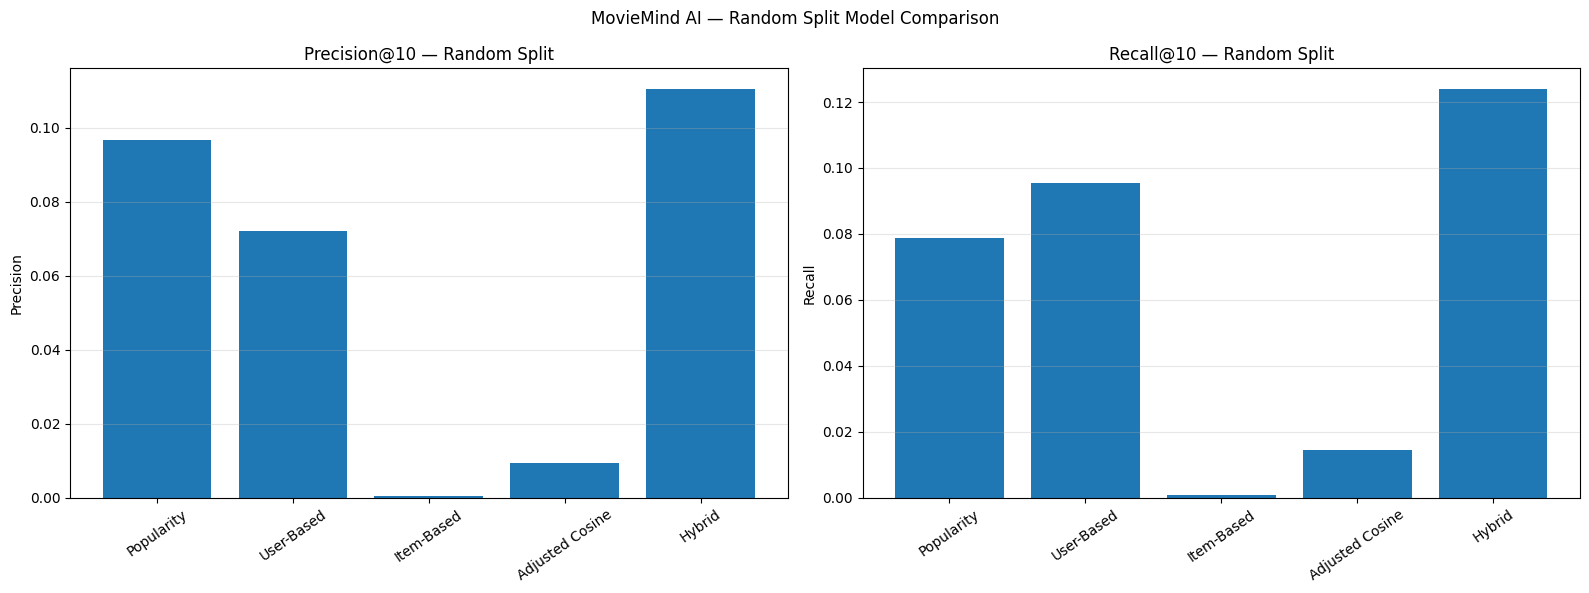

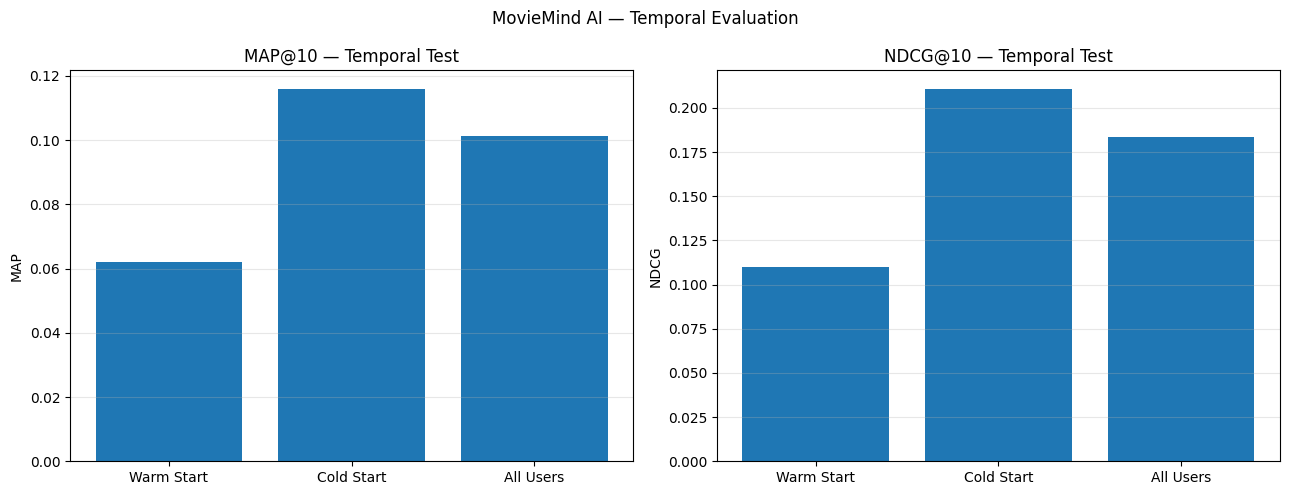

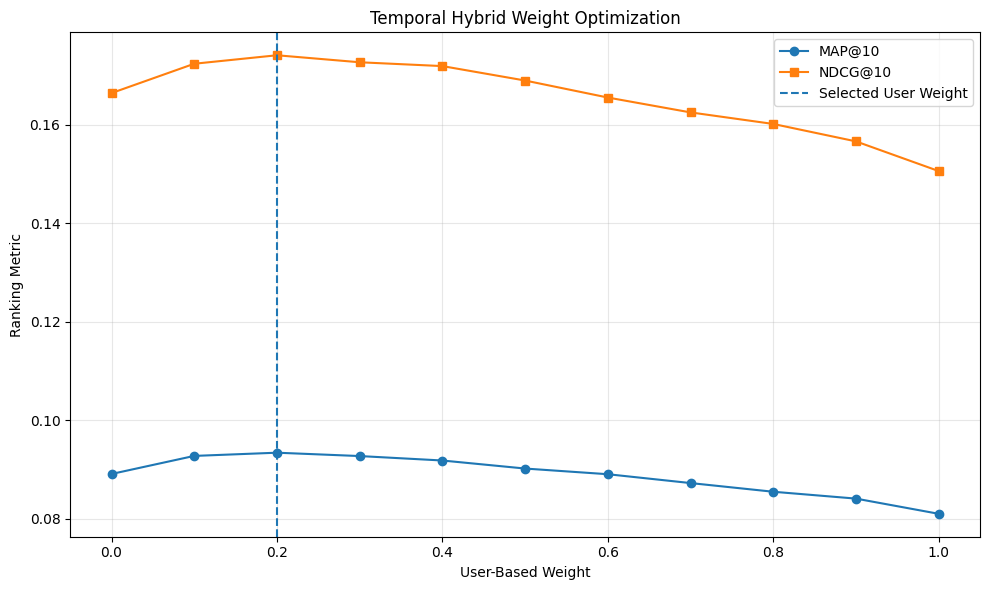

MOVIEMIND AI — VISUALIZATION EXPORT
random_model_comparison.png: 205,529 bytes
temporal_group_comparison.png: 129,369 bytes
temporal_weight_optimization.png: 154,965 bytes

All evaluation visualizations generated successfully.


In [42]:

# ============================================================
# MOVIEMIND AI — EVALUATION VISUALIZATIONS
# ============================================================

import os
import matplotlib.pyplot as plt
import numpy as np

FIGURES_DIR = "outputs/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Random Split Model Comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models = random_results["model"]

axes[0].bar(
    models,
    random_results["precision_at_10"]
)
axes[0].set_title("Precision@10 — Random Split")
axes[0].set_ylabel("Precision")
axes[0].tick_params(axis="x", rotation=35)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    models,
    random_results["recall_at_10"]
)
axes[1].set_title("Recall@10 — Random Split")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis="x", rotation=35)
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle("MovieMind AI — Random Split Model Comparison")
fig.tight_layout()

fig.savefig(
    f"{FIGURES_DIR}/random_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 2. Temporal Test — Warm vs Cold vs All
# ------------------------------------------------------------

temporal_10 = temporal_final_metrics[
    temporal_final_metrics["k"] == 10
].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

groups = temporal_10["group"]

axes[0].bar(
    groups,
    temporal_10["map"]
)
axes[0].set_title("MAP@10 — Temporal Test")
axes[0].set_ylabel("MAP")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    groups,
    temporal_10["ndcg"]
)
axes[1].set_title("NDCG@10 — Temporal Test")
axes[1].set_ylabel("NDCG")
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle("MovieMind AI — Temporal Evaluation")
fig.tight_layout()

fig.savefig(
    f"{FIGURES_DIR}/temporal_group_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 3. Temporal Hybrid Weight Optimization
# ------------------------------------------------------------

weight_results = temporal_weight_results.sort_values(
    "user_weight"
).copy()

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    weight_results["user_weight"],
    weight_results["map_at_10"],
    marker="o",
    label="MAP@10"
)

ax.plot(
    weight_results["user_weight"],
    weight_results["ndcg_at_10"],
    marker="s",
    label="NDCG@10"
)

ax.axvline(
    FINAL_TEMPORAL_USER_WEIGHT,
    linestyle="--",
    label="Selected User Weight"
)

ax.set_title("Temporal Hybrid Weight Optimization")
ax.set_xlabel("User-Based Weight")
ax.set_ylabel("Ranking Metric")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    f"{FIGURES_DIR}/temporal_weight_optimization.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 4. Export Summary
# ------------------------------------------------------------

print("=" * 65)
print("MOVIEMIND AI — VISUALIZATION EXPORT")
print("=" * 65)

for filename in sorted(os.listdir(FIGURES_DIR)):
    filepath = os.path.join(FIGURES_DIR, filename)
    print(f"{filename}: {os.path.getsize(filepath):,} bytes")

print("\nAll evaluation visualizations generated successfully.")


In [43]:

# ============================================================
# MOVIEMIND AI — SVD MATRIX FACTORIZATION
# STEP 1: INSTALLATION
# ============================================================

%pip install scikit-surprise


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 10.3 MB/s  0:00:00


In [44]:

# ============================================================
# MOVIEMIND AI — SVD MATRIX FACTORIZATION
# STEP 2: DATA PREPARATION
# ============================================================

import pandas as pd
import numpy as np

from surprise import Dataset, Reader, SVD
from surprise.model_selection import GridSearchCV

# Required columns
required_columns = {"user_id", "movie_id", "rating"}

for name, df in {
    "hybrid_train": hybrid_train,
    "hybrid_validation": hybrid_validation,
    "test_ratings": test_ratings
}.items():
    missing = required_columns - set(df.columns)
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

# Preserve original data
svd_train_data = hybrid_train[
    ["user_id", "movie_id", "rating"]
].copy()

svd_validation_data = hybrid_validation[
    ["user_id", "movie_id", "rating"]
].copy()

svd_test_data = test_ratings[
    ["user_id", "movie_id", "rating"]
].copy()

# Validate data types and values
for name, df in {
    "Train": svd_train_data,
    "Validation": svd_validation_data,
    "Test": svd_test_data
}.items():

    if df.isnull().any().any():
        raise ValueError(f"{name} contains missing values.")

    if not df["rating"].between(1, 5).all():
        raise ValueError(f"{name} contains ratings outside 1-5.")

    if df.duplicated(["user_id", "movie_id"]).any():
        raise ValueError(f"{name} contains duplicate user-movie pairs.")

# Check train-validation and train-test overlap
train_pairs = set(
    zip(svd_train_data["user_id"], svd_train_data["movie_id"])
)

validation_pairs = set(
    zip(svd_validation_data["user_id"], svd_validation_data["movie_id"])
)

test_pairs = set(
    zip(svd_test_data["user_id"], svd_test_data["movie_id"])
)

assert train_pairs.isdisjoint(validation_pairs)
assert train_pairs.isdisjoint(test_pairs)

# Surprise Reader
reader = Reader(rating_scale=(1, 5))

svd_surprise_train = Dataset.load_from_df(
    svd_train_data,
    reader
).build_full_trainset()

svd_validation_surprise = Dataset.load_from_df(
    svd_validation_data,
    reader
).build_full_trainset()

print("=" * 65)
print("MOVIEMIND AI — SVD DATA PREPARATION")
print("=" * 65)

print(f"Training interactions:   {len(svd_train_data):,}")
print(f"Validation interactions: {len(svd_validation_data):,}")
print(f"Test interactions:       {len(svd_test_data):,}")

print(f"\nTraining users:          {svd_train_data['user_id'].nunique():,}")
print(f"Training movies:         {svd_train_data['movie_id'].nunique():,}")

print(f"Validation users:        {svd_validation_data['user_id'].nunique():,}")
print(f"Validation movies:       {svd_validation_data['movie_id'].nunique():,}")

print(f"\nTrain-validation overlap: {len(train_pairs & validation_pairs)}")
print(f"Train-test overlap:        {len(train_pairs & test_pairs)}")

print("\nData preparation completed successfully.")


MOVIEMIND AI — SVD DATA PREPARATION
Training interactions:   63,921
Validation interactions: 16,446
Test interactions:       19,633

Training users:          943
Training movies:         1,606
Validation users:        943
Validation movies:       1,370

Train-validation overlap: 0
Train-test overlap:        0

Data preparation completed successfully.


In [46]:

# ============================================================
# MOVIEMIND AI — SVD MATRIX FACTORIZATION
# STEP 3: FIXED HYPERPARAMETER OPTIMIZATION
# ============================================================

from surprise import SVD, Dataset, Reader
from surprise.model_selection import GridSearchCV

# Create a Dataset object (GridSearchCV requires Dataset, not Trainset)
svd_tuning_dataset = Dataset.load_from_df(
    svd_train_data[["user_id", "movie_id", "rating"]],
    Reader(rating_scale=(1, 5))
)

# Hyperparameter search space
svd_param_grid = {
    "n_factors": [50, 100, 150],
    "n_epochs": [20, 30],
    "lr_all": [0.002, 0.005],
    "reg_all": [0.02, 0.05]
}

svd_grid_search = GridSearchCV(
    SVD,
    svd_param_grid,
    measures=["rmse"],
    cv=3,
    joblib_verbose=1,
    n_jobs=-1
)

svd_grid_search.fit(svd_tuning_dataset)

# Best configuration
best_svd_params = svd_grid_search.best_params["rmse"]
best_svd_rmse = svd_grid_search.best_score["rmse"]

# Store tuning results
svd_tuning_results = pd.DataFrame(
    svd_grid_search.cv_results
).sort_values("mean_test_rmse")

print("=" * 65)
print("MOVIEMIND AI — SVD HYPERPARAMETER OPTIMIZATION")
print("=" * 65)

print(f"Configurations tested: {len(svd_tuning_results)}")
print(f"Best Cross-Validation RMSE: {best_svd_rmse:.5f}")

print("\nBest Parameters:")
for parameter, value in best_svd_params.items():
    print(f"{parameter}: {value}")

print("\nTop 10 Configurations:")

display(
    svd_tuning_results[
        [
            "param_n_factors",
            "param_n_epochs",
            "param_lr_all",
            "param_reg_all",
            "mean_test_rmse",
            "std_test_rmse"
        ]
    ].head(10).reset_index(drop=True)
)

print("\nHyperparameter optimization completed successfully.")


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   24.1s


MOVIEMIND AI — SVD HYPERPARAMETER OPTIMIZATION
Configurations tested: 24
Best Cross-Validation RMSE: 0.95399

Best Parameters:
n_factors: 50
n_epochs: 30
lr_all: 0.005
reg_all: 0.05

Top 10 Configurations:


[Parallel(n_jobs=-1)]: Done  72 out of  72 | elapsed:   42.3s finished


,param_n_factors,param_n_epochs,param_lr_all,param_reg_all,mean_test_rmse,std_test_rmse
0,50,30,0.005,0.05,0.953993,0.002893
1,50,20,0.005,0.05,0.955668,0.002657
2,150,30,0.005,0.05,0.956283,0.001973
3,100,30,0.005,0.05,0.957018,0.002266
4,100,20,0.005,0.05,0.957754,0.002605
5,50,20,0.005,0.02,0.958682,0.003334
6,150,20,0.005,0.05,0.959732,0.003623
7,50,30,0.002,0.05,0.960037,0.003197
8,50,30,0.002,0.02,0.960182,0.002886
9,100,30,0.002,0.05,0.961844,0.003164



Hyperparameter optimization completed successfully.


In [47]:

# ============================================================
# MOVIEMIND AI — SVD MATRIX FACTORIZATION
# STEP 4: VALIDATION RANKING EVALUATION
# ============================================================

from collections import defaultdict
from surprise import SVD, Reader, Dataset
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Train best SVD model
# ------------------------------------------------------------

svd_validation_model = SVD(
    n_factors=best_svd_params["n_factors"],
    n_epochs=best_svd_params["n_epochs"],
    lr_all=best_svd_params["lr_all"],
    reg_all=best_svd_params["reg_all"],
    random_state=42
)

svd_validation_model.fit(svd_surprise_train)

# ------------------------------------------------------------
# 2. Generate validation predictions
# ------------------------------------------------------------

svd_validation_predictions = []

for row in svd_validation_data.itertuples(index=False):
    prediction = svd_validation_model.predict(
        uid=row.user_id,
        iid=row.movie_id
    )

    svd_validation_predictions.append({
        "user_id": row.user_id,
        "movie_id": row.movie_id,
        "actual_rating": row.rating,
        "predicted_rating": prediction.est
    })

svd_validation_predictions = pd.DataFrame(
    svd_validation_predictions
)

# ------------------------------------------------------------
# 3. Build top-10 recommendations per user
# ------------------------------------------------------------

svd_validation_rankings = {}

for user_id, group in svd_validation_predictions.groupby("user_id"):
    ranked = group.sort_values(
        "predicted_rating",
        ascending=False
    )

    svd_validation_rankings[user_id] = (
        ranked["movie_id"].head(10).tolist()
    )

# ------------------------------------------------------------
# 4. Ground truth: relevant validation movies
# ------------------------------------------------------------

SVD_RELEVANCE_THRESHOLD = 4

svd_validation_relevant = (
    svd_validation_data[
        svd_validation_data["rating"] >= SVD_RELEVANCE_THRESHOLD
    ]
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# ------------------------------------------------------------
# 5. Evaluate ranking metrics
# ------------------------------------------------------------

svd_validation_metrics = []

for k in [5, 10]:

    precision_values = []
    recall_values = []
    map_values = []
    ndcg_values = []
    hit_counts = []

    for user_id, relevant_movies in svd_validation_relevant.items():

        recommendations = svd_validation_rankings.get(
            user_id, []
        )[:k]

        hits = [
            movie_id
            for movie_id in recommendations
            if movie_id in relevant_movies
        ]

        precision = len(hits) / k

        recall = (
            len(hits) / len(relevant_movies)
            if relevant_movies else 0
        )

        ap = calculate_ap_at_k(
            recommendations,
            relevant_movies,
            k
        )

        ndcg = calculate_ndcg_at_k(
            recommendations,
            relevant_movies,
            k
        )

        precision_values.append(precision)
        recall_values.append(recall)
        map_values.append(ap)
        ndcg_values.append(ndcg)
        hit_counts.append(len(hits))

    svd_validation_metrics.append({
        "model": "SVD",
        "k": k,
        "users": len(svd_validation_relevant),
        "precision": np.mean(precision_values),
        "recall": np.mean(recall_values),
        "map": np.mean(map_values),
        "ndcg": np.mean(ndcg_values),
        "average_hits": np.mean(hit_counts)
    })

svd_validation_metrics = pd.DataFrame(
    svd_validation_metrics
)

# ------------------------------------------------------------
# 6. Results
# ------------------------------------------------------------

print("=" * 70)
print("MOVIEMIND AI — SVD VALIDATION RESULTS")
print("=" * 70)

print(f"Training interactions: {len(svd_train_data):,}")
print(f"Validation interactions: {len(svd_validation_data):,}")
print(f"Relevant validation users: {len(svd_validation_relevant):,}")

print("\nBest SVD Parameters:")
print(best_svd_params)

print("\nRanking Metrics:")
display(
    svd_validation_metrics.round(6)
)

print("\nValidation predictions:", len(svd_validation_predictions))
print("Users with recommendations:", len(svd_validation_rankings))
print("\nSVD validation evaluation completed.")


MOVIEMIND AI — SVD VALIDATION RESULTS
Training interactions: 63,921
Validation interactions: 16,446
Relevant validation users: 929

Best SVD Parameters:
{'n_factors': 50, 'n_epochs': 30, 'lr_all': 0.005, 'reg_all': 0.05}

Ranking Metrics:


,model,k,users,precision,recall,map,ndcg,average_hits
0,SVD,5,929,0.705920,0.593059,0.756954,0.829993,3.529602
1,SVD,10,929,0.558019,0.782546,0.761872,0.848998,5.580194



Validation predictions: 16446
Users with recommendations: 943

SVD validation evaluation completed.


In [48]:

# ============================================================
# MOVIEMIND AI — SVD
# STEP 5: REALISTIC CANDIDATE GENERATION
# ============================================================

# Complete movie catalog
svd_all_movie_ids = set(movies["movie_id"].unique())

# Movies already seen by each user during training
svd_seen_by_user = (
    svd_train_data.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# Relevant validation movies (rating >= 4)
svd_validation_relevant = (
    svd_validation_data[
        svd_validation_data["rating"] >= 4
    ]
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# Generate recommendations from unseen catalog movies
svd_validation_realistic_rankings = {}

for user_id in svd_validation_relevant:

    seen_movies = svd_seen_by_user.get(user_id, set())

    candidate_movies = svd_all_movie_ids - seen_movies

    predictions = []

    for movie_id in candidate_movies:
        prediction = svd_validation_model.predict(
            uid=user_id,
            iid=movie_id
        )

        predictions.append(
            (movie_id, prediction.est)
        )

    predictions.sort(
        key=lambda x: x[1],
        reverse=True
    )

    svd_validation_realistic_rankings[user_id] = [
        movie_id for movie_id, score in predictions[:10]
    ]

# Validate recommendation lists
assert all(
    len(recs) == 10
    for recs in svd_validation_realistic_rankings.values()
)

assert all(
    not (set(recs) & svd_seen_by_user.get(user_id, set()))
    for user_id, recs in svd_validation_realistic_rankings.items()
)

print("=" * 65)
print("MOVIEMIND AI — REALISTIC SVD CANDIDATE GENERATION")
print("=" * 65)

print(f"Movie catalog size: {len(svd_all_movie_ids):,}")
print(f"Evaluated users: {len(svd_validation_realistic_rankings):,}")
print(f"Average unseen candidates: {np.mean([
    len(svd_all_movie_ids - svd_seen_by_user.get(user_id, set()))
    for user_id in svd_validation_relevant
]):.2f}")

print("Exactly 10 recommendations per user:",
      all(len(x) == 10 for x in svd_validation_realistic_rankings.values()))

print("No previously watched movies:",
      all(
          not (set(recs) & svd_seen_by_user.get(user_id, set()))
          for user_id, recs in svd_validation_realistic_rankings.items()
      ))

print("\nCandidate generation completed successfully.")


MOVIEMIND AI — REALISTIC SVD CANDIDATE GENERATION
Movie catalog size: 1,682
Evaluated users: 929
Average unseen candidates: 1613.46
Exactly 10 recommendations per user: True
No previously watched movies: True

Candidate generation completed successfully.


In [49]:

# ============================================================
# MOVIEMIND AI — SVD
# STEP 6: REALISTIC RANKING EVALUATION
# ============================================================

svd_realistic_metrics = []

for k in [5, 10]:

    precision_values = []
    recall_values = []
    map_values = []
    ndcg_values = []
    hit_counts = []

    for user_id, relevant_movies in svd_validation_relevant.items():

        recommendations = svd_validation_realistic_rankings[user_id][:k]

        hits = [
            movie_id
            for movie_id in recommendations
            if movie_id in relevant_movies
        ]

        precision_values.append(len(hits) / k)

        recall_values.append(
            len(hits) / len(relevant_movies)
        )

        map_values.append(
            calculate_ap_at_k(
                recommendations,
                relevant_movies,
                k
            )
        )

        ndcg_values.append(
            calculate_ndcg_at_k(
                recommendations,
                relevant_movies,
                k
            )
        )

        hit_counts.append(len(hits))

    svd_realistic_metrics.append({
        "model": "SVD",
        "evaluation": "Realistic Candidate Set",
        "k": k,
        "users": len(svd_validation_relevant),
        "precision": np.mean(precision_values),
        "recall": np.mean(recall_values),
        "map": np.mean(map_values),
        "ndcg": np.mean(ndcg_values),
        "average_hits": np.mean(hit_counts)
    })

svd_realistic_metrics = pd.DataFrame(
    svd_realistic_metrics
)

print("=" * 70)
print("MOVIEMIND AI — REALISTIC SVD VALIDATION METRICS")
print("=" * 70)

display(svd_realistic_metrics.round(6))

print("\nPrevious candidate-restricted metrics (for reference only):")
display(svd_validation_metrics.round(6))

print("\nRealistic ranking evaluation completed.")


MOVIEMIND AI — REALISTIC SVD VALIDATION METRICS


,model,evaluation,k,users,precision,recall,map,ndcg,average_hits
0,SVD,Realistic Candidate Set,5,929,0.053175,0.022201,0.030260,0.056390,0.265877
1,SVD,Realistic Candidate Set,10,929,0.054144,0.049483,0.024418,0.061877,0.541442



Previous candidate-restricted metrics (for reference only):


,model,k,users,precision,recall,map,ndcg,average_hits
0,SVD,5,929,0.705920,0.593059,0.756954,0.829993,3.529602
1,SVD,10,929,0.558019,0.782546,0.761872,0.848998,5.580194



Realistic ranking evaluation completed.


In [50]:

# ============================================================
# MOVIEMIND AI — HYBRID MODEL INSPECTION
# STEP 7: IDENTIFY EXISTING RECOMMENDER FUNCTIONS
# ============================================================

import inspect

keywords = [
    "hybrid",
    "recommend",
    "fuse",
    "popularity",
    "user_based",
    "user_recommend"
]

print("=" * 65)
print("MOVIEMIND AI — AVAILABLE RECOMMENDER FUNCTIONS")
print("=" * 65)

for name, obj in sorted(globals().items()):
    if callable(obj) and any(
        keyword in name.lower() for keyword in keywords
    ):
        try:
            signature = inspect.signature(obj)
        except (ValueError, TypeError):
            signature = "(signature unavailable)"

        print(f"{name}{signature}")


MOVIEMIND AI — AVAILABLE RECOMMENDER FUNCTIONS
evaluate_user_based()
final_hybrid_recommend(user_id, top_n=10)
fuse_rankings(user_rank, popularity_rank, user_weight, popularity_weight, top_n=10)
get_hybrid_popularity_recommendations(user_id, top_n=100)
get_hybrid_user_recommendations(user_id, top_n=100)
recommend_adjusted_item_based(user_id, top_n=10, min_support=2)
recommend_hybrid(user_id, user_weight=0.7, popularity_weight=0.3, top_n=10, rrf_constant=60)
recommend_item_based(user_id, top_n=10, min_support=2)
recommend_item_based_improved(user_id, top_n=10, min_support=2)
recommend_user_based(user_id, n_neighbors=20, top_n=10, min_neighbor_support=2)
temporal_fuse_rankings(user_rank, popularity_rank, user_weight, popularity_weight, top_n=10)
temporal_popularity_recommendations(user_id, top_n=200)
temporal_user_recommendations(user_id, top_n=200)


In [51]:

# ============================================================
# MOVIEMIND AI — FAIR SVD VS HYBRID COMPARISON
# STEP 8: HYBRID CANDIDATE GENERATION
# ============================================================

# Original random-split hybrid weights
COMPARISON_USER_WEIGHT = 0.5
COMPARISON_POPULARITY_WEIGHT = 0.5

hybrid_validation_realistic_rankings = {}

for user_id in svd_validation_relevant:

    seen_movies = svd_seen_by_user.get(user_id, set())
    candidate_movies = svd_all_movie_ids - seen_movies

    # Get component rankings
    user_rank = get_hybrid_user_recommendations(
        user_id,
        top_n=100
    )

    popularity_rank = get_hybrid_popularity_recommendations(
        user_id,
        top_n=100
    )

    # Restrict both component rankings to the same candidate set
    user_rank = [
        movie_id for movie_id in user_rank
        if movie_id in candidate_movies
    ]

    popularity_rank = [
        movie_id for movie_id in popularity_rank
        if movie_id in candidate_movies
    ]

    # Fuse rankings
    hybrid_recommendations = fuse_rankings(
        user_rank,
        popularity_rank,
        user_weight=COMPARISON_USER_WEIGHT,
        popularity_weight=COMPARISON_POPULARITY_WEIGHT,
        top_n=10
    )

    # Keep only valid unseen catalog movies
    hybrid_recommendations = [
        movie_id for movie_id in hybrid_recommendations
        if movie_id in candidate_movies
    ]

    hybrid_validation_realistic_rankings[user_id] = (
        hybrid_recommendations[:10]
    )

# Coverage and validity checks
hybrid_recommendation_lengths = [
    len(recs)
    for recs in hybrid_validation_realistic_rankings.values()
]

hybrid_seen_violations = sum(
    bool(
        set(recs) & svd_seen_by_user.get(user_id, set())
    )
    for user_id, recs in hybrid_validation_realistic_rankings.items()
)

hybrid_catalog_violations = sum(
    bool(set(recs) - svd_all_movie_ids)
    for recs in hybrid_validation_realistic_rankings.values()
)

print("=" * 65)
print("MOVIEMIND AI — HYBRID CANDIDATE GENERATION")
print("=" * 65)

print(f"Evaluated users: {len(hybrid_validation_realistic_rankings):,}")
print(f"User weight: {COMPARISON_USER_WEIGHT}")
print(f"Popularity weight: {COMPARISON_POPULARITY_WEIGHT}")

print(f"Average recommendations/user: {np.mean(hybrid_recommendation_lengths):.2f}")
print(f"Users with 10 recommendations: {sum(x == 10 for x in hybrid_recommendation_lengths)}")
print(f"Previously watched movie violations: {hybrid_seen_violations}")
print(f"Unknown movie violations: {hybrid_catalog_violations}")

assert hybrid_seen_violations == 0
assert hybrid_catalog_violations == 0

print("\nHybrid candidate generation completed.")


MOVIEMIND AI — HYBRID CANDIDATE GENERATION
Evaluated users: 929
User weight: 0.5
Popularity weight: 0.5
Average recommendations/user: 0.00
Users with 10 recommendations: 0
Previously watched movie violations: 0
Unknown movie violations: 0

Hybrid candidate generation completed.


In [52]:

# ============================================================
# MOVIEMIND AI — HYBRID DEBUGGING
# STEP 9: INSPECT RECOMMENDER OUTPUTS
# ============================================================

debug_user_id = next(iter(svd_validation_relevant))

print("=" * 65)
print("HYBRID RECOMMENDER OUTPUT INSPECTION")
print("=" * 65)

print(f"Debug user ID: {debug_user_id}")

print("\n1. User-based recommendations:")
debug_user_rank = get_hybrid_user_recommendations(
    debug_user_id,
    top_n=10
)
print("Type:", type(debug_user_rank))
print("Value:", repr(debug_user_rank)[:1500])
print("Length:", len(debug_user_rank))

print("\n2. Popularity recommendations:")
debug_popularity_rank = get_hybrid_popularity_recommendations(
    debug_user_id,
    top_n=10
)
print("Type:", type(debug_popularity_rank))
print("Value:", repr(debug_popularity_rank)[:1500])
print("Length:", len(debug_popularity_rank))

print("\n3. Hybrid fusion:")
debug_fused = fuse_rankings(
    debug_user_rank,
    debug_popularity_rank,
    user_weight=0.5,
    popularity_weight=0.5,
    top_n=10
)
print("Type:", type(debug_fused))
print("Value:", repr(debug_fused)[:1500])
print("Length:", len(debug_fused))

print("\n4. Original hybrid recommender:")
debug_original_hybrid = recommend_hybrid(
    debug_user_id,
    user_weight=0.5,
    popularity_weight=0.5,
    top_n=10
)
print("Type:", type(debug_original_hybrid))
print("Value:", repr(debug_original_hybrid)[:1500])

print("\n5. Training user exists:",
      debug_user_id in svd_seen_by_user)


HYBRID RECOMMENDER OUTPUT INSPECTION
Debug user ID: 1

1. User-based recommendations:
Type: <class 'pandas.core.frame.DataFrame'>
Value:    movie_id  user_score  support
0       854    5.000000        2
1      1143    5.000000        2
2      1007    5.000000        2
3       189    4.671581        3
4       513    4.660357        3
5      1073    4.642521        3
6        50    4.638237       11
7       512    4.532462        2
8       633    4.508079        2
9       285    4.501957        2
Length: 10

2. Popularity recommendations:
Type: <class 'pandas.core.frame.DataFrame'>
Value:     movie_id  rating_count  average_rating  weighted_rating  \
1        483           158        4.455696         4.351353   
2        318           196        4.428571         4.345096   
3        408            76        4.526316         4.318134   
4         50           357        4.347339         4.303822   
5         12           157        4.401274         4.302491   
6        603           139  

In [53]:

# ============================================================
# MOVIEMIND AI — FIXED HYBRID CANDIDATE GENERATION
# STEP 10
# ============================================================

hybrid_validation_realistic_rankings = {}

for user_id in svd_validation_relevant:

    seen_movies = svd_seen_by_user.get(user_id, set())
    candidate_movies = svd_all_movie_ids - seen_movies

    # Retrieve component recommendations as DataFrames
    user_df = get_hybrid_user_recommendations(
        user_id,
        top_n=200
    )

    popularity_df = get_hybrid_popularity_recommendations(
        user_id,
        top_n=200
    )

    # Convert DataFrames into movie ID rankings
    user_rank = (
        user_df["movie_id"].tolist()
        if isinstance(user_df, pd.DataFrame)
        else list(user_df)
    )

    popularity_rank = (
        popularity_df["movie_id"].tolist()
        if isinstance(popularity_df, pd.DataFrame)
        else list(popularity_df)
    )

    # Exclude movies outside the candidate set
    user_rank = [
        movie_id for movie_id in user_rank
        if movie_id in candidate_movies
    ]

    popularity_rank = [
        movie_id for movie_id in popularity_rank
        if movie_id in candidate_movies
    ]

    # Reciprocal Rank Fusion
    fused = fuse_rankings(
        user_rank,
        popularity_rank,
        user_weight=0.5,
        popularity_weight=0.5,
        top_n=10
    )

    # Validate output type and extract movie IDs
    if isinstance(fused, pd.DataFrame):
        recommendations = fused["movie_id"].tolist()
    else:
        recommendations = list(fused)

    recommendations = [
        movie_id for movie_id in recommendations
        if movie_id in candidate_movies
    ]

    hybrid_validation_realistic_rankings[user_id] = recommendations[:10]


# Validate recommendations
lengths = [
    len(recs)
    for recs in hybrid_validation_realistic_rankings.values()
]

seen_violations = sum(
    bool(set(recs) & svd_seen_by_user.get(user_id, set()))
    for user_id, recs in hybrid_validation_realistic_rankings.items()
)

catalog_violations = sum(
    bool(set(recs) - svd_all_movie_ids)
    for recs in hybrid_validation_realistic_rankings.values()
)

print("=" * 65)
print("MOVIEMIND AI — FIXED HYBRID CANDIDATE GENERATION")
print("=" * 65)

print(f"Evaluated users: {len(lengths):,}")
print(f"Average recommendations/user: {np.mean(lengths):.2f}")
print(f"Users with 10 recommendations: {sum(x == 10 for x in lengths)}")
print(f"Users with fewer than 10: {sum(x < 10 for x in lengths)}")
print(f"Previously watched movie violations: {seen_violations}")
print(f"Unknown movie violations: {catalog_violations}")

assert seen_violations == 0
assert catalog_violations == 0
assert all(x > 0 for x in lengths)

print("\nHybrid candidate generation completed.")


MOVIEMIND AI — FIXED HYBRID CANDIDATE GENERATION
Evaluated users: 929
Average recommendations/user: 10.00
Users with 10 recommendations: 929
Users with fewer than 10: 0
Previously watched movie violations: 0
Unknown movie violations: 0

Hybrid candidate generation completed.


In [54]:

# ============================================================
# MOVIEMIND AI — REALISTIC HYBRID VALIDATION EVALUATION
# STEP 11
# ============================================================

hybrid_realistic_metrics = []

for k in [5, 10]:

    precision_values = []
    recall_values = []
    map_values = []
    ndcg_values = []
    hit_counts = []

    for user_id, relevant_movies in svd_validation_relevant.items():

        recommendations = (
            hybrid_validation_realistic_rankings[user_id][:k]
        )

        hits = [
            movie_id
            for movie_id in recommendations
            if movie_id in relevant_movies
        ]

        precision_values.append(len(hits) / k)

        recall_values.append(
            len(hits) / len(relevant_movies)
        )

        map_values.append(
            calculate_ap_at_k(
                recommendations,
                relevant_movies,
                k
            )
        )

        ndcg_values.append(
            calculate_ndcg_at_k(
                recommendations,
                relevant_movies,
                k
            )
        )

        hit_counts.append(len(hits))

    hybrid_realistic_metrics.append({
        "model": "Hybrid",
        "evaluation": "Realistic Candidate Set",
        "k": k,
        "users": len(svd_validation_relevant),
        "precision": np.mean(precision_values),
        "recall": np.mean(recall_values),
        "map": np.mean(map_values),
        "ndcg": np.mean(ndcg_values),
        "average_hits": np.mean(hit_counts)
    })

hybrid_realistic_metrics = pd.DataFrame(
    hybrid_realistic_metrics
)

print("=" * 70)
print("MOVIEMIND AI — REALISTIC HYBRID VALIDATION METRICS")
print("=" * 70)

display(hybrid_realistic_metrics.round(6))

print("\nHybrid evaluation completed successfully.")


MOVIEMIND AI — REALISTIC HYBRID VALIDATION METRICS


,model,evaluation,k,users,precision,recall,map,ndcg,average_hits
0,Hybrid,Realistic Candidate Set,5,929,0.098170,0.079442,0.067696,0.115943,0.490850
1,Hybrid,Realistic Candidate Set,10,929,0.089666,0.129610,0.064401,0.129712,0.896663



Hybrid evaluation completed successfully.


In [55]:

# ============================================================
# MOVIEMIND AI — FINAL TEST PREPARATION
# STEP 12: INSPECT HYBRID MODEL DEPENDENCIES
# ============================================================

import inspect

functions_to_inspect = [
    get_hybrid_user_recommendations,
    get_hybrid_popularity_recommendations,
    fuse_rankings
]

print("=" * 70)
print("HYBRID FUNCTION IMPLEMENTATIONS")
print("=" * 70)

for function in functions_to_inspect:
    print(f"\n{'=' * 70}")
    print(f"FUNCTION: {function.__name__}")
    print("=" * 70)

    try:
        print(inspect.getsource(function))
    except (OSError, TypeError):
        print("Source code unavailable.")

print("\n" + "=" * 70)
print("DATASET SIZES")
print("=" * 70)

print("Hybrid train:", len(hybrid_train))
print("Hybrid validation:", len(hybrid_validation))
print("Final training candidate:", len(hybrid_train) + len(hybrid_validation))
print("Untouched test:", len(test_ratings))


HYBRID FUNCTION IMPLEMENTATIONS

FUNCTION: get_hybrid_user_recommendations
def get_hybrid_user_recommendations(user_id, top_n=100):

    if user_id not in hybrid_user_item.index:
        return pd.DataFrame(
            columns=["movie_id", "user_score", "support"]
        )

    user_position = hybrid_user_item.index.get_loc(user_id)

    similarities = hybrid_user_similarity[user_position].copy()

    # Exclude the user from their own neighbors
    similarities[user_position] = 0

    neighbor_positions = np.argsort(similarities)[::-1][
        :HYBRID_TOP_NEIGHBORS
    ]

    neighbor_weights = similarities[neighbor_positions]

    positive_mask = neighbor_weights > 0
    neighbor_positions = neighbor_positions[positive_mask]
    neighbor_weights = neighbor_weights[positive_mask]

    if len(neighbor_positions) == 0:
        return pd.DataFrame(
            columns=["movie_id", "user_score", "support"]
        )

    neighbor_ratings = hybrid_user_item_filled.iloc[
        neighbor_

In [56]:

# ============================================================
# MOVIEMIND AI — FINAL HYBRID REFIT
# STEP 13
# ============================================================

from sklearn.metrics.pairwise import cosine_similarity

# Combine training and validation only
final_hybrid_train = pd.concat(
    [hybrid_train, hybrid_validation],
    ignore_index=True
)

# Verify data integrity
assert not final_hybrid_train.duplicated(
    subset=["user_id", "movie_id"]
).any()

assert len(
    set(zip(final_hybrid_train["user_id"], final_hybrid_train["movie_id"]))
    &
    set(zip(test_ratings["user_id"], test_ratings["movie_id"]))
) == 0

# Rebuild user-item matrix
hybrid_user_item = final_hybrid_train.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
)

hybrid_user_item_filled = hybrid_user_item.fillna(0)

# Rebuild user similarity matrix
hybrid_user_similarity = cosine_similarity(
    hybrid_user_item_filled.to_numpy(dtype=np.float32)
)

# Rebuild popularity ranking
hybrid_popularity = (
    final_hybrid_train
    .groupby("movie_id")
    .agg(
        rating_count=("rating", "count"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

HYBRID_GLOBAL_MEAN = final_hybrid_train["rating"].mean()
HYBRID_MIN_RATINGS = 20

hybrid_popularity["weighted_rating"] = (
    (
        hybrid_popularity["rating_count"]
        / (
            hybrid_popularity["rating_count"]
            + HYBRID_MIN_RATINGS
        )
    )
    * hybrid_popularity["average_rating"]
    +
    (
        HYBRID_MIN_RATINGS
        / (
            hybrid_popularity["rating_count"]
            + HYBRID_MIN_RATINGS
        )
    )
    * HYBRID_GLOBAL_MEAN
)

hybrid_popularity = (
    hybrid_popularity
    .merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )
    .sort_values(
        ["weighted_rating", "rating_count"],
        ascending=False
    )
    .reset_index(drop=True)
)

# Verify rebuilt model
print("=" * 70)
print("MOVIEMIND AI — FINAL HYBRID REFIT")
print("=" * 70)

print(f"Final training interactions: {len(final_hybrid_train):,}")
print(f"Training users: {hybrid_user_item.shape[0]:,}")
print(f"Training movies: {hybrid_user_item.shape[1]:,}")
print(f"Similarity matrix: {hybrid_user_similarity.shape}")
print(f"Popularity candidates: {len(hybrid_popularity):,}")
print(f"Training global mean: {HYBRID_GLOBAL_MEAN:.4f}")
print(f"Untouched test interactions: {len(test_ratings):,}")

assert hybrid_user_similarity.shape == (
    hybrid_user_item.shape[0],
    hybrid_user_item.shape[0]
)

assert hybrid_popularity["weighted_rating"].notna().all()

print("\nFinal Hybrid model refitted successfully.")
print("Test data was not used during fitting.")


MOVIEMIND AI — FINAL HYBRID REFIT
Final training interactions: 80,367
Training users: 943
Training movies: 1,650
Similarity matrix: (943, 943)
Popularity candidates: 1,650
Training global mean: 3.5290
Untouched test interactions: 19,633

Final Hybrid model refitted successfully.
Test data was not used during fitting.


In [57]:

# ============================================================
# MOVIEMIND AI — FINAL HYBRID TEST RECOMMENDATIONS
# STEP 14
# ============================================================

FINAL_USER_WEIGHT = 0.5
FINAL_POPULARITY_WEIGHT = 0.5
FINAL_TOP_N = 10

# Relevant test movies: rating >= 4
final_test_relevant = (
    test_ratings[test_ratings["rating"] >= 4]
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

final_test_rankings = {}

for user_id in final_test_relevant:

    # Generate component recommendations
    user_df = get_hybrid_user_recommendations(
        user_id,
        top_n=200
    )

    popularity_df = get_hybrid_popularity_recommendations(
        user_id,
        top_n=200
    )

    user_rank = (
        user_df["movie_id"].tolist()
        if isinstance(user_df, pd.DataFrame)
        else list(user_df)
    )

    popularity_rank = (
        popularity_df["movie_id"].tolist()
        if isinstance(popularity_df, pd.DataFrame)
        else list(popularity_df)
    )

    # Reciprocal Rank Fusion
    recommendations = fuse_rankings(
        user_rank,
        popularity_rank,
        user_weight=FINAL_USER_WEIGHT,
        popularity_weight=FINAL_POPULARITY_WEIGHT,
        top_n=FINAL_TOP_N
    )

    final_test_rankings[user_id] = recommendations


# Validate recommendations
final_test_lengths = [
    len(recs)
    for recs in final_test_rankings.values()
]

final_seen_by_user = (
    final_hybrid_train
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

seen_violations = sum(
    bool(
        set(recs)
        & final_seen_by_user.get(user_id, set())
    )
    for user_id, recs in final_test_rankings.items()
)

unknown_movie_violations = sum(
    bool(set(recs) - set(movies["movie_id"]))
    for recs in final_test_rankings.values()
)

print("=" * 70)
print("MOVIEMIND AI — FINAL HYBRID TEST RECOMMENDATIONS")
print("=" * 70)

print(f"Test users with relevant movies: {len(final_test_relevant):,}")
print(f"Users receiving 10 recommendations: {sum(x == 10 for x in final_test_lengths):,}")
print(f"Average recommendations/user: {np.mean(final_test_lengths):.2f}")
print(f"Previously watched movie violations: {seen_violations}")
print(f"Unknown movie violations: {unknown_movie_violations}")

assert len(final_test_rankings) == len(final_test_relevant)
assert all(x == FINAL_TOP_N for x in final_test_lengths)
assert seen_violations == 0
assert unknown_movie_violations == 0

print("\nFinal test recommendations generated successfully.")


MOVIEMIND AI — FINAL HYBRID TEST RECOMMENDATIONS
Test users with relevant movies: 928
Users receiving 10 recommendations: 928
Average recommendations/user: 10.00
Previously watched movie violations: 0
Unknown movie violations: 0

Final test recommendations generated successfully.


In [58]:

# ============================================================
# MOVIEMIND AI — FINAL HYBRID TEST EVALUATION
# STEP 15
# ============================================================

final_hybrid_test_metrics = []

for k in [5, 10]:

    precision_values = []
    recall_values = []
    map_values = []
    ndcg_values = []
    hit_counts = []

    for user_id, relevant_movies in final_test_relevant.items():

        recommendations = final_test_rankings[user_id][:k]

        hits = [
            movie_id
            for movie_id in recommendations
            if movie_id in relevant_movies
        ]

        precision_values.append(len(hits) / k)
        recall_values.append(len(hits) / len(relevant_movies))

        map_values.append(
            calculate_ap_at_k(
                recommendations,
                relevant_movies,
                k
            )
        )

        ndcg_values.append(
            calculate_ndcg_at_k(
                recommendations,
                relevant_movies,
                k
            )
        )

        hit_counts.append(len(hits))

    final_hybrid_test_metrics.append({
        "model": "Hybrid",
        "evaluation": "Final Temporal Test",
        "k": k,
        "users": len(final_test_relevant),
        "precision": np.mean(precision_values),
        "recall": np.mean(recall_values),
        "map": np.mean(map_values),
        "ndcg": np.mean(ndcg_values),
        "average_hits": np.mean(hit_counts)
    })

final_hybrid_test_metrics = pd.DataFrame(
    final_hybrid_test_metrics
)

print("=" * 75)
print("MOVIEMIND AI — FINAL HYBRID TEST RESULTS")
print("=" * 75)

display(final_hybrid_test_metrics.round(6))

print("\nEvaluation protocol:")
print("- Training: hybrid_train + hybrid_validation")
print("- Test: test_ratings (untouched during model selection)")
print("- Relevant rating threshold: 4")
print("- Hybrid weights: 50% User-Based + 50% Popularity")
print("- Recommendation cutoff: 5 and 10")

print("\nFinal Hybrid test evaluation completed.")


MOVIEMIND AI — FINAL HYBRID TEST RESULTS


,model,evaluation,k,users,precision,recall,map,ndcg,average_hits
0,Hybrid,Final Temporal Test,5,928,0.118966,0.072799,0.075999,0.130659,0.594828
1,Hybrid,Final Temporal Test,10,928,0.110453,0.123833,0.070155,0.143356,1.104526



Evaluation protocol:
- Training: hybrid_train + hybrid_validation
- Test: test_ratings (untouched during model selection)
- Relevant rating threshold: 4
- Hybrid weights: 50% User-Based + 50% Popularity
- Recommendation cutoff: 5 and 10

Final Hybrid test evaluation completed.


In [59]:

# ============================================================
# MOVIEMIND AI — EVALUATION PROTOCOL AUDIT
# STEP 16
# ============================================================

print("=" * 75)
print("MOVIEMIND AI — EVALUATION PROTOCOL AUDIT")
print("=" * 75)

datasets = {
    "hybrid_train": hybrid_train,
    "hybrid_validation": hybrid_validation,
    "final_hybrid_train": final_hybrid_train,
    "test_ratings": test_ratings,
    "temporal_train": temporal_train,
    "temporal_validation": temporal_validation,
    "temporal_test": temporal_test
}

for name, df in datasets.items():
    print(
        f"{name:24} | "
        f"rows={len(df):6,} | "
        f"users={df['user_id'].nunique():4,} | "
        f"movies={df['movie_id'].nunique():4,}"
    )

print("\n" + "-" * 75)
print("PAIR OVERLAP AUDIT")
print("-" * 75)

def pair_set(df):
    return set(zip(df["user_id"], df["movie_id"]))

checks = [
    ("Hybrid train vs validation",
     pair_set(hybrid_train), pair_set(hybrid_validation)),

    ("Hybrid final train vs random test",
     pair_set(final_hybrid_train), pair_set(test_ratings)),

    ("Temporal train vs validation",
     pair_set(temporal_train), pair_set(temporal_validation)),

    ("Temporal train vs test",
     pair_set(temporal_train), pair_set(temporal_test)),

    ("Temporal validation vs test",
     pair_set(temporal_validation), pair_set(temporal_test))
]

for name, first, second in checks:
    print(f"{name}: {len(first & second):,} overlapping pairs")

print("\n" + "-" * 75)
print("TIMESTAMP AUDIT")
print("-" * 75)

for name in ["temporal_train", "temporal_validation", "temporal_test"]:
    df = datasets[name]
    print(
        f"{name:24} | "
        f"{df['timestamp'].min()} -> {df['timestamp'].max()}"
    )


MOVIEMIND AI — EVALUATION PROTOCOL AUDIT
hybrid_train             | rows=63,921 | users= 943 | movies=1,606
hybrid_validation        | rows=16,446 | users= 943 | movies=1,370
final_hybrid_train       | rows=80,367 | users= 943 | movies=1,650
test_ratings             | rows=19,633 | users= 943 | movies=1,423
temporal_train           | rows=70,001 | users= 674 | movies=1,573
temporal_validation      | rows=14,999 | users= 247 | movies=1,382
temporal_test            | rows=15,000 | users= 226 | movies=1,394

---------------------------------------------------------------------------
PAIR OVERLAP AUDIT
---------------------------------------------------------------------------
Hybrid train vs validation: 0 overlapping pairs
Hybrid final train vs random test: 0 overlapping pairs
Temporal train vs validation: 0 overlapping pairs
Temporal train vs test: 0 overlapping pairs
Temporal validation vs test: 0 overlapping pairs

-----------------------------------------------------------------------

In [60]:

# ============================================================
# MOVIEMIND AI — TEMPORAL HYBRID FINAL REFIT
# STEP 17
# ============================================================

# 1. Combine temporal training and validation
temporal_final_train = pd.concat(
    [temporal_train, temporal_validation],
    ignore_index=True
)

assert not temporal_final_train.duplicated(
    subset=["user_id", "movie_id"]
).any()

assert len(
    pair_set(temporal_final_train) & pair_set(temporal_test)
) == 0

# 2. Build temporal user-item matrix
hybrid_user_item = temporal_final_train.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
)

hybrid_user_item_filled = hybrid_user_item.fillna(0)

# 3. Rebuild user similarity
hybrid_user_similarity = cosine_similarity(
    hybrid_user_item_filled.to_numpy(dtype=np.float32)
)

# 4. Rebuild temporal popularity
HYBRID_GLOBAL_MEAN = temporal_final_train["rating"].mean()
HYBRID_MIN_RATINGS = 20

hybrid_popularity = (
    temporal_final_train
    .groupby("movie_id")
    .agg(
        rating_count=("rating", "count"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

hybrid_popularity["weighted_rating"] = (
    (
        hybrid_popularity["rating_count"]
        / (
            hybrid_popularity["rating_count"]
            + HYBRID_MIN_RATINGS
        )
    ) * hybrid_popularity["average_rating"]
    +
    (
        HYBRID_MIN_RATINGS
        / (
            hybrid_popularity["rating_count"]
            + HYBRID_MIN_RATINGS
        )
    ) * HYBRID_GLOBAL_MEAN
)

hybrid_popularity = (
    hybrid_popularity
    .merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )
    .sort_values(
        ["weighted_rating", "rating_count"],
        ascending=False
    )
    .reset_index(drop=True)
)

# 5. Temporal test relevant items
temporal_final_test_relevant = (
    temporal_test[temporal_test["rating"] >= 4]
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# 6. Seen movies include both train and validation
temporal_seen_by_user = (
    temporal_final_train
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# 7. Use weights selected on temporal validation
TEMPORAL_FINAL_USER_WEIGHT = 0.2
TEMPORAL_FINAL_POPULARITY_WEIGHT = 0.8

temporal_final_hybrid_rankings = {}

for user_id in temporal_final_test_relevant:

    user_df = get_hybrid_user_recommendations(
        user_id,
        top_n=200
    )

    popularity_df = get_hybrid_popularity_recommendations(
        user_id,
        top_n=200
    )

    user_rank = (
        user_df["movie_id"].tolist()
        if isinstance(user_df, pd.DataFrame)
        else list(user_df)
    )

    popularity_rank = (
        popularity_df["movie_id"].tolist()
        if isinstance(popularity_df, pd.DataFrame)
        else list(popularity_df)
    )

    # Ensure recommendations exclude all previously seen movies
    seen = temporal_seen_by_user.get(user_id, set())

    user_rank = [
        movie_id for movie_id in user_rank
        if movie_id not in seen
    ]

    popularity_rank = [
        movie_id for movie_id in popularity_rank
        if movie_id not in seen
    ]

    temporal_final_hybrid_rankings[user_id] = fuse_rankings(
        user_rank,
        popularity_rank,
        user_weight=TEMPORAL_FINAL_USER_WEIGHT,
        popularity_weight=TEMPORAL_FINAL_POPULARITY_WEIGHT,
        top_n=10
    )


# 8. Integrity checks
recommendation_lengths = [
    len(recs)
    for recs in temporal_final_hybrid_rankings.values()
]

seen_violations = sum(
    bool(
        set(recs)
        & temporal_seen_by_user.get(user_id, set())
    )
    for user_id, recs in temporal_final_hybrid_rankings.items()
)

unknown_violations = sum(
    bool(set(recs) - set(movies["movie_id"]))
    for recs in temporal_final_hybrid_rankings.values()
)

print("=" * 75)
print("MOVIEMIND AI — TEMPORAL HYBRID FINAL REFIT")
print("=" * 75)

print(f"Final temporal training rows: {len(temporal_final_train):,}")
print(f"Training users: {hybrid_user_item.shape[0]:,}")
print(f"Training movies: {hybrid_user_item.shape[1]:,}")
print(f"Similarity matrix: {hybrid_user_similarity.shape}")
print(f"Popularity candidates: {len(hybrid_popularity):,}")
print(f"Temporal test users evaluated: {len(temporal_final_test_relevant):,}")
print(f"Users receiving 10 recommendations: {sum(x == 10 for x in recommendation_lengths):,}")
print(f"Average recommendations/user: {np.mean(recommendation_lengths):.2f}")
print(f"Previously seen movie violations: {seen_violations}")
print(f"Unknown movie violations: {unknown_violations}")
print(f"Selected weights: User={TEMPORAL_FINAL_USER_WEIGHT}, Popularity={TEMPORAL_FINAL_POPULARITY_WEIGHT}")

assert all(x == 10 for x in recommendation_lengths)
assert seen_violations == 0
assert unknown_violations == 0

print("\nTemporal Hybrid refit and recommendation generation completed.")


MOVIEMIND AI — TEMPORAL HYBRID FINAL REFIT
Final temporal training rows: 85,000
Training users: 808
Training movies: 1,628
Similarity matrix: (808, 808)
Popularity candidates: 1,628
Temporal test users evaluated: 212
Users receiving 10 recommendations: 212
Average recommendations/user: 10.00
Previously seen movie violations: 0
Unknown movie violations: 0
Selected weights: User=0.2, Popularity=0.8

Temporal Hybrid refit and recommendation generation completed.


In [61]:

# ============================================================
# MOVIEMIND AI — TEMPORAL HYBRID FINAL TEST EVALUATION
# STEP 18
# ============================================================

temporal_final_test_metrics = []

for k in [5, 10]:

    precision_values = []
    recall_values = []
    map_values = []
    ndcg_values = []
    hit_counts = []

    for user_id, relevant_movies in temporal_final_test_relevant.items():

        recommendations = temporal_final_hybrid_rankings[user_id][:k]

        hits = [
            movie_id
            for movie_id in recommendations
            if movie_id in relevant_movies
        ]

        precision_values.append(len(hits) / k)
        recall_values.append(len(hits) / len(relevant_movies))

        map_values.append(
            calculate_ap_at_k(
                recommendations,
                relevant_movies,
                k
            )
        )

        ndcg_values.append(
            calculate_ndcg_at_k(
                recommendations,
                relevant_movies,
                k
            )
        )

        hit_counts.append(len(hits))

    temporal_final_test_metrics.append({
        "model": "Temporal Hybrid",
        "evaluation": "Final Temporal Test",
        "k": k,
        "users": len(temporal_final_test_relevant),
        "precision": np.mean(precision_values),
        "recall": np.mean(recall_values),
        "map": np.mean(map_values),
        "ndcg": np.mean(ndcg_values),
        "average_hits": np.mean(hit_counts)
    })

temporal_final_test_metrics = pd.DataFrame(
    temporal_final_test_metrics
)

print("=" * 75)
print("MOVIEMIND AI — FINAL TEMPORAL HYBRID TEST RESULTS")
print("=" * 75)

display(temporal_final_test_metrics.round(6))

print("\nEvaluation protocol:")
print("- Training: temporal_train + temporal_validation")
print("- Test: temporal_test")
print("- Relevant rating threshold: 4")
print("- User-Based weight: 20%")
print("- Popularity weight: 80%")
print("- Seen movies excluded from both training and validation history")

print("\nTemporal final test evaluation completed.")


MOVIEMIND AI — FINAL TEMPORAL HYBRID TEST RESULTS


,model,evaluation,k,users,precision,recall,map,ndcg,average_hits
0,Temporal Hybrid,Final Temporal Test,5,212,0.141509,0.022230,0.102930,0.151478,0.707547
1,Temporal Hybrid,Final Temporal Test,10,212,0.191509,0.065874,0.105522,0.188903,1.915094



Evaluation protocol:
- Training: temporal_train + temporal_validation
- Test: temporal_test
- Relevant rating threshold: 4
- User-Based weight: 20%
- Popularity weight: 80%
- Seen movies excluded from both training and validation history

Temporal final test evaluation completed.


In [62]:

# ============================================================
# MOVIEMIND AI — SAVE FINAL TEMPORAL RESULTS
# STEP 19
# ============================================================

from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

final_results_path = output_dir / "temporal_final_test_results.csv"

temporal_final_test_metrics.to_csv(
    final_results_path,
    index=False
)

print("=" * 70)
print("FINAL TEMPORAL RESULTS EXPORTED")
print("=" * 70)

print(f"File: {final_results_path}")
print(f"Rows: {len(temporal_final_test_metrics)}")
print(f"Columns: {list(temporal_final_test_metrics.columns)}")
print(f"File size: {final_results_path.stat().st_size:,} bytes")

print("\nSaved results:")
display(
    pd.read_csv(final_results_path).round(6)
)


FINAL TEMPORAL RESULTS EXPORTED
File: outputs/temporal_final_test_results.csv
Rows: 2
Columns: ['model', 'evaluation', 'k', 'users', 'precision', 'recall', 'map', 'ndcg', 'average_hits']
File size: 348 bytes

Saved results:


,model,evaluation,k,users,precision,recall,map,ndcg,average_hits
0,Temporal Hybrid,Final Temporal Test,5,212,0.141509,0.022230,0.102930,0.151478,0.707547
1,Temporal Hybrid,Final Temporal Test,10,212,0.191509,0.065874,0.105522,0.188903,1.915094


In [63]:

# ============================================================
# MOVIEMIND AI — RECOMMENDATION QUALITY METRICS PREPARATION
# STEP 20
# ============================================================

# Training-only movie popularity
quality_movie_counts = (
    temporal_final_train
    .groupby("movie_id")
    .size()
    .to_dict()
)

quality_catalog = set(movies["movie_id"].unique())

quality_recommendation_sets = {
    user_id: list(recommendations)
    for user_id, recommendations
    in temporal_final_hybrid_rankings.items()
}

# Catalog coverage
recommended_movies = set()

for recommendations in quality_recommendation_sets.values():
    recommended_movies.update(recommendations)

catalog_coverage = (
    len(recommended_movies) / len(quality_catalog)
)

# Intra-list diversity using genre Jaccard distance
genre_columns = [
    column for column in movies.columns
    if column not in [
        "movie_id",
        "title",
        "release_date",
        "video_release_date",
        "imdb_url"
    ]
]

movie_genres = (
    movies.set_index("movie_id")[genre_columns]
    .fillna(0)
    .astype(bool)
)

diversity_values = []

for recommendations in quality_recommendation_sets.values():

    pair_distances = []

    for i in range(len(recommendations)):
        for j in range(i + 1, len(recommendations)):

            movie_a = recommendations[i]
            movie_b = recommendations[j]

            if movie_a not in movie_genres.index:
                continue

            if movie_b not in movie_genres.index:
                continue

            genres_a = set(
                movie_genres.columns[
                    movie_genres.loc[movie_a].to_numpy()
                ]
            )

            genres_b = set(
                movie_genres.columns[
                    movie_genres.loc[movie_b].to_numpy()
                ]
            )

            union = genres_a | genres_b

            if not union:
                continue

            jaccard_similarity = (
                len(genres_a & genres_b) / len(union)
            )

            pair_distances.append(
                1 - jaccard_similarity
            )

    if pair_distances:
        diversity_values.append(np.mean(pair_distances))

intra_list_diversity = np.mean(diversity_values)

# Novelty using training popularity
total_training_interactions = len(temporal_final_train)

novelty_values = []

for recommendations in quality_recommendation_sets.values():

    movie_surprisals = []

    for movie_id in recommendations:

        count = quality_movie_counts.get(movie_id, 0)

        if count > 0:
            movie_probability = (
                count / total_training_interactions
            )

            movie_surprisals.append(
                -np.log2(movie_probability)
            )

    if movie_surprisals:
        novelty_values.append(np.mean(movie_surprisals))

mean_novelty = np.mean(novelty_values)

# Results
temporal_quality_metrics = pd.DataFrame([{
    "model": "Temporal Hybrid",
    "users": len(quality_recommendation_sets),
    "catalog_size": len(quality_catalog),
    "unique_recommended_movies": len(recommended_movies),
    "catalog_coverage": catalog_coverage,
    "intra_list_diversity": intra_list_diversity,
    "mean_novelty_bits": mean_novelty
}])

print("=" * 75)
print("MOVIEMIND AI — RECOMMENDATION QUALITY METRICS")
print("=" * 75)

display(temporal_quality_metrics.round(6))

print("\nMetric definitions:")
print("- Catalog Coverage: unique recommended movies / full catalog")
print("- Diversity: average pairwise genre Jaccard distance")
print("- Novelty: average self-information from training popularity")

assert 0 <= catalog_coverage <= 1
assert 0 <= intra_list_diversity <= 1
assert np.isfinite(mean_novelty)

print("\nRecommendation quality metrics calculated.")


MOVIEMIND AI — RECOMMENDATION QUALITY METRICS


,model,users,catalog_size,unique_recommended_movies,catalog_coverage,intra_list_diversity,mean_novelty_bits
0,Temporal Hybrid,212,1682,49,0.029132,0.825946,8.744775



Metric definitions:
- Catalog Coverage: unique recommended movies / full catalog
- Diversity: average pairwise genre Jaccard distance
- Novelty: average self-information from training popularity

Recommendation quality metrics calculated.


In [64]:

# ============================================================
# MOVIEMIND AI — RECOMMENDATION DISTRIBUTION AUDIT
# STEP 21
# ============================================================

from collections import Counter

recommendation_counts = Counter(
    movie_id
    for recommendations in temporal_final_hybrid_rankings.values()
    for movie_id in recommendations
)

distribution_df = pd.DataFrame(
    recommendation_counts.items(),
    columns=["movie_id", "recommendation_count"]
)

distribution_df = (
    distribution_df
    .merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )
    .merge(
        hybrid_popularity[
            ["movie_id", "rating_count", "weighted_rating"]
        ],
        on="movie_id",
        how="left"
    )
    .sort_values(
        "recommendation_count",
        ascending=False
    )
    .reset_index(drop=True)
)

distribution_df["recommendation_share"] = (
    distribution_df["recommendation_count"]
    / len(temporal_final_hybrid_rankings)
)

total_recommendations = sum(recommendation_counts.values())

top_10_share = (
    distribution_df.head(10)["recommendation_count"].sum()
    / total_recommendations
)

top_20_share = (
    distribution_df.head(20)["recommendation_count"].sum()
    / total_recommendations
)

print("=" * 75)
print("MOVIEMIND AI — RECOMMENDATION DISTRIBUTION")
print("=" * 75)

print(f"Total recommendations: {total_recommendations:,}")
print(f"Unique recommended movies: {len(distribution_df):,}")
print(f"Top 10 movies share: {top_10_share:.2%}")
print(f"Top 20 movies share: {top_20_share:.2%}")

print("\nMost frequently recommended movies:")
display(distribution_df.head(15).round(4))

print("\nRecommendation frequency statistics:")
display(
    distribution_df["recommendation_count"]
    .describe()
    .to_frame("recommendation_count")
    .round(3)
)

print("\nDistribution audit completed.")


MOVIEMIND AI — RECOMMENDATION DISTRIBUTION
Total recommendations: 2,120
Unique recommended movies: 49
Top 10 movies share: 83.58%
Top 20 movies share: 93.92%

Most frequently recommended movies:


,movie_id,recommendation_count,title,rating_count,weighted_rating,recommendation_share
0,408,192,"Close Shave, A (1995)",95,4.3514,0.9057
1,169,189,"Wrong Trousers, The (1993)",99,4.3480,0.8915
2,483,188,Casablanca (1942),197,4.3936,0.8868
3,603,181,Rear Window (1954),167,4.2589,0.8538
4,318,181,Schindler's List (1993),253,4.3788,0.8538
5,64,175,"Shawshank Redemption, The (1994)",253,4.4008,0.8255
6,12,175,"Usual Suspects, The (1995)",237,4.3051,0.8255
7,98,166,"Silence of the Lambs, The (1991)",333,4.2561,0.7830
8,313,165,Titanic (1997),249,4.2841,0.7783
9,50,160,Star Wars (1977),506,4.3183,0.7547



Recommendation frequency statistics:


,recommendation_count
count,49.000
mean,43.265
std,69.127
min,1.000
25%,3.000
50%,11.000
75%,25.000
max,192.000



Distribution audit completed.


In [65]:

# ============================================================
# MOVIEMIND AI — MMR PREPARATION AUDIT
# STEP 22
# ============================================================

audit_user_id = next(iter(temporal_final_test_relevant))

audit_user_df = get_hybrid_user_recommendations(
    audit_user_id,
    top_n=200
)

audit_popularity_df = get_hybrid_popularity_recommendations(
    audit_user_id,
    top_n=200
)

audit_user_rank = audit_user_df["movie_id"].tolist()
audit_popularity_rank = audit_popularity_df["movie_id"].tolist()

audit_candidates = fuse_rankings(
    audit_user_rank,
    audit_popularity_rank,
    user_weight=0.2,
    popularity_weight=0.8,
    top_n=200
)

print("=" * 75)
print("MOVIEMIND AI — MMR PREPARATION AUDIT")
print("=" * 75)

print(f"Sample user ID: {audit_user_id}")
print(f"User-based candidates: {len(audit_user_rank)}")
print(f"Popularity candidates: {len(audit_popularity_rank)}")
print(f"Unique fused candidates: {len(audit_candidates)}")

print("\nCandidate examples:")
display(
    movies[movies["movie_id"].isin(audit_candidates[:15])]
    [["movie_id", "title"]]
)

print("\nGenre columns:")
print(genre_columns)

print("\nGenre matrix shape:", movie_genres.shape)
print("Movies with at least one genre:",
      int(movie_genres.sum(axis=1).gt(0).sum()))

print("\nCandidate preparation audit completed.")


MOVIEMIND AI — MMR PREPARATION AUDIT
Sample user ID: 4
User-based candidates: 0
Popularity candidates: 200
Unique fused candidates: 200

Candidate examples:


,movie_id,title
11,12,"Usual Suspects, The (1995)"
49,50,Star Wars (1977)
63,64,"Shawshank Redemption, The (1994)"
97,98,"Silence of the Lambs, The (1991)"
126,127,"Godfather, The (1972)"
133,134,Citizen Kane (1941)
168,169,"Wrong Trousers, The (1993)"
173,174,Raiders of the Lost Ark (1981)
312,313,Titanic (1997)
317,318,Schindler's List (1993)



Genre columns:
['unknown', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

Genre matrix shape: (1682, 19)
Movies with at least one genre: 1682

Candidate preparation audit completed.


In [66]:

# ============================================================
# MOVIEMIND AI — DIVERSITY-AWARE MMR RERANKING
# STEP 23
# ============================================================

def genre_jaccard_similarity(movie_a, movie_b):
    """Calculate genre Jaccard similarity between two movies."""

    if movie_a not in movie_genres.index:
        return 0.0

    if movie_b not in movie_genres.index:
        return 0.0

    genres_a = set(
        movie_genres.columns[
            movie_genres.loc[movie_a].to_numpy()
        ]
    )

    genres_b = set(
        movie_genres.columns[
            movie_genres.loc[movie_b].to_numpy()
        ]
    )

    union = genres_a | genres_b

    if not union:
        return 0.0

    return len(genres_a & genres_b) / len(union)


def mmr_rerank(
    ranked_candidates,
    top_n=10,
    lambda_param=0.7
):
    """
    Maximal Marginal Relevance reranking.

    ranked_candidates:
        Ordered list of movie IDs. Earlier movies have
        higher relevance according to the original Hybrid.

    lambda_param:
        1.0 = relevance only
        0.0 = diversity only
    """

    if not 0 <= lambda_param <= 1:
        raise ValueError("lambda_param must be between 0 and 1.")

    candidates = list(dict.fromkeys(ranked_candidates))

    if not candidates or top_n <= 0:
        return []

    # Convert original ranking to normalized relevance scores.
    candidate_count = len(candidates)

    relevance_scores = {
        movie_id: (
            (candidate_count - rank) / candidate_count
        )
        for rank, movie_id in enumerate(candidates)
    }

    selected = []
    remaining = candidates.copy()

    while remaining and len(selected) < top_n:

        best_movie = None
        best_score = float("-inf")

        for candidate in remaining:

            relevance = relevance_scores[candidate]

            if not selected:
                redundancy = 0.0
            else:
                redundancy = max(
                    genre_jaccard_similarity(
                        candidate,
                        selected_movie
                    )
                    for selected_movie in selected
                )

            mmr_score = (
                lambda_param * relevance
                - (1 - lambda_param) * redundancy
            )

            if mmr_score > best_score:
                best_score = mmr_score
                best_movie = candidate

        selected.append(best_movie)
        remaining.remove(best_movie)

    return selected


# Sanity checks
test_candidates = audit_candidates

mmr_test_results = {}

for lambda_value in [0.3, 0.5, 0.7, 1.0]:

    reranked = mmr_rerank(
        test_candidates,
        top_n=10,
        lambda_param=lambda_value
    )

    mmr_test_results[lambda_value] = reranked

    assert len(reranked) == 10
    assert len(set(reranked)) == 10
    assert set(reranked).issubset(set(test_candidates))

print("=" * 75)
print("MOVIEMIND AI — MMR SANITY CHECK")
print("=" * 75)

for lambda_value, recommendations in mmr_test_results.items():

    titles = (
        movies[movies["movie_id"].isin(recommendations)]
        .set_index("movie_id")["title"]
        .to_dict()
    )

    print(f"\nLambda = {lambda_value}")
    for rank, movie_id in enumerate(recommendations, start=1):
        print(f"{rank:2}. {titles.get(movie_id, 'Unknown')}")

print("\nMMR implementation passed sanity checks.")


MOVIEMIND AI — MMR SANITY CHECK

Lambda = 0.3
 1. Shawshank Redemption, The (1994)
 2. Close Shave, A (1995)
 3. Star Wars (1977)
 4. Hoop Dreams (1994)
 5. Maltese Falcon, The (1941)
 6. High Noon (1952)
 7. Usual Suspects, The (1995)
 8. Casablanca (1942)
 9. Psycho (1960)
10. Rear Window (1954)

Lambda = 0.5
 1. Shawshank Redemption, The (1994)
 2. Close Shave, A (1995)
 3. Star Wars (1977)
 4. Hoop Dreams (1994)
 5. Maltese Falcon, The (1941)
 6. Usual Suspects, The (1995)
 7. Casablanca (1942)
 8. Rear Window (1954)
 9. Godfather, The (1972)
10. Wallace & Gromit: The Best of Aardman Animation (1996)

Lambda = 0.7
 1. Shawshank Redemption, The (1994)
 2. Close Shave, A (1995)
 3. Star Wars (1977)
 4. Usual Suspects, The (1995)
 5. Casablanca (1942)
 6. Hoop Dreams (1994)
 7. Rear Window (1954)
 8. Godfather, The (1972)
 9. Raiders of the Lost Ark (1981)
10. Wallace & Gromit: The Best of Aardman Animation (1996)

Lambda = 1.0
 1. Shawshank Redemption, The (1994)
 2. Casablanca (1942

In [68]:

# ============================================================
# MOVIEMIND AI — VECTORIZED GENRE SIMILARITY
# STEP 25
# ============================================================

# Convert genre matrix to NumPy once
genre_movie_ids = movie_genres.index.to_numpy()
genre_matrix = movie_genres.to_numpy(dtype=np.float32)

genre_id_to_index = {
    movie_id: index
    for index, movie_id in enumerate(genre_movie_ids)
}

# Precompute pairwise Jaccard similarity
intersection = genre_matrix @ genre_matrix.T

genre_counts = genre_matrix.sum(axis=1)

union = (
    genre_counts[:, None]
    + genre_counts[None, :]
    - intersection
)

genre_similarity_matrix = np.divide(
    intersection,
    union,
    out=np.zeros_like(intersection, dtype=np.float32),
    where=union > 0
)

# Fast lookup function
def fast_genre_jaccard_similarity(movie_a, movie_b):

    index_a = genre_id_to_index.get(movie_a)
    index_b = genre_id_to_index.get(movie_b)

    if index_a is None or index_b is None:
        return 0.0

    return float(
        genre_similarity_matrix[index_a, index_b]
    )


# Replace the similarity function used by MMR
genre_jaccard_similarity = fast_genre_jaccard_similarity

# Verify equivalence with the original calculation
similarity_checks = [
    (408, 169),
    (483, 603),
    (318, 64),
    (50, 12)
]

for movie_a, movie_b in similarity_checks:

    old_similarity = (
        len(
            set(movie_genres.columns[
                movie_genres.loc[movie_a].to_numpy()
            ])
            &
            set(movie_genres.columns[
                movie_genres.loc[movie_b].to_numpy()
            ])
        )
        /
        len(
            set(movie_genres.columns[
                movie_genres.loc[movie_a].to_numpy()
            ])
            |
            set(movie_genres.columns[
                movie_genres.loc[movie_b].to_numpy()
            ])
        )
    )

    new_similarity = fast_genre_jaccard_similarity(
        movie_a,
        movie_b
    )

    assert np.isclose(
        old_similarity,
        new_similarity,
        atol=1e-6
    )

print("=" * 75)
print("VECTORIZED GENRE SIMILARITY READY")
print("=" * 75)

print("Genre matrix:", genre_matrix.shape)
print("Similarity matrix:", genre_similarity_matrix.shape)
print("Memory usage:",
      round(genre_similarity_matrix.nbytes / (1024 ** 2), 2),
      "MB")

print("All similarity equivalence checks passed.")


VECTORIZED GENRE SIMILARITY READY
Genre matrix: (1682, 19)
Similarity matrix: (1682, 1682)
Memory usage: 10.79 MB
All similarity equivalence checks passed.


In [69]:

# ============================================================
# MOVIEMIND AI — FAST MMR TEMPORAL TEST EVALUATION
# STEP 26
# ============================================================

MMR_LAMBDA_VALUES = [0.3, 0.5, 0.7, 1.0]
MMR_TOP_N = 10

mmr_rankings_by_lambda = {
    value: {}
    for value in MMR_LAMBDA_VALUES
}

# Generate candidate rankings and rerank
for user_id in temporal_final_test_relevant:

    user_df = get_hybrid_user_recommendations(
        user_id, top_n=200
    )

    popularity_df = get_hybrid_popularity_recommendations(
        user_id, top_n=200
    )

    user_rank = user_df["movie_id"].tolist()
    popularity_rank = popularity_df["movie_id"].tolist()

    seen_movies = temporal_seen_by_user.get(user_id, set())

    user_rank = [
        movie_id for movie_id in user_rank
        if movie_id not in seen_movies
    ]

    popularity_rank = [
        movie_id for movie_id in popularity_rank
        if movie_id not in seen_movies
    ]

    candidates = fuse_rankings(
        user_rank,
        popularity_rank,
        user_weight=0.2,
        popularity_weight=0.8,
        top_n=200
    )

    for lambda_value in MMR_LAMBDA_VALUES:

        mmr_rankings_by_lambda[lambda_value][user_id] = (
            mmr_rerank(
                candidates,
                top_n=MMR_TOP_N,
                lambda_param=lambda_value
            )
        )


# Evaluate all configurations
mmr_evaluation_rows = []

for lambda_value, user_rankings in mmr_rankings_by_lambda.items():

    precision_values = []
    recall_values = []
    ap_values = []
    ndcg_values = []
    diversity_values = []

    recommended_movies = set()

    for user_id, recommendations in user_rankings.items():

        relevant_movies = set(
            temporal_final_test_relevant[user_id]
        )

        hits = [
            int(movie_id in relevant_movies)
            for movie_id in recommendations
        ]

        hit_count = sum(hits)

        precision_values.append(
            hit_count / MMR_TOP_N
        )

        recall_values.append(
            hit_count / len(relevant_movies)
            if relevant_movies else 0
        )

        ap_values.append(
            calculate_ap_at_k(
                recommendations,
                relevant_movies,
                MMR_TOP_N
            )
        )

        ndcg_values.append(
            calculate_ndcg_at_k(
                recommendations,
                relevant_movies,
                MMR_TOP_N
            )
        )

        recommended_movies.update(recommendations)

        # Vectorized pairwise diversity
        indices = [
            genre_id_to_index[movie_id]
            for movie_id in recommendations
            if movie_id in genre_id_to_index
        ]

        if len(indices) >= 2:

            pairwise_similarities = (
                genre_similarity_matrix[np.ix_(indices, indices)]
            )

            upper_triangle = np.triu_indices(
                len(indices),
                k=1
            )

            diversity_values.append(
                1 - pairwise_similarities[upper_triangle].mean()
            )

    mmr_evaluation_rows.append({
        "lambda": lambda_value,
        "users": len(user_rankings),
        "precision@10": np.mean(precision_values),
        "recall@10": np.mean(recall_values),
        "map@10": np.mean(ap_values),
        "ndcg@10": np.mean(ndcg_values),
        "catalog_coverage": (
            len(recommended_movies) / len(quality_catalog)
        ),
        "intra_list_diversity": np.mean(diversity_values),
        "unique_movies": len(recommended_movies)
    })


mmr_evaluation_results = (
    pd.DataFrame(mmr_evaluation_rows)
    .sort_values("lambda", ascending=False)
    .reset_index(drop=True)
)

print("=" * 90)
print("MOVIEMIND AI — FAST MMR TEMPORAL TEST COMPARISON")
print("=" * 90)

display(mmr_evaluation_results.round(6))

# Integrity checks
for lambda_value, rankings in mmr_rankings_by_lambda.items():

    assert len(rankings) == len(temporal_final_test_relevant)

    for user_id, recommendations in rankings.items():

        assert len(recommendations) == MMR_TOP_N
        assert len(set(recommendations)) == MMR_TOP_N

        seen = temporal_seen_by_user.get(user_id, set())

        assert not set(recommendations).intersection(seen)

print("\nAll fast MMR evaluation integrity checks passed.")


MOVIEMIND AI — FAST MMR TEMPORAL TEST COMPARISON


,lambda,users,precision@10,recall@10,map@10,ndcg@10,catalog_coverage,intra_list_diversity,unique_movies
0,1.0,212,0.191509,0.065874,0.105522,0.188903,0.029132,0.825946,49
1,0.7,212,0.164151,0.044650,0.093484,0.165751,0.041023,0.925992,69
2,0.5,212,0.148585,0.038592,0.081562,0.150896,0.043401,0.938900,73
3,0.3,212,0.138679,0.033343,0.077552,0.142930,0.051724,0.951407,87



All fast MMR evaluation integrity checks passed.


In [70]:

# ============================================================
# MOVIEMIND AI — SAVE MMR EXPERIMENT RESULTS
# STEP 27
# ============================================================

import os
import json

os.makedirs("outputs", exist_ok=True)

# Save evaluation comparison
mmr_results_path = "outputs/mmr_temporal_test_results.csv"

mmr_evaluation_results.to_csv(
    mmr_results_path,
    index=False
)

# Save recommendation rankings
mmr_rankings_path = "outputs/mmr_temporal_rankings.json"

serializable_rankings = {
    str(lambda_value): {
        str(user_id): [
            int(movie_id)
            for movie_id in recommendations
        ]
        for user_id, recommendations in rankings.items()
    }
    for lambda_value, rankings in mmr_rankings_by_lambda.items()
}

with open(mmr_rankings_path, "w", encoding="utf-8") as file:
    json.dump(
        serializable_rankings,
        file,
        ensure_ascii=False,
        indent=2
    )

# Save experiment configuration
mmr_config = {
    "experiment": "Diversity-Aware MMR Reranking",
    "evaluation": "Final Temporal Test",
    "users": len(temporal_final_test_relevant),
    "top_n": MMR_TOP_N,
    "lambda_values": MMR_LAMBDA_VALUES,
    "user_weight": 0.2,
    "popularity_weight": 0.8,
    "similarity": "Genre Jaccard",
    "baseline_lambda": 1.0,
    "experimental_balanced_lambda": 0.7
}

mmr_config_path = "outputs/mmr_experiment_config.json"

with open(mmr_config_path, "w", encoding="utf-8") as file:
    json.dump(
        mmr_config,
        file,
        ensure_ascii=False,
        indent=2
    )

print("=" * 75)
print("MMR EXPERIMENT RESULTS SAVED")
print("=" * 75)

for path in [
    mmr_results_path,
    mmr_rankings_path,
    mmr_config_path
]:
    print(f"{path}: {os.path.getsize(path):,} bytes")

print("\nSaved configurations:", len(mmr_rankings_by_lambda))
print("Saved users per configuration:", len(temporal_final_test_relevant))


MMR EXPERIMENT RESULTS SAVED
outputs/mmr_temporal_test_results.csv: 589 bytes
outputs/mmr_temporal_rankings.json: 106,537 bytes
outputs/mmr_experiment_config.json: 330 bytes

Saved configurations: 4
Saved users per configuration: 212


In [71]:

# ============================================================
# MOVIEMIND AI — MODEL ARTIFACTS AUDIT
# STEP 28
# ============================================================

import sys
import pandas as pd
import numpy as np

artifact_candidates = [
    "movies",
    "ratings",
    "temporal_final_train",
    "temporal_final_test_relevant",
    "hybrid_user_item",
    "hybrid_user_similarity",
    "hybrid_popularity",
    "movie_genres",
    "genre_similarity_matrix",
    "genre_id_to_index",
    "mmr_evaluation_results",
    "mmr_rankings_by_lambda",
    "temporal_quality_metrics",
    "temporal_final_test_metrics",
    "final_hybrid_train"
]

print("=" * 90)
print("MOVIEMIND AI — ARTIFACTS AUDIT")
print("=" * 90)

audit_rows = []

for variable_name in artifact_candidates:

    if variable_name not in globals():
        audit_rows.append({
            "variable": variable_name,
            "status": "MISSING",
            "type": None,
            "shape": None,
            "size_mb": None
        })
        continue

    obj = globals()[variable_name]

    shape = getattr(obj, "shape", None)

    try:
        size_bytes = sys.getsizeof(obj)
    except Exception:
        size_bytes = None

    audit_rows.append({
        "variable": variable_name,
        "status": "AVAILABLE",
        "type": type(obj).__name__,
        "shape": str(shape) if shape is not None else None,
        "size_mb": (
            round(size_bytes / (1024 ** 2), 4)
            if size_bytes is not None else None
        )
    })

artifact_audit_df = pd.DataFrame(audit_rows)

display(artifact_audit_df)

print("\nAvailable variables:",
      (artifact_audit_df["status"] == "AVAILABLE").sum())

print("Missing variables:",
      (artifact_audit_df["status"] == "MISSING").sum())

print("\nAudit completed.")


MOVIEMIND AI — ARTIFACTS AUDIT


,variable,status,type,shape,size_mb
0,movies,AVAILABLE,DataFrame,"(1682, 24)",0.6566
1,ratings,AVAILABLE,DataFrame,"(100000, 4)",3.0519
2,temporal_final_train,AVAILABLE,DataFrame,"(85000, 5)",3.2426
3,temporal_final_test_relevant,AVAILABLE,dict,None,0.0089
4,hybrid_user_item,AVAILABLE,DataFrame,"(808, 1628)",10.0736
5,hybrid_user_similarity,AVAILABLE,ndarray,"(808, 808)",2.4906
6,hybrid_popularity,AVAILABLE,DataFrame,"(1628, 5)",0.1624
7,movie_genres,AVAILABLE,DataFrame,"(1682, 19)",0.1064
8,genre_similarity_matrix,AVAILABLE,ndarray,"(1682, 1682)",10.7924
9,genre_id_to_index,AVAILABLE,dict,None,0.0704



Available variables: 15
Missing variables: 0

Audit completed.


In [72]:

# ============================================================
# MOVIEMIND AI — PROJECT ARTIFACT DIRECTORY STRUCTURE
# STEP 29
# ============================================================

import os

project_directories = [
    "moviemind_ai",
    "moviemind_ai/data",
    "moviemind_ai/data/raw",
    "moviemind_ai/artifacts",
    "moviemind_ai/artifacts/hybrid",
    "moviemind_ai/artifacts/mmr",
    "moviemind_ai/evaluation",
    "moviemind_ai/config",
    "moviemind_ai/src",
    "moviemind_ai/outputs"
]

for directory in project_directories:
    os.makedirs(directory, exist_ok=True)

print("=" * 75)
print("MOVIEMIND AI — PROJECT STRUCTURE CREATED")
print("=" * 75)

for directory in project_directories:
    print(f"[OK] {directory}")

print("\nTotal directories:", len(project_directories))


MOVIEMIND AI — PROJECT STRUCTURE CREATED
[OK] moviemind_ai
[OK] moviemind_ai/data
[OK] moviemind_ai/data/raw
[OK] moviemind_ai/artifacts
[OK] moviemind_ai/artifacts/hybrid
[OK] moviemind_ai/artifacts/mmr
[OK] moviemind_ai/evaluation
[OK] moviemind_ai/config
[OK] moviemind_ai/src
[OK] moviemind_ai/outputs

Total directories: 10


In [73]:

# ============================================================
# MOVIEMIND AI — SAVE RAW DATASETS
# STEP 30
# ============================================================

from pathlib import Path
import pandas as pd

raw_dir = Path("moviemind_ai/data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

datasets = {
    "movies.csv": movies,
    "ratings.csv": ratings,
}

saved_files = []

for filename, dataframe in datasets.items():
    file_path = raw_dir / filename

    dataframe.to_csv(file_path, index=False)

    # Verify saved file
    loaded_df = pd.read_csv(file_path)

    assert loaded_df.shape == dataframe.shape, (
        f"Shape mismatch for {filename}: "
        f"{loaded_df.shape} != {dataframe.shape}"
    )

    saved_files.append({
        "file": str(file_path),
        "rows": len(loaded_df),
        "columns": len(loaded_df.columns),
        "size_mb": round(file_path.stat().st_size / (1024 ** 2), 4),
        "status": "VERIFIED"
    })

print("=" * 75)
print("MOVIEMIND AI — RAW DATASETS SAVED")
print("=" * 75)

for item in saved_files:
    print(f"\nFile: {item['file']}")
    print(f"Shape: ({item['rows']}, {item['columns']})")
    print(f"Size: {item['size_mb']} MB")
    print(f"Status: {item['status']}")

print("\nAll raw datasets saved and verified successfully.")


MOVIEMIND AI — RAW DATASETS SAVED

File: moviemind_ai/data/raw/movies.csv
Shape: (1682, 24)
Size: 0.227 MB
Status: VERIFIED

File: moviemind_ai/data/raw/ratings.csv
Shape: (100000, 4)
Size: 1.8875 MB
Status: VERIFIED

All raw datasets saved and verified successfully.


In [74]:

# ============================================================
# MOVIEMIND AI — SAVE HYBRID MODEL ARTIFACTS
# STEP 31
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json

hybrid_dir = Path("moviemind_ai/artifacts/hybrid")
hybrid_dir.mkdir(parents=True, exist_ok=True)

# 1. Save User-Item Matrix
user_item_path = hybrid_dir / "user_item_matrix.parquet"
hybrid_user_item.to_parquet(user_item_path)

# 2. Save User Similarity Matrix
similarity_path = hybrid_dir / "user_similarity.npy"
np.save(similarity_path, hybrid_user_similarity)

# 3. Save Popularity Model
popularity_path = hybrid_dir / "popularity_model.csv"
hybrid_popularity.to_csv(popularity_path, index=False)

# 4. Save ID mappings in exact matrix order
id_mappings = {
    "user_ids": [int(x) for x in hybrid_user_item.index.tolist()],
    "movie_ids": [int(x) for x in hybrid_user_item.columns.tolist()]
}

mapping_path = hybrid_dir / "id_mappings.json"

with open(mapping_path, "w", encoding="utf-8") as file:
    json.dump(id_mappings, file, ensure_ascii=False, indent=2)

# ============================================================
# VERIFY SAVED ARTIFACTS
# ============================================================

loaded_user_item = pd.read_parquet(user_item_path)
loaded_similarity = np.load(similarity_path)
loaded_popularity = pd.read_csv(popularity_path)

with open(mapping_path, "r", encoding="utf-8") as file:
    loaded_mappings = json.load(file)

assert loaded_user_item.shape == hybrid_user_item.shape
assert loaded_similarity.shape == hybrid_user_similarity.shape
assert loaded_popularity.shape == hybrid_popularity.shape

assert loaded_mappings["user_ids"] == [
    int(x) for x in hybrid_user_item.index.tolist()
]

assert loaded_mappings["movie_ids"] == [
    int(x) for x in hybrid_user_item.columns.tolist()
]

assert np.allclose(
    loaded_similarity,
    hybrid_user_similarity,
    equal_nan=True
)

assert loaded_user_item.index.equals(hybrid_user_item.index)
assert loaded_user_item.columns.equals(hybrid_user_item.columns)

print("=" * 75)
print("MOVIEMIND AI — HYBRID ARTIFACTS SAVED")
print("=" * 75)

for path in [
    user_item_path,
    similarity_path,
    popularity_path,
    mapping_path
]:
    print(f"\nFile: {path}")
    print(f"Size: {path.stat().st_size / (1024 ** 2):.4f} MB")
    print("Status: VERIFIED")

print("\nUser-item matrix:", loaded_user_item.shape)
print("User similarity matrix:", loaded_similarity.shape)
print("Popularity records:", len(loaded_popularity))
print("User ID mapping:", len(loaded_mappings["user_ids"]))
print("Movie ID mapping:", len(loaded_mappings["movie_ids"]))

print("\nAll Hybrid Model artifacts saved and verified successfully.")


MOVIEMIND AI — HYBRID ARTIFACTS SAVED

File: moviemind_ai/artifacts/hybrid/user_item_matrix.parquet
Size: 0.9964 MB
Status: VERIFIED

File: moviemind_ai/artifacts/hybrid/user_similarity.npy
Size: 2.4906 MB
Status: VERIFIED

File: moviemind_ai/artifacts/hybrid/popularity_model.csv
Size: 0.0994 MB
Status: VERIFIED

File: moviemind_ai/artifacts/hybrid/id_mappings.json
Size: 0.0214 MB
Status: VERIFIED

User-item matrix: (808, 1628)
User similarity matrix: (808, 808)
Popularity records: 1628
User ID mapping: 808
Movie ID mapping: 1628

All Hybrid Model artifacts saved and verified successfully.


In [75]:

# ============================================================
# MOVIEMIND AI — SAVE GENRE & MMR ARTIFACTS
# STEP 32
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json

mmr_dir = Path("moviemind_ai/artifacts/mmr")
evaluation_dir = Path("moviemind_ai/evaluation")

mmr_dir.mkdir(parents=True, exist_ok=True)
evaluation_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Save Genre Data
# ------------------------------------------------------------

genre_data_path = mmr_dir / "movie_genres.csv"
movie_genres.to_csv(genre_data_path, index=True)

# ------------------------------------------------------------
# 2. Save Genre Similarity Matrix
# ------------------------------------------------------------

genre_similarity_path = mmr_dir / "genre_similarity.npy"
np.save(genre_similarity_path, genre_similarity_matrix)

# ------------------------------------------------------------
# 3. Save Genre ID Mapping
# ------------------------------------------------------------

genre_mapping_path = mmr_dir / "genre_id_to_index.json"

with open(genre_mapping_path, "w", encoding="utf-8") as file:
    json.dump(
        {str(k): int(v) for k, v in genre_id_to_index.items()},
        file,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# 4. Save MMR Evaluation Results
# ------------------------------------------------------------

mmr_results_path = evaluation_dir / "mmr_temporal_test_results.csv"
mmr_evaluation_results.to_csv(mmr_results_path, index=False)

# ------------------------------------------------------------
# 5. Save MMR Rankings
# ------------------------------------------------------------

def convert_keys_to_strings(obj):
    if isinstance(obj, dict):
        return {
            str(k): convert_keys_to_strings(v)
            for k, v in obj.items()
        }
    if isinstance(obj, (list, tuple)):
        return [convert_keys_to_strings(v) for v in obj]
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj

rankings_path = mmr_dir / "mmr_rankings.json"

with open(rankings_path, "w", encoding="utf-8") as file:
    json.dump(
        convert_keys_to_strings(mmr_rankings_by_lambda),
        file,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# 6. Verify Saved Files
# ------------------------------------------------------------

loaded_genres = pd.read_csv(genre_data_path, index_col=0)
loaded_genre_similarity = np.load(genre_similarity_path)

with open(genre_mapping_path, "r", encoding="utf-8") as file:
    loaded_genre_mapping = json.load(file)

with open(rankings_path, "r", encoding="utf-8") as file:
    loaded_rankings = json.load(file)

loaded_mmr_results = pd.read_csv(mmr_results_path)

assert loaded_genres.shape == movie_genres.shape
assert loaded_genre_similarity.shape == genre_similarity_matrix.shape
assert loaded_mmr_results.shape == mmr_evaluation_results.shape

assert np.allclose(
    loaded_genre_similarity,
    genre_similarity_matrix,
    equal_nan=True
)

assert len(loaded_genre_mapping) == len(genre_id_to_index)
assert len(loaded_rankings) == len(mmr_rankings_by_lambda)

# ------------------------------------------------------------
# 7. Report
# ------------------------------------------------------------

print("=" * 75)
print("MOVIEMIND AI — GENRE & MMR ARTIFACTS SAVED")
print("=" * 75)

for path in [
    genre_data_path,
    genre_similarity_path,
    genre_mapping_path,
    mmr_results_path,
    rankings_path
]:
    print(f"\nFile: {path}")
    print(f"Size: {path.stat().st_size / (1024 ** 2):.4f} MB")
    print("Status: VERIFIED")

print("\nGenre matrix:", loaded_genres.shape)
print("Genre similarity matrix:", loaded_genre_similarity.shape)
print("Genre mappings:", len(loaded_genre_mapping))
print("MMR result rows:", len(loaded_mmr_results))
print("MMR ranking configurations:", len(loaded_rankings))

print("\nAll Genre & MMR artifacts saved and verified successfully.")


MOVIEMIND AI — GENRE & MMR ARTIFACTS SAVED

File: moviemind_ai/artifacts/mmr/movie_genres.csv
Size: 0.1872 MB
Status: VERIFIED

File: moviemind_ai/artifacts/mmr/genre_similarity.npy
Size: 10.7924 MB
Status: VERIFIED

File: moviemind_ai/artifacts/mmr/genre_id_to_index.json
Size: 0.0236 MB
Status: VERIFIED

File: moviemind_ai/evaluation/mmr_temporal_test_results.csv
Size: 0.0006 MB
Status: VERIFIED

File: moviemind_ai/artifacts/mmr/mmr_rankings.json
Size: 0.1016 MB
Status: VERIFIED

Genre matrix: (1682, 19)
Genre similarity matrix: (1682, 1682)
Genre mappings: 1682
MMR result rows: 4
MMR ranking configurations: 4

All Genre & MMR artifacts saved and verified successfully.


In [77]:

# ============================================================
# MOVIEMIND AI — EVALUATION VARIABLE DISCOVERY
# STEP 33A
# ============================================================

import pandas as pd

candidate_names = [
    "random_model_results",
    "random_weight_results",
    "temporal_test_results",
    "temporal_weight_results",
    "random_evaluation_results",
    "random_comparison_results",
    "random_results",
    "random_weight_optimization",
    "temporal_evaluation_results",
    "temporal_results",
    "temporal_weight_optimization",
    "temporal_final_test_metrics",
    "temporal_quality_metrics",
    "mmr_evaluation_results"
]

print("=" * 75)
print("MOVIEMIND AI — AVAILABLE EVALUATION VARIABLES")
print("=" * 75)

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        shape = getattr(obj, "shape", None)
        print(f"[AVAILABLE] {name:<35} | {type(obj).__name__:<15} | {shape}")
    else:
        print(f"[MISSING]   {name}")

print("\n" + "=" * 75)
print("ALL DATAFRAME VARIABLES WITH EVALUATION-RELATED NAMES")
print("=" * 75)

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if any(term in name.lower() for term in [
            "result", "evaluation", "metric", "weight", "comparison"
        ]):
            print(f"{name:<40} | shape={obj.shape}")


MOVIEMIND AI — AVAILABLE EVALUATION VARIABLES
[MISSING]   random_model_results
[MISSING]   random_weight_results
[MISSING]   temporal_test_results
[AVAILABLE] temporal_weight_results             | DataFrame       | (11, 10)
[MISSING]   random_evaluation_results
[MISSING]   random_comparison_results
[AVAILABLE] random_results                      | DataFrame       | (5, 5)
[MISSING]   random_weight_optimization
[MISSING]   temporal_evaluation_results
[MISSING]   temporal_results
[MISSING]   temporal_weight_optimization
[AVAILABLE] temporal_final_test_metrics         | DataFrame       | (2, 9)
[AVAILABLE] temporal_quality_metrics            | DataFrame       | (1, 7)
[AVAILABLE] mmr_evaluation_results              | DataFrame       | (4, 9)

ALL DATAFRAME VARIABLES WITH EVALUATION-RELATED NAMES
results_df                               | shape=(1856, 5)
evaluation_summary                       | shape=(2, 4)
user_based_results                       | shape=(1856, 6)
baseline_metrics      

In [78]:

# ============================================================
# MOVIEMIND AI — SAVE EVALUATION & CONFIGURATION
# STEP 33B
# ============================================================

from pathlib import Path
import pandas as pd
import json

evaluation_dir = Path("moviemind_ai/evaluation")
config_dir = Path("moviemind_ai/config")

evaluation_dir.mkdir(parents=True, exist_ok=True)
config_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Verified evaluation artifacts from current notebook
# ------------------------------------------------------------

evaluation_artifacts = {
    "random_results.csv": random_results,
    "random_weight_optimization.csv": weight_results,
    "hybrid_weight_optimization.csv": hybrid_weight_results,
    "temporal_weight_optimization.csv": temporal_weight_results,
    "final_hybrid_test_metrics.csv": final_hybrid_test_metrics,
    "temporal_final_metrics.csv": temporal_final_metrics,
    "temporal_final_test_metrics.csv": temporal_final_test_metrics,
    "temporal_quality_metrics.csv": temporal_quality_metrics,
    "mmr_temporal_test_results.csv": mmr_evaluation_results,
    "svd_tuning_results.csv": svd_tuning_results,
    "svd_validation_metrics.csv": svd_validation_metrics,
    "svd_realistic_metrics.csv": svd_realistic_metrics,
    "hybrid_realistic_metrics.csv": hybrid_realistic_metrics
}

saved_evaluation_files = []

for filename, dataframe in evaluation_artifacts.items():

    if not isinstance(dataframe, pd.DataFrame):
        raise TypeError(f"{filename} is not a DataFrame.")

    file_path = evaluation_dir / filename
    dataframe.to_csv(file_path, index=False)

    loaded_df = pd.read_csv(file_path)

    assert loaded_df.shape == dataframe.shape, (
        f"Shape mismatch in {filename}"
    )

    saved_evaluation_files.append(file_path)

# ------------------------------------------------------------
# 2. Save model configuration
# ------------------------------------------------------------

model_config = {
    "project": "MovieMind AI",
    "dataset": "MovieLens 100K",
    "rating_scale": [1, 5],
    "relevance_threshold": 4,

    "random_evaluation": {
        "strategy": "Per-user random split",
        "training_ratio": 0.80,
        "validation_ratio": 0.20,
        "test_used_for_tuning": False
    },

    "temporal_evaluation": {
        "strategy": "Global chronological split",
        "training_ratio": 0.70,
        "validation_ratio": 0.15,
        "test_ratio": 0.15,
        "final_training": "temporal_train + temporal_validation",
        "test_used_for_tuning": False
    },

    "temporal_hybrid": {
        "user_based_weight": 0.20,
        "popularity_weight": 0.80,
        "rrf_constant": 60,
        "minimum_popularity_ratings": 20
    },

    "svd_experiment": {
        "library": "scikit-surprise",
        "best_parameters": {
            "n_factors": 50,
            "n_epochs": 30,
            "lr_all": 0.005,
            "reg_all": 0.05
        },
        "best_cross_validation_rmse": 0.953993
    },

    "mmr": {
        "similarity": "Genre Jaccard similarity",
        "lambda_values": [0.30, 0.50, 0.70, 1.00],
        "default_lambda": 1.00
    },

    "notes": [
        "Random and temporal evaluation protocols are separate.",
        "Temporal test is excluded from model selection.",
        "MMR introduces a relevance-diversity tradeoff.",
        "Lambda 1.0 preserves the baseline ranking."
    ]
}

config_path = config_dir / "model_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(model_config, file, ensure_ascii=False, indent=2)

# ------------------------------------------------------------
# 3. Verify configuration and saved files
# ------------------------------------------------------------

with open(config_path, "r", encoding="utf-8") as file:
    loaded_config = json.load(file)

assert loaded_config["project"] == "MovieMind AI"
assert loaded_config["temporal_hybrid"]["user_based_weight"] == 0.20
assert loaded_config["temporal_hybrid"]["popularity_weight"] == 0.80

print("=" * 75)
print("MOVIEMIND AI — EVALUATION ARTIFACTS SAVED")
print("=" * 75)

for path in saved_evaluation_files + [config_path]:
    print(f"\nFile: {path}")
    print(f"Size: {path.stat().st_size / (1024 ** 2):.4f} MB")
    print("Status: VERIFIED")

print("\nEvaluation files:", len(saved_evaluation_files))
print("Configuration sections:", len(loaded_config))

print("\nAll evaluation artifacts and configuration saved successfully.")


MOVIEMIND AI — EVALUATION ARTIFACTS SAVED

File: moviemind_ai/evaluation/random_results.csv
Size: 0.0003 MB
Status: VERIFIED

File: moviemind_ai/evaluation/random_weight_optimization.csv
Size: 0.0019 MB
Status: VERIFIED

File: moviemind_ai/evaluation/hybrid_weight_optimization.csv
Size: 0.0014 MB
Status: VERIFIED

File: moviemind_ai/evaluation/temporal_weight_optimization.csv
Size: 0.0019 MB
Status: VERIFIED

File: moviemind_ai/evaluation/final_hybrid_test_metrics.csv
Size: 0.0003 MB
Status: VERIFIED

File: moviemind_ai/evaluation/temporal_final_metrics.csv
Size: 0.0007 MB
Status: VERIFIED

File: moviemind_ai/evaluation/temporal_final_test_metrics.csv
Size: 0.0003 MB
Status: VERIFIED

File: moviemind_ai/evaluation/temporal_quality_metrics.csv
Size: 0.0002 MB
Status: VERIFIED

File: moviemind_ai/evaluation/mmr_temporal_test_results.csv
Size: 0.0006 MB
Status: VERIFIED

File: moviemind_ai/evaluation/svd_tuning_results.csv
Size: 0.0063 MB
Status: VERIFIED

File: moviemind_ai/evaluation/sv

In [79]:

# ============================================================
# MOVIEMIND AI — COMPLETE PROJECT AUDIT
# STEP 34
# ============================================================

from pathlib import Path
import pandas as pd

project_dir = Path("moviemind_ai")

required_files = [
    "data/raw/movies.csv",
    "data/raw/ratings.csv",

    "artifacts/hybrid/user_item_matrix.parquet",
    "artifacts/hybrid/user_similarity.npy",
    "artifacts/hybrid/popularity_model.csv",
    "artifacts/hybrid/id_mappings.json",

    "artifacts/mmr/movie_genres.csv",
    "artifacts/mmr/genre_similarity.npy",
    "artifacts/mmr/genre_id_to_index.json",
    "artifacts/mmr/mmr_rankings.json",

    "evaluation/random_results.csv",
    "evaluation/random_weight_optimization.csv",
    "evaluation/hybrid_weight_optimization.csv",
    "evaluation/temporal_weight_optimization.csv",
    "evaluation/final_hybrid_test_metrics.csv",
    "evaluation/temporal_final_metrics.csv",
    "evaluation/temporal_final_test_metrics.csv",
    "evaluation/temporal_quality_metrics.csv",
    "evaluation/mmr_temporal_test_results.csv",
    "evaluation/svd_tuning_results.csv",
    "evaluation/svd_validation_metrics.csv",
    "evaluation/svd_realistic_metrics.csv",
    "evaluation/hybrid_realistic_metrics.csv",

    "config/model_config.json"
]

audit_rows = []

for relative_path in required_files:
    file_path = project_dir / relative_path

    exists = file_path.is_file()
    size_mb = (
        file_path.stat().st_size / (1024 ** 2)
        if exists else 0
    )

    audit_rows.append({
        "file": relative_path,
        "status": "AVAILABLE" if exists else "MISSING",
        "size_mb": round(size_mb, 4)
    })

audit_df = pd.DataFrame(audit_rows)

print("=" * 90)
print("MOVIEMIND AI — COMPLETE PROJECT AUDIT")
print("=" * 90)

print(audit_df.to_string(index=False))

available_count = (audit_df["status"] == "AVAILABLE").sum()
missing_count = (audit_df["status"] == "MISSING").sum()
total_size = audit_df["size_mb"].sum()

print("\n" + "=" * 90)
print(f"Required files: {len(required_files)}")
print(f"Available files: {available_count}")
print(f"Missing files: {missing_count}")
print(f"Total size: {total_size:.2f} MB")

if missing_count == 0:
    print("\nAUDIT PASSED — ALL REQUIRED ARTIFACTS ARE AVAILABLE.")
else:
    print("\nAUDIT FAILED — SOME REQUIRED FILES ARE MISSING.")

print("=" * 90)

# Save audit report
audit_report_path = project_dir / "project_audit.csv"
audit_df.to_csv(audit_report_path, index=False)

print(f"\nAudit report saved: {audit_report_path}")


MOVIEMIND AI — COMPLETE PROJECT AUDIT
                                       file    status  size_mb
                        data/raw/movies.csv AVAILABLE   0.2270
                       data/raw/ratings.csv AVAILABLE   1.8875
  artifacts/hybrid/user_item_matrix.parquet AVAILABLE   0.9964
       artifacts/hybrid/user_similarity.npy AVAILABLE   2.4906
      artifacts/hybrid/popularity_model.csv AVAILABLE   0.0994
          artifacts/hybrid/id_mappings.json AVAILABLE   0.0214
             artifacts/mmr/movie_genres.csv AVAILABLE   0.1872
         artifacts/mmr/genre_similarity.npy AVAILABLE  10.7924
       artifacts/mmr/genre_id_to_index.json AVAILABLE   0.0236
            artifacts/mmr/mmr_rankings.json AVAILABLE   0.1016
              evaluation/random_results.csv AVAILABLE   0.0003
  evaluation/random_weight_optimization.csv AVAILABLE   0.0019
  evaluation/hybrid_weight_optimization.csv AVAILABLE   0.0014
evaluation/temporal_weight_optimization.csv AVAILABLE   0.0019
   evaluation/fin

In [80]:

# ============================================================
# MOVIEMIND AI — CREATE PROJECT ZIP
# STEP 35
# ============================================================

from pathlib import Path
import zipfile

project_dir = Path("moviemind_ai")
zip_path = Path("MovieMind_AI_Artifacts.zip")

assert project_dir.exists(), "Project directory not found."

excluded_parts = {
    "__pycache__",
    ".ipynb_checkpoints",
    ".git",
    ".venv"
}

included_files = []

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as archive:

    for file_path in project_dir.rglob("*"):

        if not file_path.is_file():
            continue

        if any(part in excluded_parts for part in file_path.parts):
            continue

        archive_name = file_path.as_posix()
        archive.write(file_path, arcname=archive_name)
        included_files.append(archive_name)

# Verify ZIP integrity
with zipfile.ZipFile(zip_path, "r") as archive:
    bad_file = archive.testzip()
    zip_contents = archive.namelist()

assert bad_file is None, f"Corrupted ZIP entry: {bad_file}"
assert len(zip_contents) == len(included_files)

print("=" * 75)
print("MOVIEMIND AI — ZIP EXPORT COMPLETED")
print("=" * 75)

print(f"Files archived: {len(zip_contents)}")
print(f"ZIP size: {zip_path.stat().st_size / (1024 ** 2):.2f} MB")
print(f"Archive: {zip_path}")
print("Integrity check: PASSED")

print("\nFirst 10 archived files:")
for name in zip_contents[:10]:
    print(" -", name)

print("\nProject archive created successfully.")


MOVIEMIND AI — ZIP EXPORT COMPLETED
Files archived: 25
ZIP size: 4.16 MB
Archive: MovieMind_AI_Artifacts.zip
Integrity check: PASSED

First 10 archived files:
 - moviemind_ai/project_audit.csv
 - moviemind_ai/config/model_config.json
 - moviemind_ai/evaluation/hybrid_weight_optimization.csv
 - moviemind_ai/evaluation/random_results.csv
 - moviemind_ai/evaluation/final_hybrid_test_metrics.csv
 - moviemind_ai/evaluation/temporal_weight_optimization.csv
 - moviemind_ai/evaluation/temporal_final_metrics.csv
 - moviemind_ai/evaluation/hybrid_realistic_metrics.csv
 - moviemind_ai/evaluation/svd_realistic_metrics.csv
 - moviemind_ai/evaluation/temporal_quality_metrics.csv

Project archive created successfully.


In [81]:
from google.colab import files

files.download("MovieMind_AI_Artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>